# Meaning of Data columns

| Cột | Ý nghĩa |
|---|---|
| `flow_id` | Mã định danh luồng mạng |
| `src_addr`, `src_port` | IP và cổng của bên khởi tạo luồng |
| `dst_addr`, `dst_port` | IP và cổng của bên nhận |
| `ip_prot` | Mã giao thức IP |
| `timestamp` | Thời điểm xuất hiện gói tin đầu tiên |
| `flow_duration` | Thời gian tồn tại của luồng, tính bằng micro giây |
| `down_up_ratio` | Tỷ lệ lưu lượng chiều xuống so với chiều lên |
| `pkt_len_{max,min,mean,var,std}` | Thống kê kích thước gói tin của cả luồng |
| `bytes_per_s`, `pkt_per_s` | Số byte và số gói tin mỗi giây của cả luồng |
| `fwd_pkt_per_s`, `bwd_pkt_per_s` | Số gói tin mỗi giây theo từng chiều |
| `fwd_pkt_cnt`, `bwd_pkt_cnt` | Số gói tin theo từng chiều |
| `fwd_pkt_len_{tot,max,min,mean,std}` | Thống kê kích thước gói tin chiều đi |
| `bwd_pkt_len_{tot,max,min,mean,std}` | Thống kê kích thước gói tin chiều về |
| `fwd_pkt_hdr_len_{tot,min}`, `bwd_pkt_hdr_len_{tot,min}` | Tổng và giá trị nhỏ nhất của kích thước header gói tin theo từng chiều |
| `fwd_non_empty_pkt_cnt`, `bwd_non_empty_pkt_cnt` | Số gói có ít nhất 1 byte dữ liệu TCP theo từng chiều |
| `iat_{max,min,mean,std}` | Thống kê khoảng thời gian giữa hai gói tin liên tiếp trong cả luồng (*inter-arrival time*) |
| `fwd_iat_{tot,max,min,mean,std}` | Thống kê khoảng thời gian giữa các gói chiều đi |
| `bwd_iat_{tot,max,min,mean,std}` | Thống kê khoảng thời gian giữa các gói chiều về |
| `active_{max,min,mean,std}` | Thống kê thời gian luồng hoạt động trước khi chuyển sang trạng thái rỗi |
| `idle_{max,min,mean,std}` | Thống kê thời gian luồng ở trạng thái rỗi trước khi hoạt động lại |
| `flag_SYN`, `flag_fin`, `flag_rst`, `flag_ack`, `flag_psh`, `flag_urg`, `flag_cwr`, `flag_ece` | Số gói tin có từng cờ TCP tương ứng |
| `fwd_flag_psh`, `bwd_flag_psh`, `fwd_flag_urg`, `bwd_flag_urg` | Số gói có cờ PSH hoặc URG theo từng chiều |
| `fwd_bulk_bytes_mean`, `bwd_bulk_bytes_mean` | Số byte trung bình trong một nhóm gói truyền liên tiếp (*bulk*) |
| `fwd_bulk_pkt_mean`, `bwd_bulk_pkt_mean` | Số gói trung bình trong một bulk |
| `fwd_bulk_rate_mean`, `bwd_bulk_rate_mean` | Tốc độ truyền trung bình trong bulk |
| `fwd_subflow_bytes_mean`, `bwd_subflow_bytes_mean` | Số byte trung bình trong một luồng con |
| `fwd_subflow_pkt_mean`, `bwd_subflow_pkt_mean` | Số gói trung bình trong một luồng con |
| `fwd_tcp_init_win_bytes`, `bwd_tcp_init_win_bytes` | Số byte của cửa sổ TCP ban đầu theo từng chiều |
| `label` | Nhãn phân lớp: lưu lượng bình thường hoặc loại tấn công |

# Import

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
from scipy.stats import f_oneway
import statsmodels.api as sm
from statsmodels.formula.api import ols


from analysis.analyzer import TTTH_Analyzer as Analyzer

pd.set_option('display.max_columns', None)

# Get data

In [2]:
# Trước đó có chạy câu lệnh -> để unzip và lấy nhãn

# cd lycos-ids2017       
# for zip_file in pcap_lycos/*.zip; do unzip -n "$zip_file" -d pcap_lycos; done
# python3 labelling.py

In [3]:
folder_order = "data"

file_list = sorted(
    os.path.join(folder_order, file)
    for file in os.listdir(folder_order)
    if file.endswith('.csv')
)

df_list = []
for file in file_list:
    df_day = pd.read_csv(file)
    df_day['source_day'] = os.path.basename(file).split('-')[0]
    df_list.append(df_day)

df_raw = pd.concat(df_list, ignore_index=True)
del df_list, df_day
columns_raw = [col for col in df_raw.columns if col != 'source_day']
df_raw.head()

,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.0,403.0,0.0,158.333333,31450.099291,177.341758,67.411331,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.0,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.5,403.0,0.0,239.666667,30619.460993,174.984174,102.039585,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.0,8.0,8.0,8.000000,0.000000,0.000000,584.368152,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.0,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,584.368152,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.0,28.0,28.0,28.000000,0.000000,0.000000,6152.248167,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.0,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6152.248167,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.0,68.0,50.0,59.000000,46.153846,6.793662,25.357414,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.0,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.341593e+06,50763066.0,28899219.0,3.983114e+07,1.546007e+07,0,

In [4]:
# Chỉ dự báo xem có bị tấn công hay không
df_raw["is_attack"] = np.where(
    df_raw["label"].str.lower().eq("benign"),
    "safe",
    "attack"
)
df_raw["is_attack"] = df_raw["is_attack"].eq("attack").astype("int8")

print(df_raw["is_attack"].value_counts())

df_raw

is_attack
0    1395675
1     441823
Name: count, dtype: int64


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day,is_attack
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.000,403.0,0.0,158.333333,31450.099291,177.341758,6.741133e+01,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.000,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday,0
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.500,403.0,0.0,239.666667,30619.460993,174.984174,1.020396e+02,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.500,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday,0
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.000,8.0,8.0,8.000000,0.000000,0.000000,5.843682e+02,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.000,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,5.843682e+02,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday,0
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.000,28.0,28.0,28.000000,0.000000,0.000000,6.152248e+03,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.000,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6.152248e+03,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday,0
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.000,68.0,50.0,59.000000,46.153846,6.793662,2.535741e+01,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.000,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.3

In [5]:
# rename_map = {
#     'flow_id': 'Mã luồng',
#     'src_addr': 'IP nguồn',
#     'src_port': 'Cổng nguồn',
#     'dst_addr': 'IP đích',
#     'dst_port': 'Cổng đích',
#     'ip_prot': 'Giao thức IP',
#     'timestamp': 'Thời điểm bắt đầu',
#     'flow_duration': 'Thời lượng luồng (µs)',
#     'down_up_ratio': 'Tỷ lệ chiều xuống / chiều lên',
#     'bytes_per_s': 'Byte mỗi giây',
#     'pkt_per_s': 'Gói mỗi giây',
#     'fwd_pkt_per_s': 'Gói mỗi giây chiều đi',
#     'bwd_pkt_per_s': 'Gói mỗi giây chiều về',
#     'fwd_pkt_cnt': 'Số gói chiều đi',
#     'bwd_pkt_cnt': 'Số gói chiều về',
#     'fwd_non_empty_pkt_cnt': 'Số gói có dữ liệu chiều đi',
#     'bwd_non_empty_pkt_cnt': 'Số gói có dữ liệu chiều về',
#     'fwd_tcp_init_win_bytes': 'Cửa sổ TCP ban đầu chiều đi',
#     'bwd_tcp_init_win_bytes': 'Cửa sổ TCP ban đầu chiều về',
#     'label': 'Nhãn phân lớp',
#     'source_day': 'Ngày nguồn dữ liệu',
#     "is_attack": "Có tấn công"
# }

# for flag in ['SYN', 'fin', 'rst', 'ack', 'psh', 'urg', 'cwr', 'ece']:
#     rename_map[f'flag_{flag}'] = f'Số cờ {flag.upper()}'

# for direction, ten in [('fwd', 'chiều đi'), ('bwd', 'chiều về')]:
#     for flag in ['psh', 'urg']:
#         rename_map[f'{direction}_flag_{flag}'] = f'Số cờ {flag.upper()} {ten}'

# prefix_map = {
#     'pkt_len': 'Kích thước gói toàn luồng',
#     'fwd_pkt_len': 'Kích thước gói chiều đi',
#     'bwd_pkt_len': 'Kích thước gói chiều về',
#     'fwd_pkt_hdr_len': 'Độ dài header chiều đi',
#     'bwd_pkt_hdr_len': 'Độ dài header chiều về',
#     'iat': 'Khoảng thời gian giữa các gói',
#     'fwd_iat': 'Khoảng thời gian giữa các gói chiều đi',
#     'bwd_iat': 'Khoảng thời gian giữa các gói chiều về',
#     'active': 'Thời gian hoạt động',
#     'idle': 'Thời gian rỗi',
#     'fwd_bulk_bytes': 'Số byte mỗi bulk chiều đi',
#     'bwd_bulk_bytes': 'Số byte mỗi bulk chiều về',
#     'fwd_bulk_pkt': 'Số gói mỗi bulk chiều đi',
#     'bwd_bulk_pkt': 'Số gói mỗi bulk chiều về',
#     'fwd_bulk_rate': 'Tốc độ bulk chiều đi',
#     'bwd_bulk_rate': 'Tốc độ bulk chiều về',
#     'fwd_subflow_bytes': 'Số byte mỗi luồng con chiều đi',
#     'bwd_subflow_bytes': 'Số byte mỗi luồng con chiều về',
#     'fwd_subflow_pkt': 'Số gói mỗi luồng con chiều đi',
#     'bwd_subflow_pkt': 'Số gói mỗi luồng con chiều về',
# }

# stat_map = {
#     'tot': 'tổng',
#     'max': 'lớn nhất',
#     'min': 'nhỏ nhất',
#     'mean': 'trung bình',
#     'var': 'phương sai',
#     'std': 'độ lệch chuẩn',
# }

# for prefix, ten_nhom in prefix_map.items():
#     for stat, ten_thong_ke in stat_map.items():
#         col = f'{prefix}_{stat}'
#         if col in df_raw.columns:
#             rename_map[col] = f'{ten_nhom} - {ten_thong_ke}'

# df_vn = df_raw.rename(columns=rename_map)
# df_vn.head()

# df_vn.to_csv('df_vn.csv', index=False)

# Thông tin sơ bộ

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1837498 entries, 0 to 1837497
Data columns (total 85 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   flow_id                 object 
 1   src_addr                object 
 2   src_port                int64  
 3   dst_addr                object 
 4   dst_port                int64  
 5   ip_prot                 int64  
 6   timestamp               int64  
 7   flow_duration           int64  
 8   down_up_ratio           float64
 9   pkt_len_max             float64
 10  pkt_len_min             float64
 11  pkt_len_mean            float64
 12  pkt_len_var             float64
 13  pkt_len_std             float64
 14  bytes_per_s             float64
 15  pkt_per_s               float64
 16  fwd_pkt_per_s           float64
 17  bwd_pkt_per_s           float64
 18  fwd_pkt_cnt             int64  
 19  fwd_pkt_len_tot         int64  
 20  fwd_pkt_len_max         float64
 21  fwd_pkt_len_min         float64

In [7]:
# Kiểm tra null
null_table = pd.DataFrame({
    'Null Count': df_raw.isna().sum(),
    'Null (%)': (df_raw.isna().mean() * 100).round(3)
}).sort_values('Null Count', ascending=False)

null_table

,Null Count,Null (%)
flow_id,0,0.0
idle_max,0,0.0
flag_psh,0,0.0
flag_ack,0,0.0
flag_rst,0,0.0
...,...,...
bwd_pkt_cnt,0,0.0
fwd_non_empty_pkt_cnt,0,0.0
fwd_pkt_hdr_len_min,0,0.0
fwd_pkt_hdr_len_tot,0,0.0


In [8]:
# Kiểm tra trùng
print('Số dòng trùng toàn bộ cột gốc:', int(df_raw.duplicated().sum()))

df_raw[df_raw.duplicated()]

Số dòng trùng toàn bộ cột gốc: 0


,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day,is_attack


In [9]:
print("Các cột kiểu numeric:")
numeric_cols = df_raw.select_dtypes(include='number').columns
print(numeric_cols)

print("\nCác cột kiểu category:")
category_cols = df_raw.select_dtypes(include='object').columns
category_cols = category_cols[category_cols != 'flow_id']
print(category_cols)

Các cột kiểu numeric:
Index(['src_port', 'dst_port', 'ip_prot', 'timestamp', 'flow_duration',
       'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean',
       'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s',
       'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot',
       'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean',
       'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min',
       'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot',
       'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean',
       'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min',
       'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std',
       'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean',
       'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min',
       'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min',
       'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean',
     

In [10]:
inf_count = int(np.isinf(df_raw[numeric_cols].to_numpy()).sum())
print('Số inf', inf_count)

Số inf 0


# EDA

## Target

In [11]:
# Thống kê mô tả
df_raw[['label']].describe()

,label
count,1837498
unique,14
top,benign
freq,1395675


In [12]:
# Phân bố nhãn
label_table = df_raw['label'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
label_table['percent'] = (label_table['count'] / len(df_raw) * 100).round(3)

label_table

,label,count,percent
0,benign,1395675,75.955
1,portscan,160106,8.713
2,dos_hulk,158988,8.652
3,ddos,95683,5.207
4,dos_goldeneye,6765,0.368
5,dos_slowloris,5674,0.309
6,dos_slowhttptest,4866,0.265
7,ftp_patator,4003,0.218
8,ssh_patator,2959,0.161
9,webattack_bruteforce,1360,0.074


In [13]:
# Phân bố nhãn
attack_table = df_raw['is_attack'].value_counts(dropna=False).rename_axis('label').reset_index(name='count')
attack_table['percent'] = (attack_table['count'] / len(df_raw) * 100).round(3)

attack_table

,label,count,percent
0,0,1395675,75.955
1,1,441823,24.045


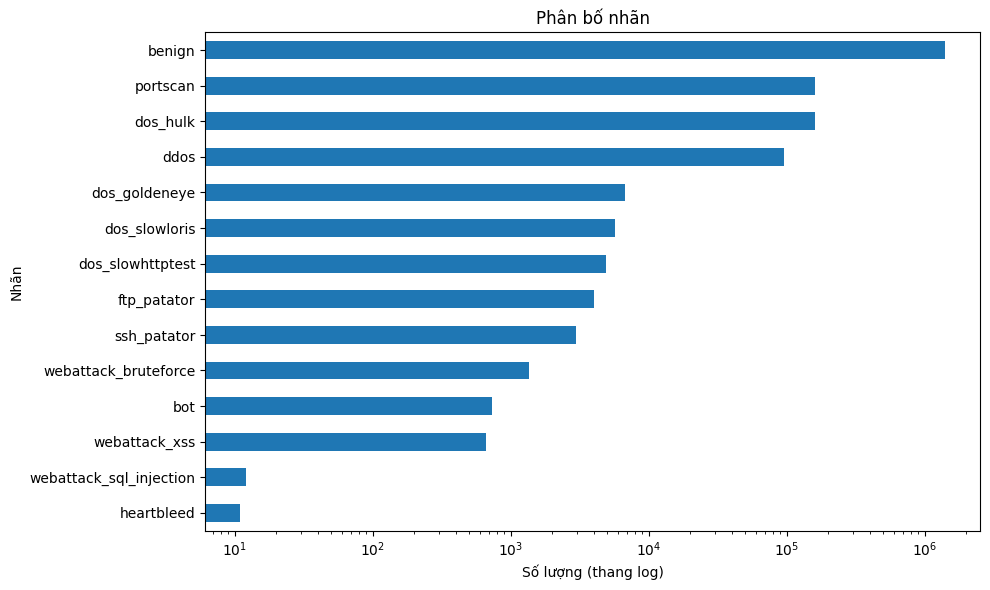

In [14]:
# Kiểm tra phân bổ nhãn
ax = label_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

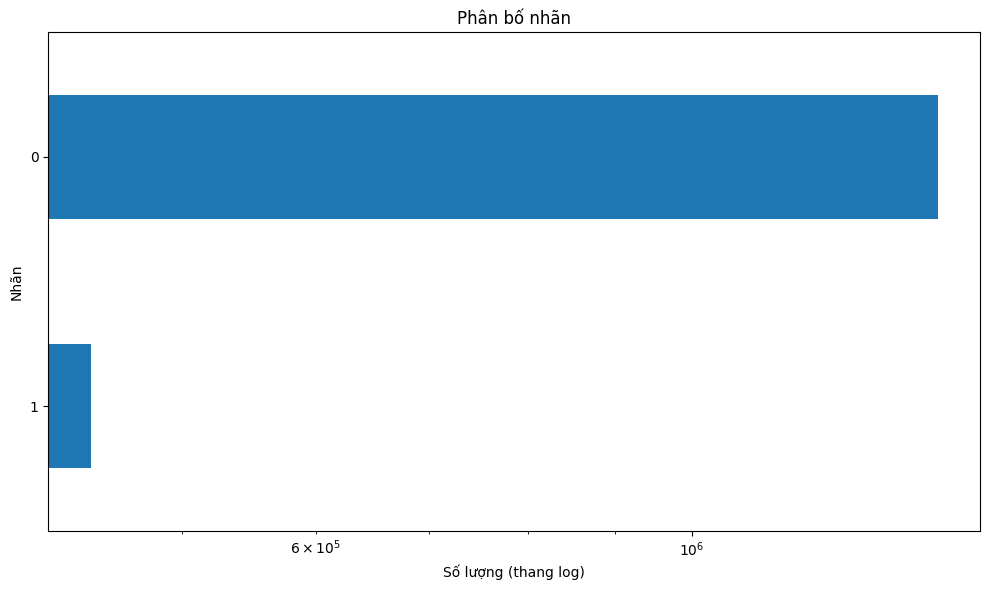

In [15]:
# Kiểm tra phân bổ nhãn
ax = attack_table.sort_values('count').plot.barh(
    x='label',
    y='count',
    figsize=(10, 6),
    legend=False
)

ax.set_xscale('log')
ax.set_title('Phân bố nhãn')
ax.set_xlabel('Số lượng (thang log)')
ax.set_ylabel('Nhãn')

plt.tight_layout()
plt.show()

In [16]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(label_table))
print("Lớp nhiều nhất:", label_table.iloc[0]['label'], "-", label_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", label_table.iloc[-1]['label'], "-", label_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(label_table['count'].max() / label_table['count'].min(), 1))

Số lớp: 14
Lớp nhiều nhất: benign - 1395675 mẫu
Lớp ít nhất: heartbleed - 11 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 126879.5


In [17]:
# Kiểm tra cân bằng lớp
print("Số lớp:", len(attack_table))
print("Lớp nhiều nhất:", attack_table.iloc[0]['label'], "-", attack_table.iloc[0]['count'], "mẫu")
print("Lớp ít nhất:", attack_table.iloc[-1]['label'], "-", attack_table.iloc[-1]['count'], "mẫu")
print("Tỷ lệ lớp lớn nhất / nhỏ nhất:",
      round(attack_table['count'].max() / attack_table['count'].min(), 1))

Số lớp: 2
Lớp nhiều nhất: 0.0 - 1395675.0 mẫu
Lớp ít nhất: 1.0 - 441823.0 mẫu
Tỷ lệ lớp lớn nhất / nhỏ nhất: 3.2


## Features - numeric

In [18]:
# Thống kê mô tả
df_raw.describe(include='number')

,src_port,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,is_attack
count,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1837498.0,1837498.0,1837498.0,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06,1.837498e+06
mean,4.851412e+04,1.016174e+03,1.131388e+01,1.499277e+15,1.199375e+07,1.051375e+00,1.388679e+03,2.117446e+01,3.051886e+02,9.484971e+05,4.775796e+02,5.902847e+05,1.233599e+04,7.515683e+03,4.820309e+03,1.214130e+01,5.751877e+02,2.156581e+02,2.143513e+01,6.066870e+01,7.115022e+01,2.770368e+02,1.793393e+01,2.751816e+00,1.467427e+01,2.396352e+04,1.351654e+03,1.550679e-01,4.759030e+02,5.322375e+02,3.280494e+02,1.684333e+01,1.268193e+01,4.592725e+06,1.820236e+04,8.792799e+05,1.721531e+06,1.163050e+07,4.417167e+06,1.214749e+06,2.005897e+06,1.244304e+06,1.091002e+07,3.891474e+06,1.353950e+06,2.072981e+06,9.999340e+05,1.827067e+05,6.236271e+04,9.085547e+04,5.248137e+04,4.033050e+06,3.658133e+06,3.855138e+06,2.046651e+05,9.387292e-01,3.834197e-01,9.971603e-02,2.442314e+01,3.168392e+00,1.415754e+00,1.752638e+00,0.0,0.0,0.0,4.087079e-04,6.057149e-04,6.775367e+01,2.369940e-01,1.821951e+05,4.215857e+03,2.093305e+00,2.855677e+06,2.681484e+02,6.813951e+00,1.395996e+04,8.270970e+00,1.069511e+04,1.146236e+04,2.404482e-01
std,1.580724e+04,5.216598e+03,5.542912e+00,1.302638e+11,3.091508e+07,4.082071e-01,2.375817e+03,2.643862e+01,4.622562e+02,2.627050e+06,8.487727e+02,8.554230e+06,6.437455e+04,5.069289e+04,2.674976e+04,9.299889e+02,5.453320e+03,4.787516e+02,3.567512e+01,9.875525e+01,1.549067e+02,1.943498e+04,1.079900e+01,6.477690e+00,1.237128e+03,2.807826e+06,2.364553e+03,6.027267e+00,7.377988e+02,1.044318e+03,2.477432e+04,9.914960e+00,1.236598e+03,1.427997e+07,2.505621e+05,3.445050e+06,6.219367e+06,3.078804e+07,1.426006e+07,9.487244e+06,9.758034e+06,4.235076e+06,3.004978e+07,1.377562e+07,9.815013e+06,1.020862e+07,4.199289e+06,1.104878e+06,6.403329e+05,7.130510e+05,4.322259e+05,1.401476e+07,1.336863e+07,1.356828e+07,2.171198e+06,1.059359e+00,4.862193e-01,2.996211e-01,2.166668e+03,2.880648e+01,4.787257e+00,2.694965e+01,0.0,0.0,0.0,2.888114e-02,3.414

In [19]:
# Kiểm tra lệnh
df_num = df_raw.select_dtypes(include='number')

pd.DataFrame({
    'Skew gốc': df_num.skew(),
    'Skew log': np.log1p(df_num).skew()
}).round(4)

,Skew gốc,Skew log
src_port,-1.5805,-4.5697
dst_port,8.5333,1.9178
ip_prot,0.4125,0.0639
timestamp,0.0784,0.0783
flow_duration,2.6760,-0.0658
...,...,...
bwd_subflow_bytes_mean,253.3431,-0.4246
bwd_subflow_pkt_mean,258.9417,1.9901
fwd_tcp_init_win_bytes,1.6645,NaN
bwd_tcp_init_win_bytes,1.0011,NaN


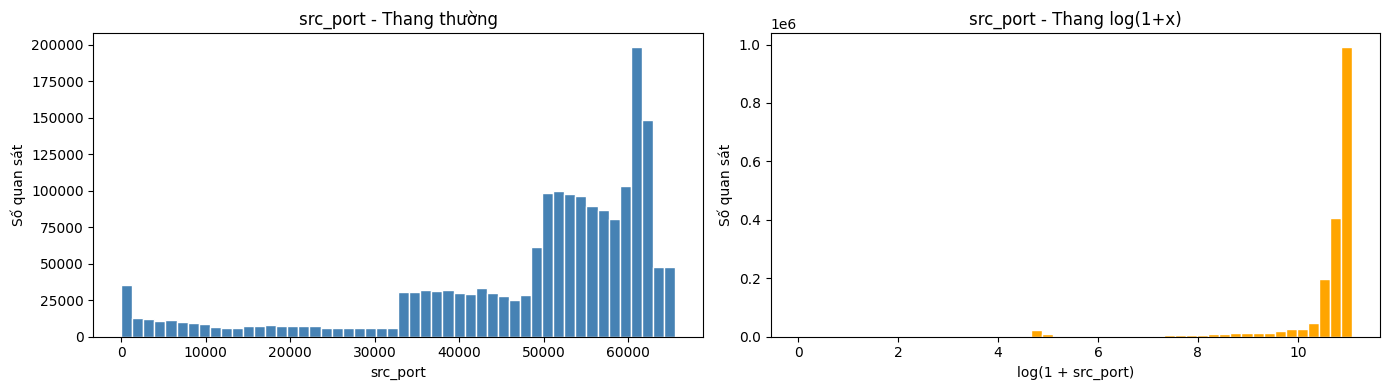

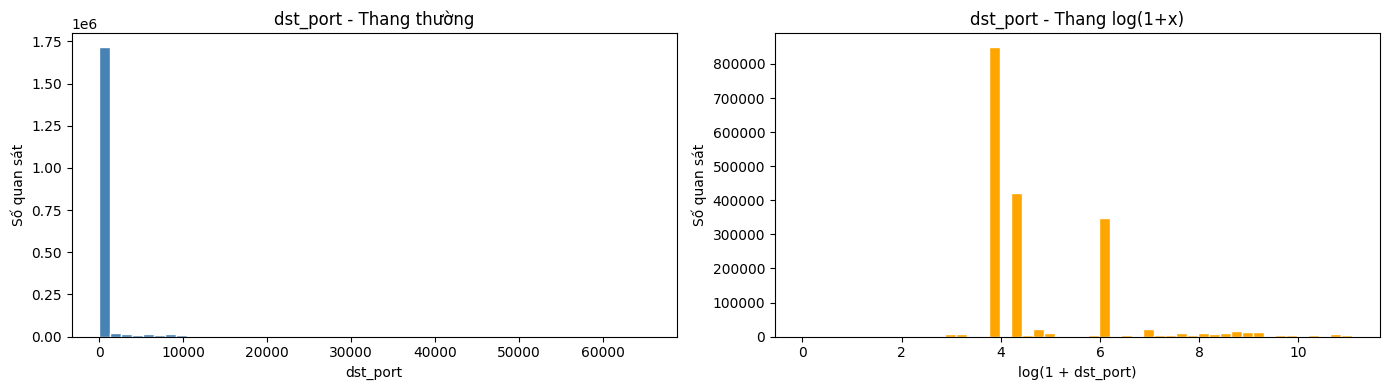

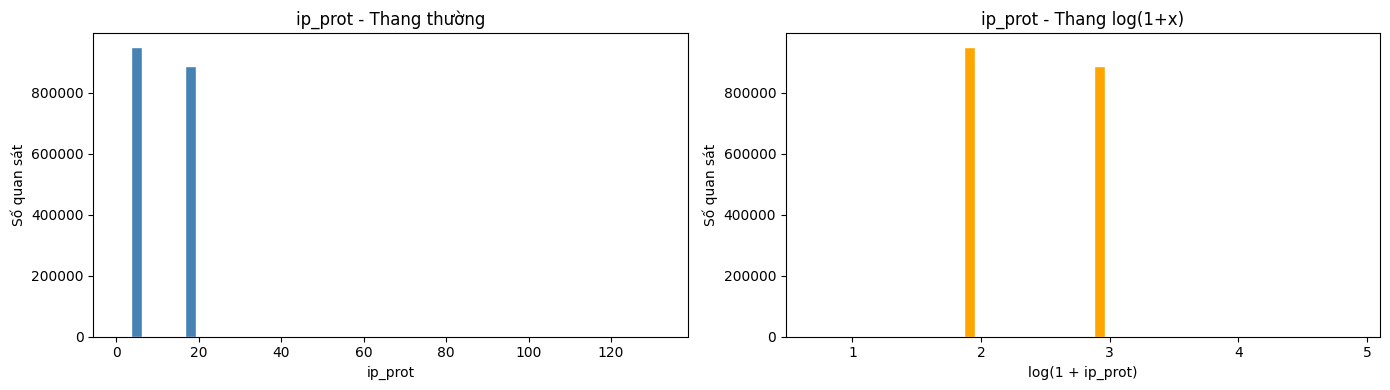

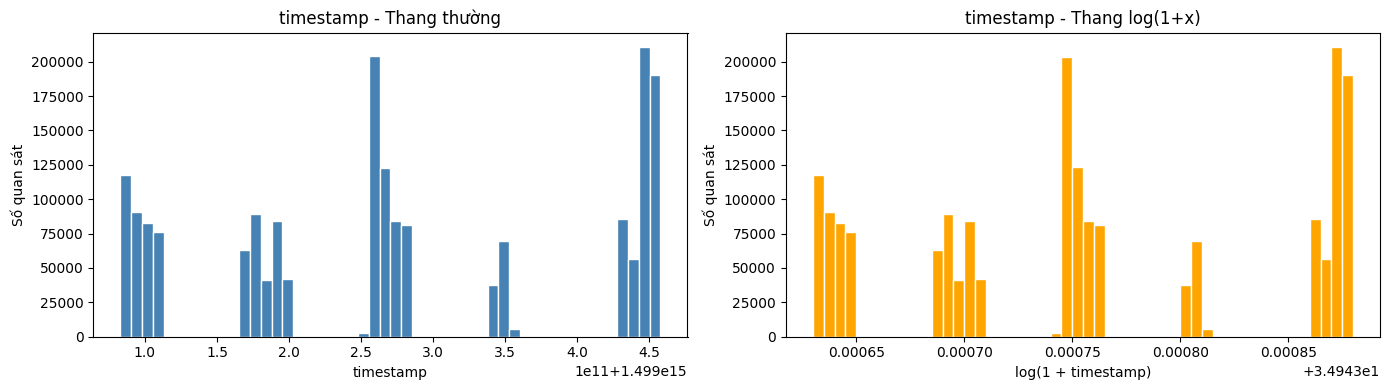

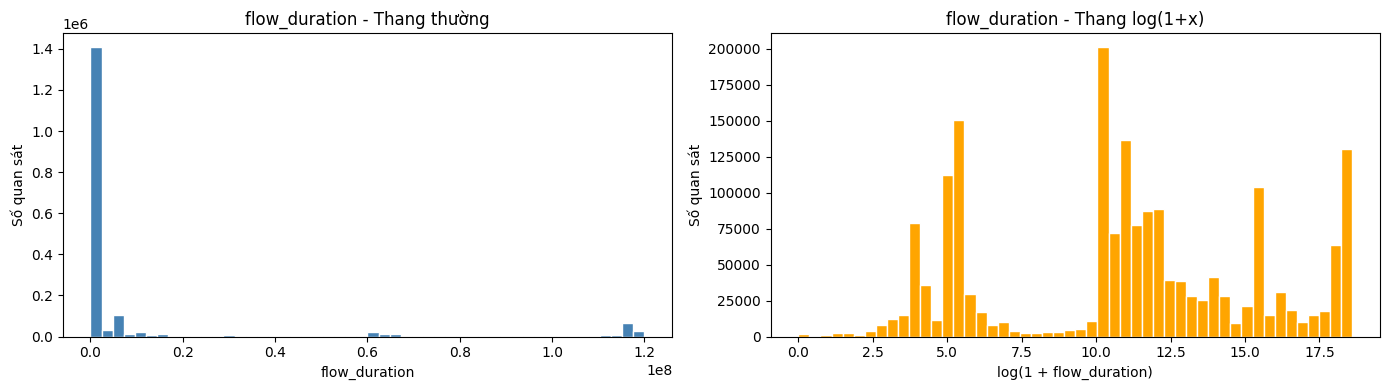

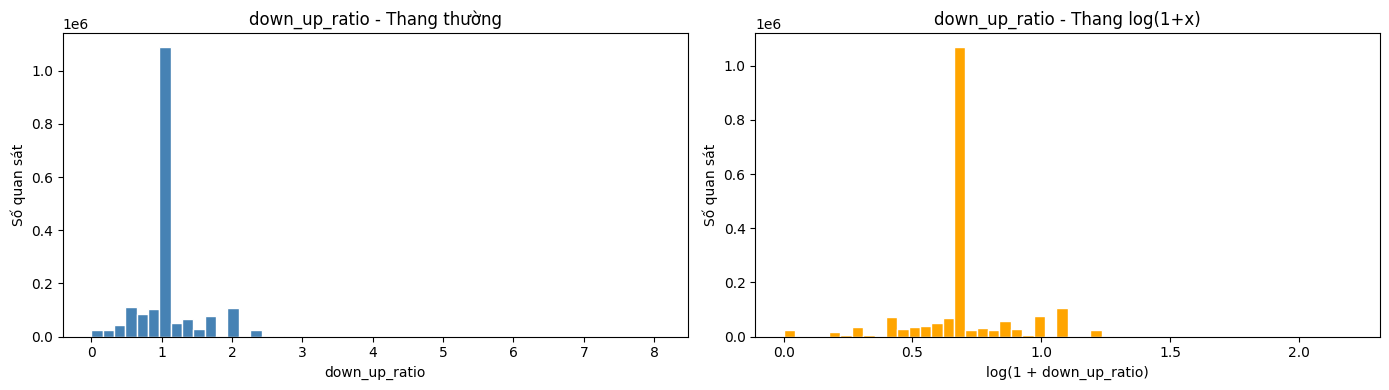

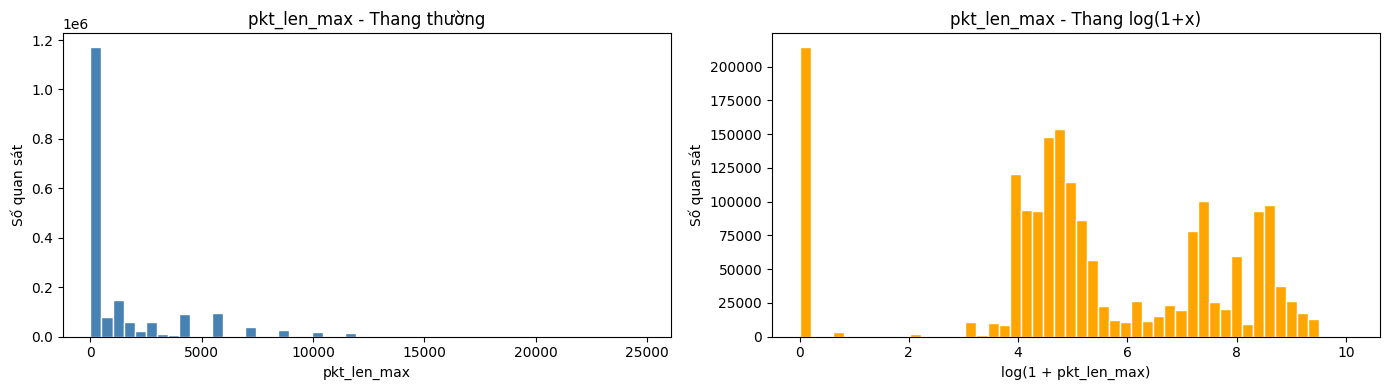

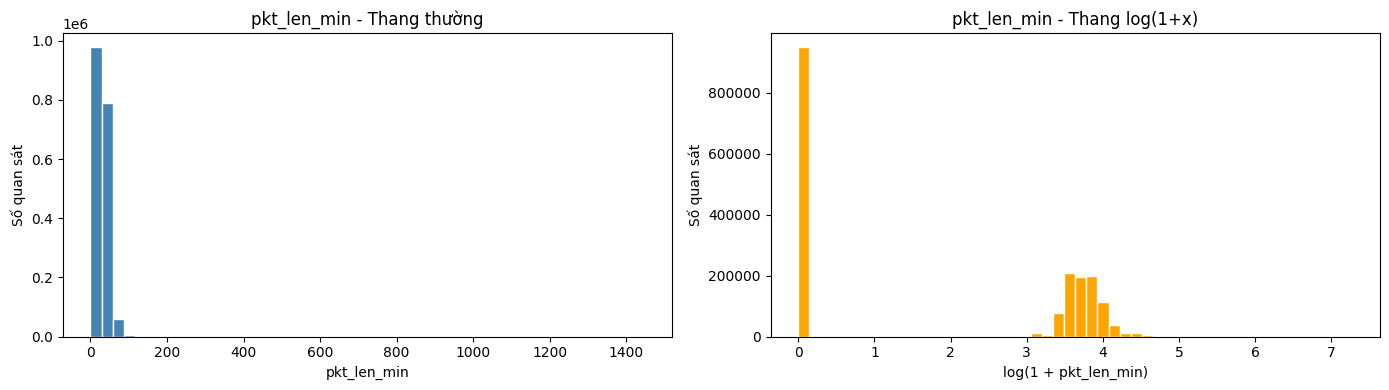

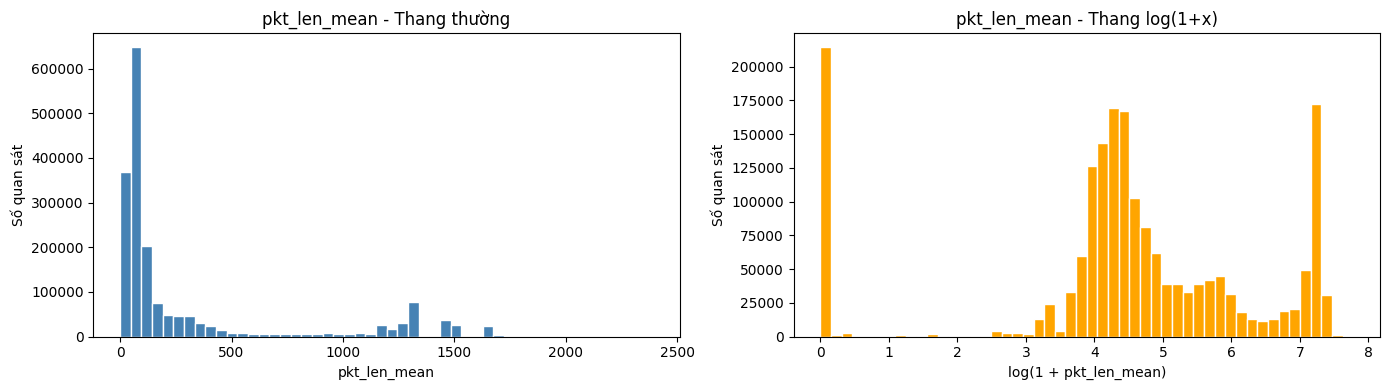

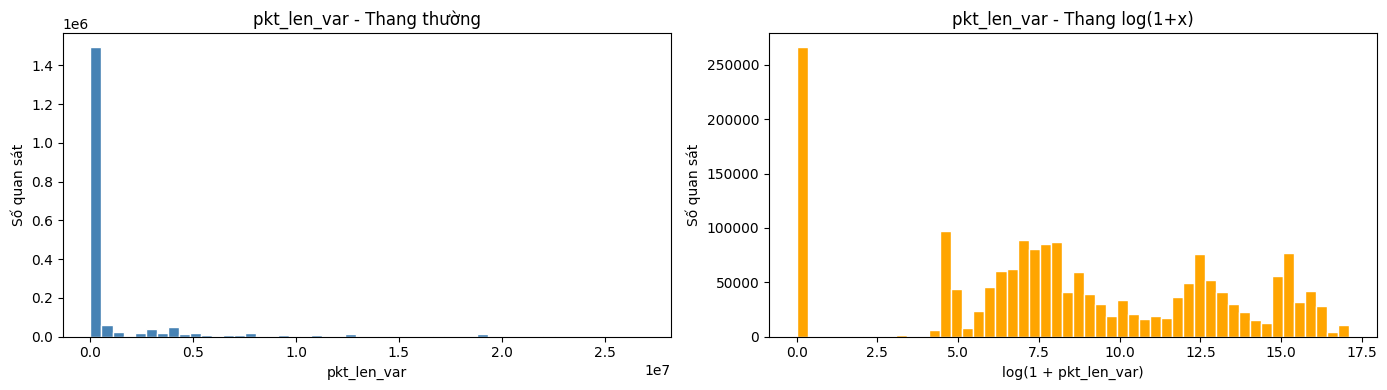

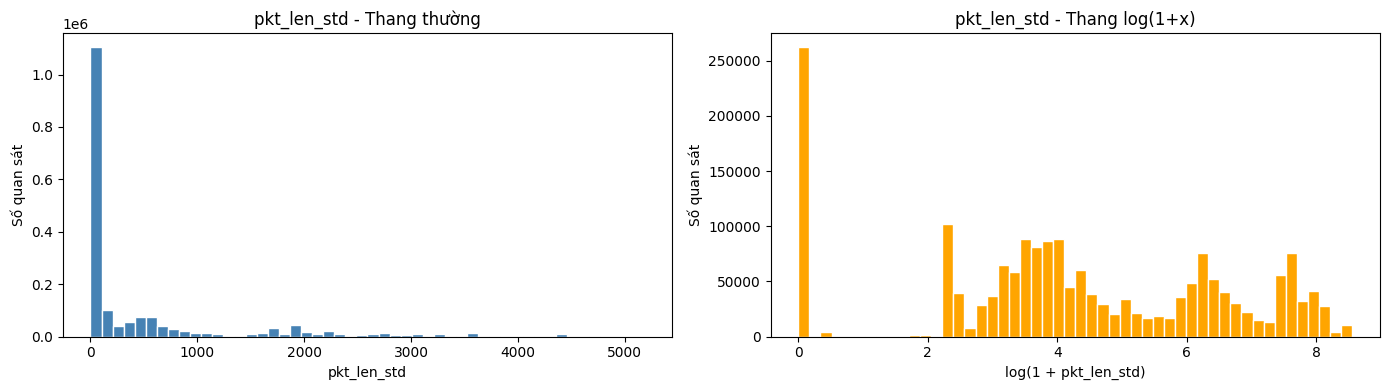

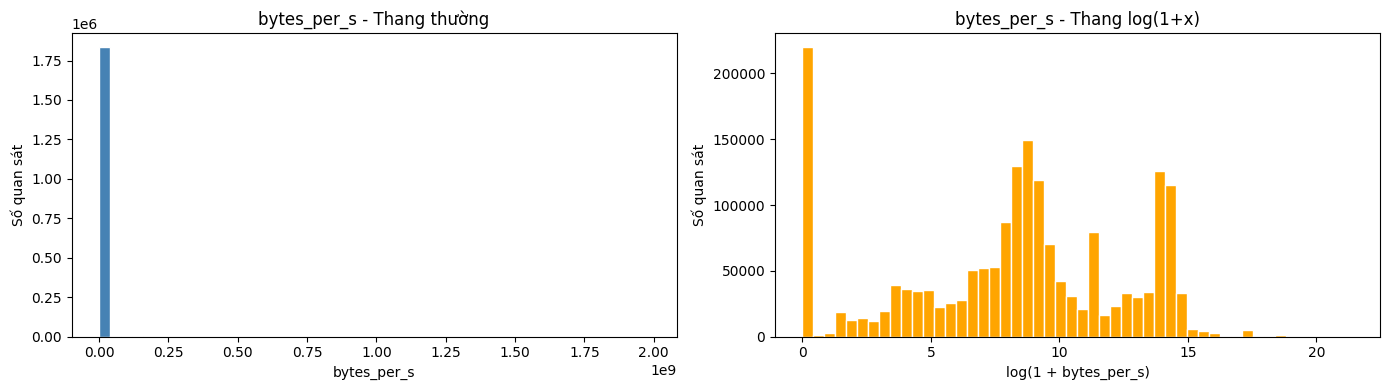

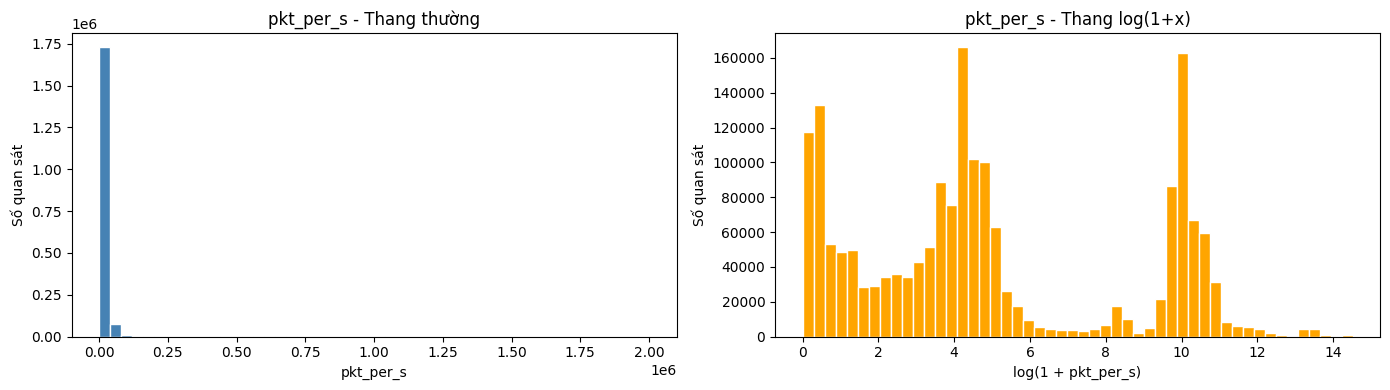

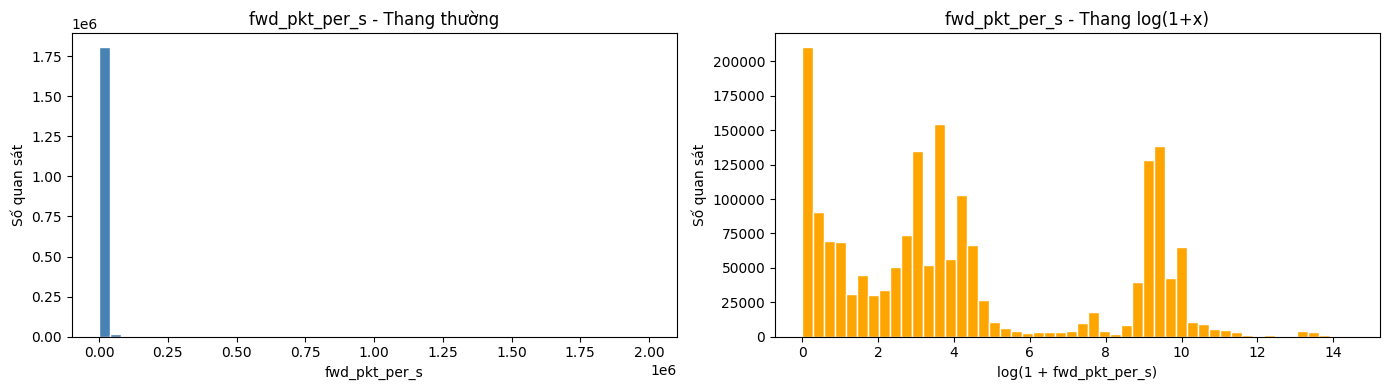

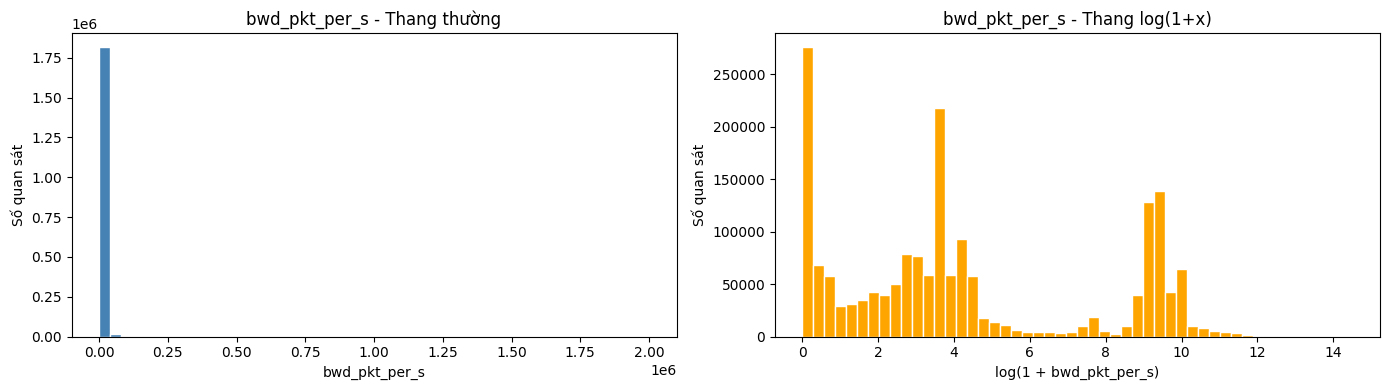

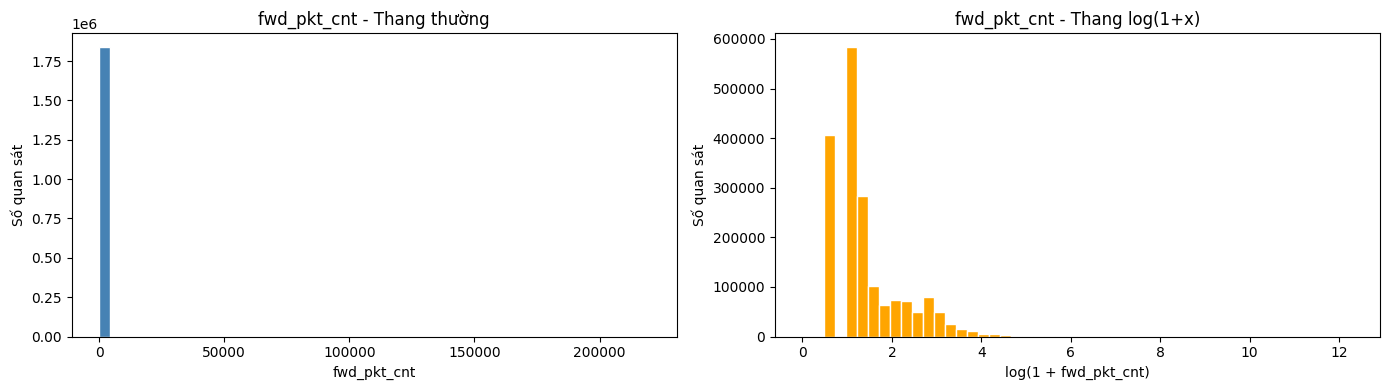

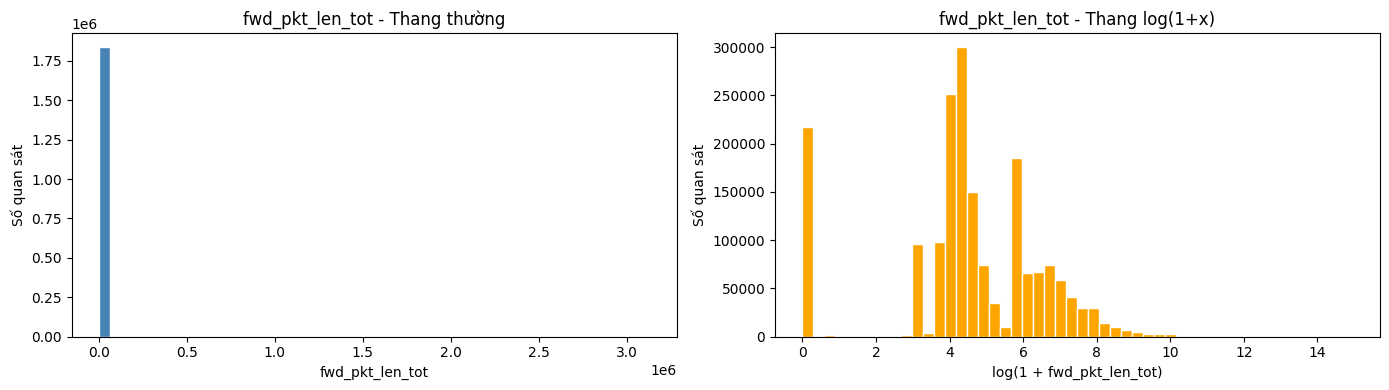

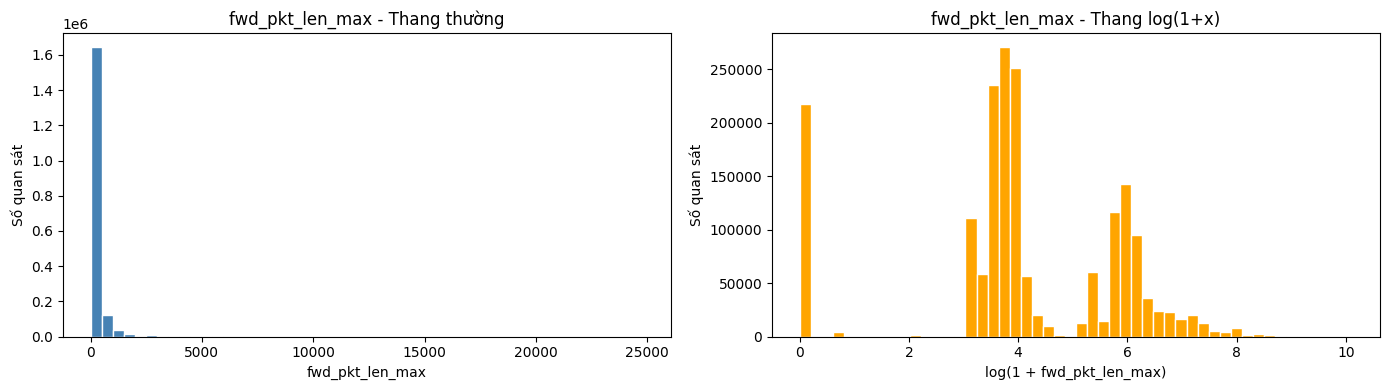

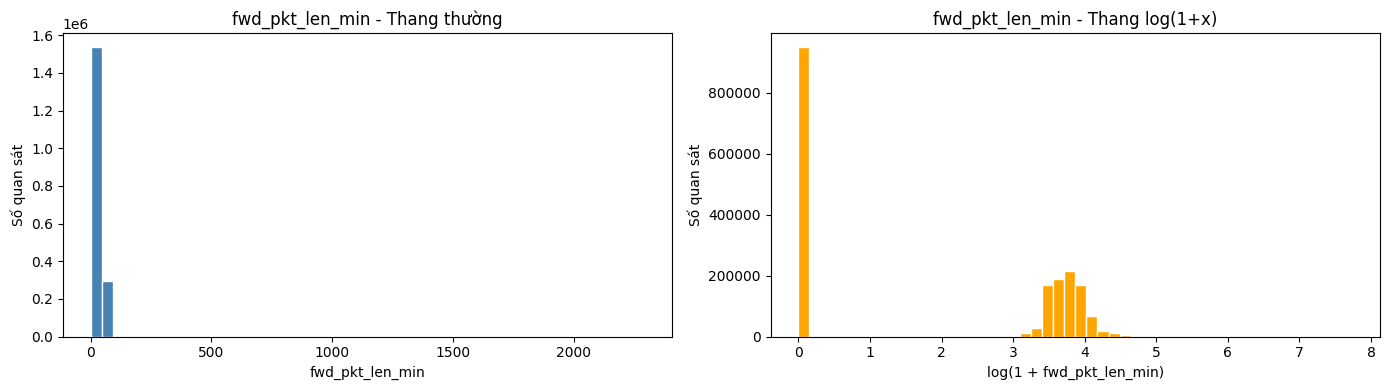

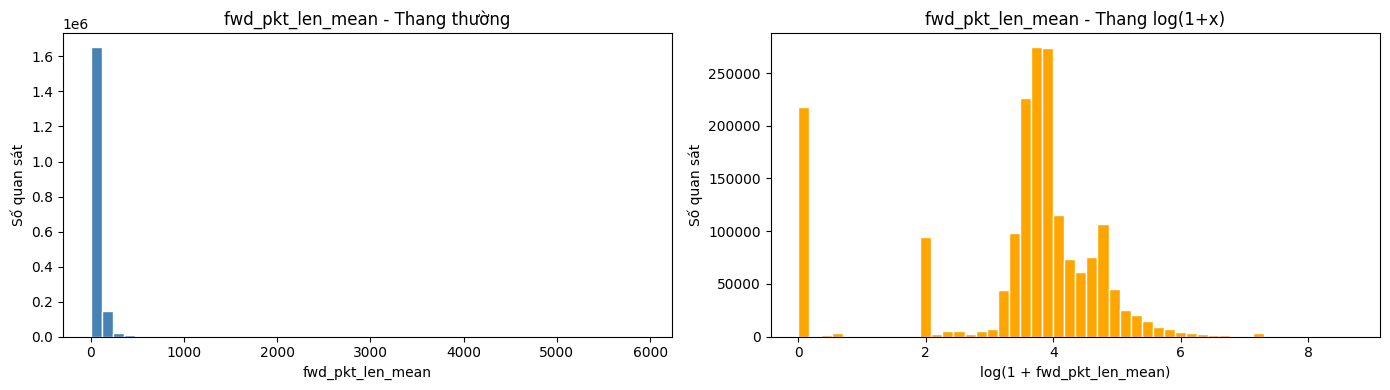

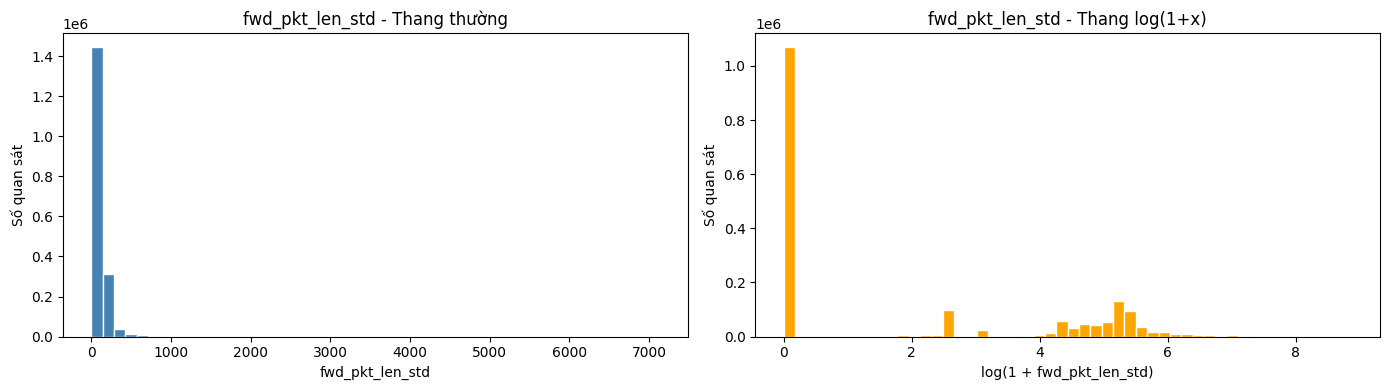

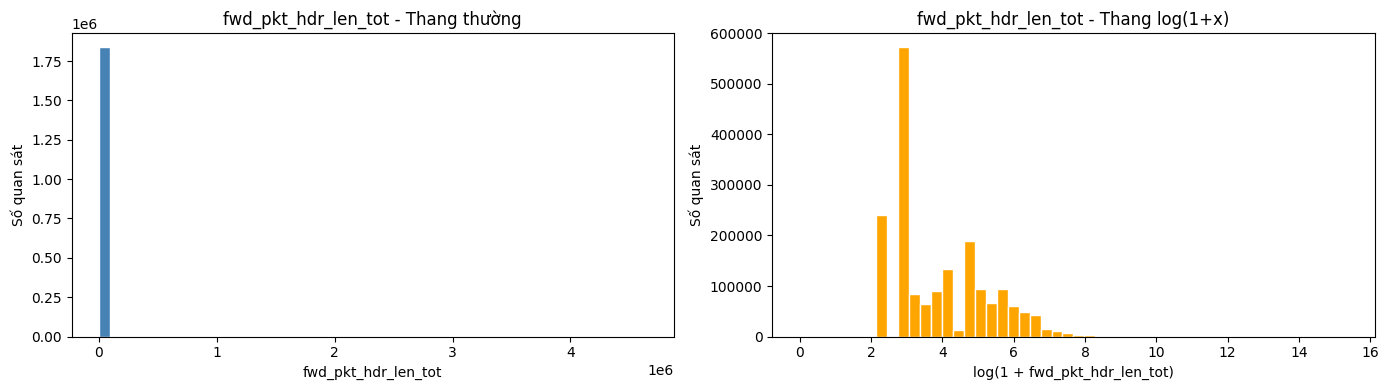

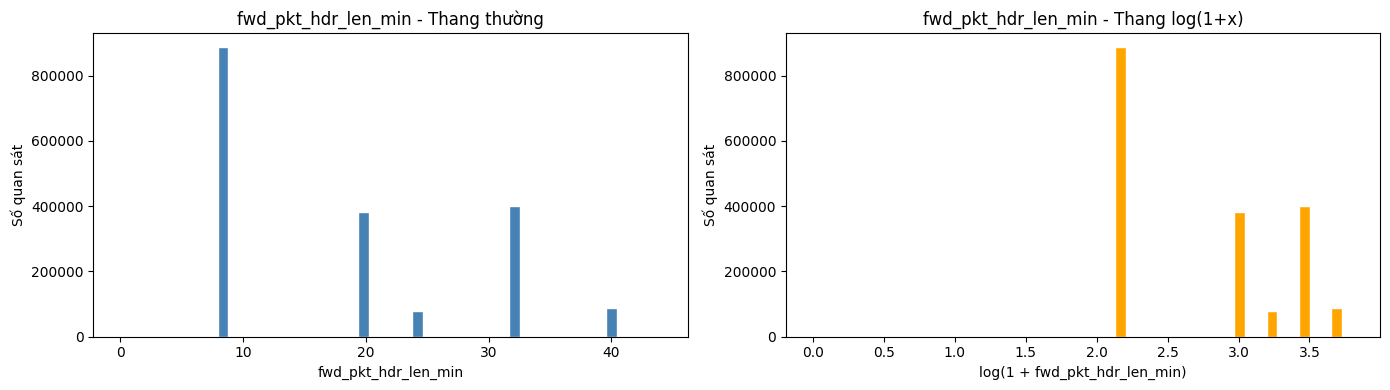

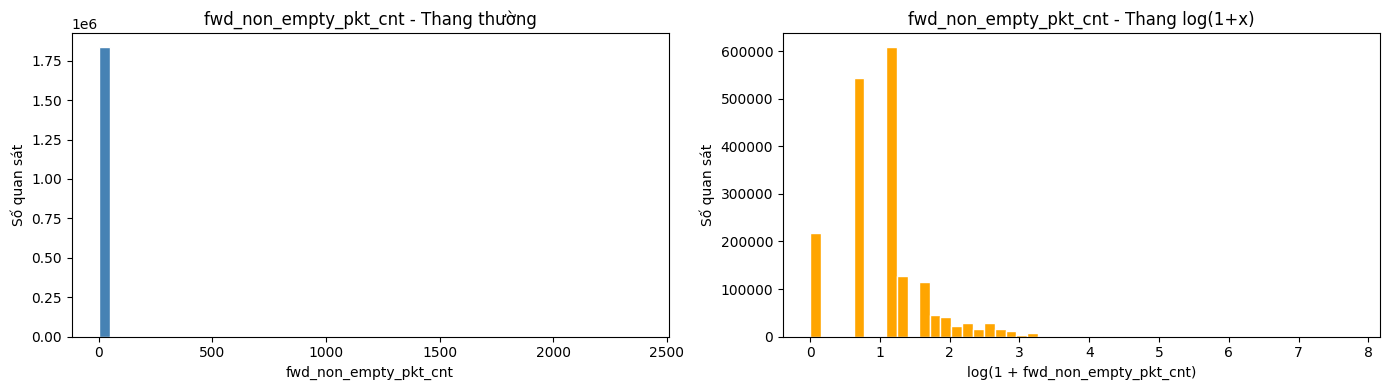

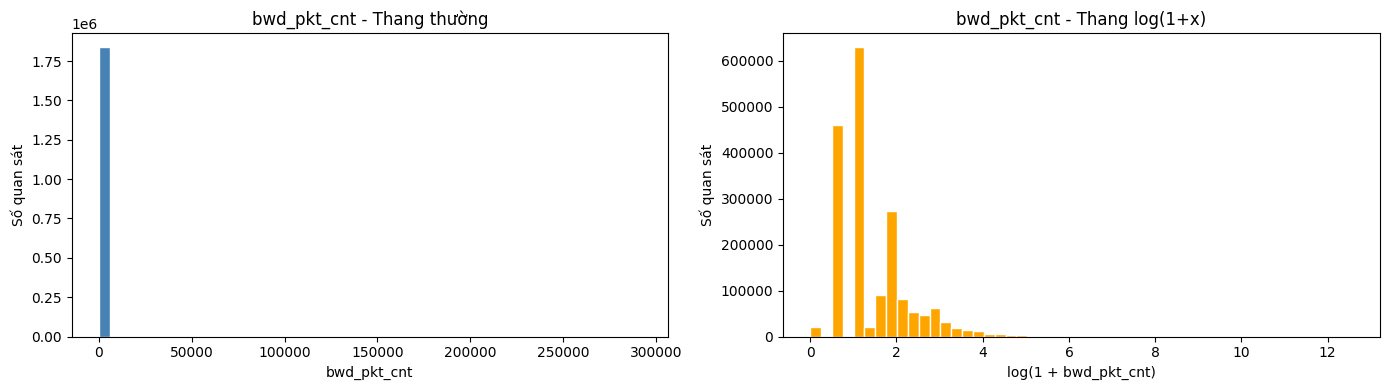

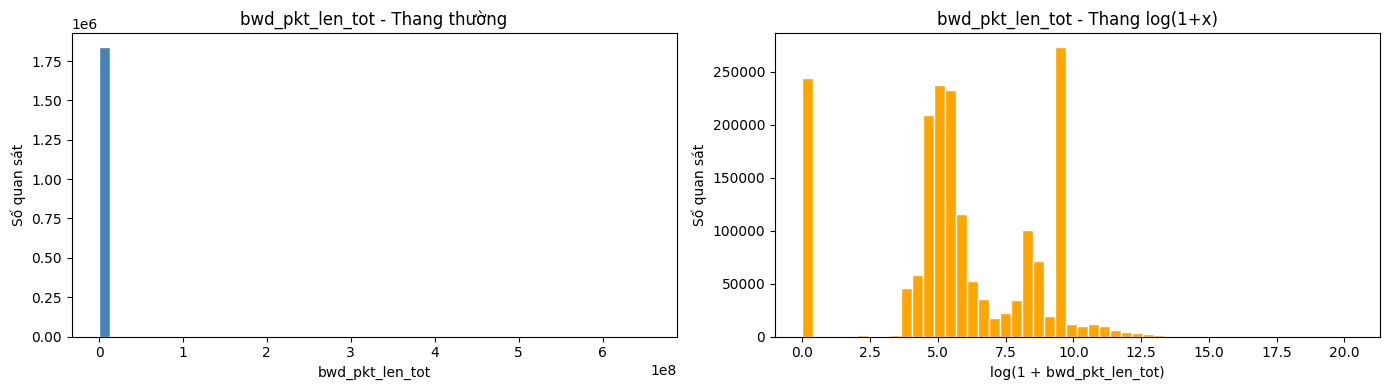

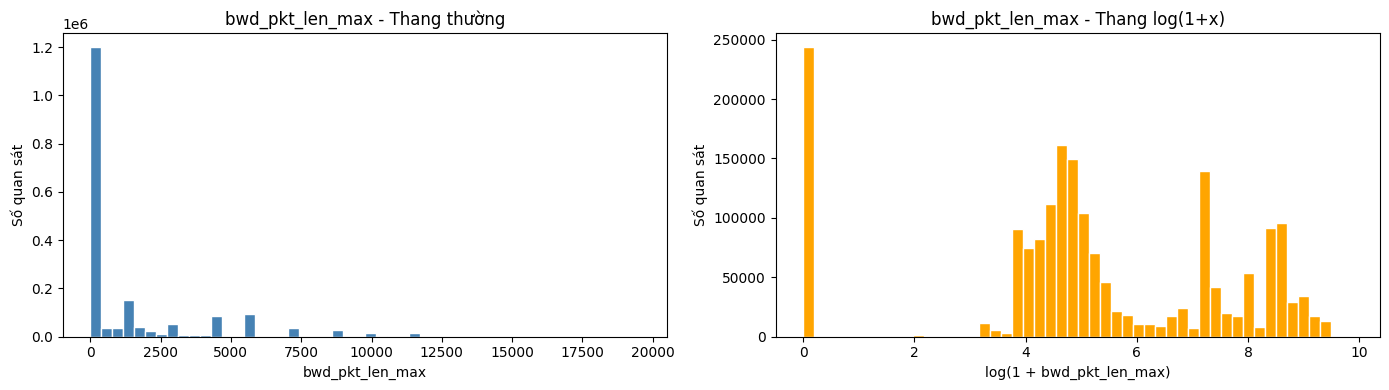

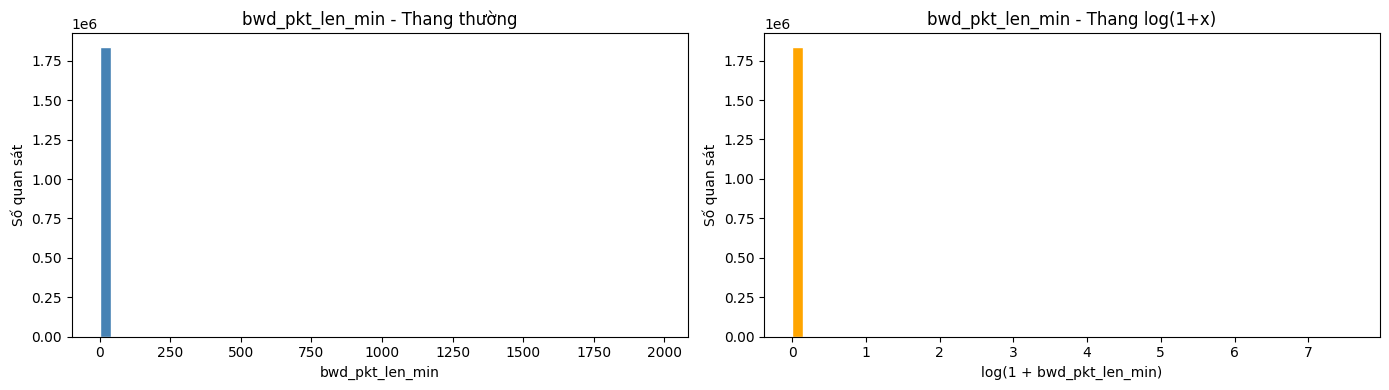

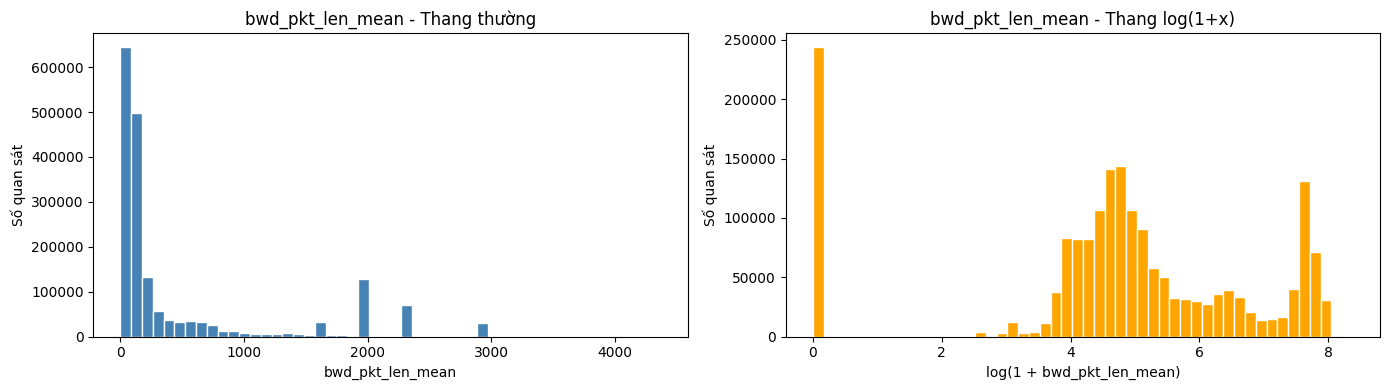

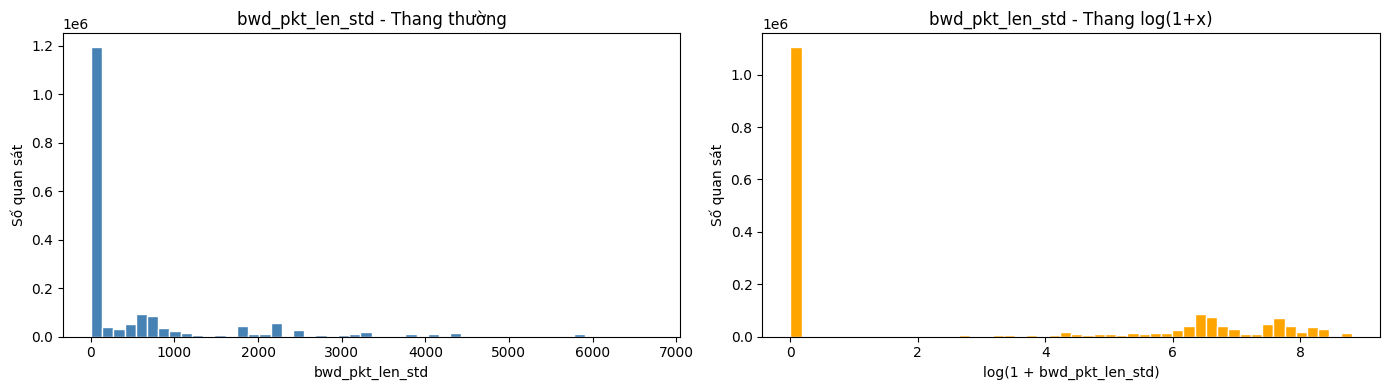

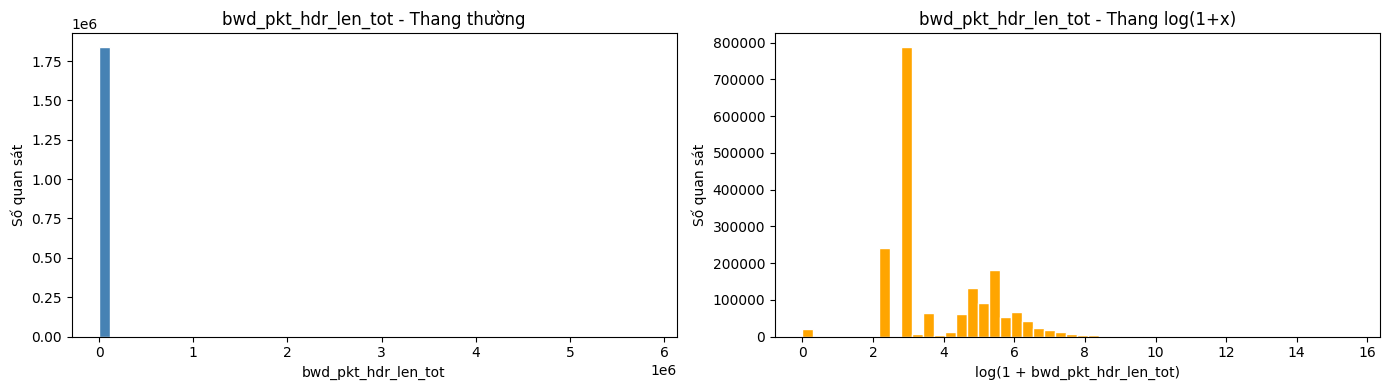

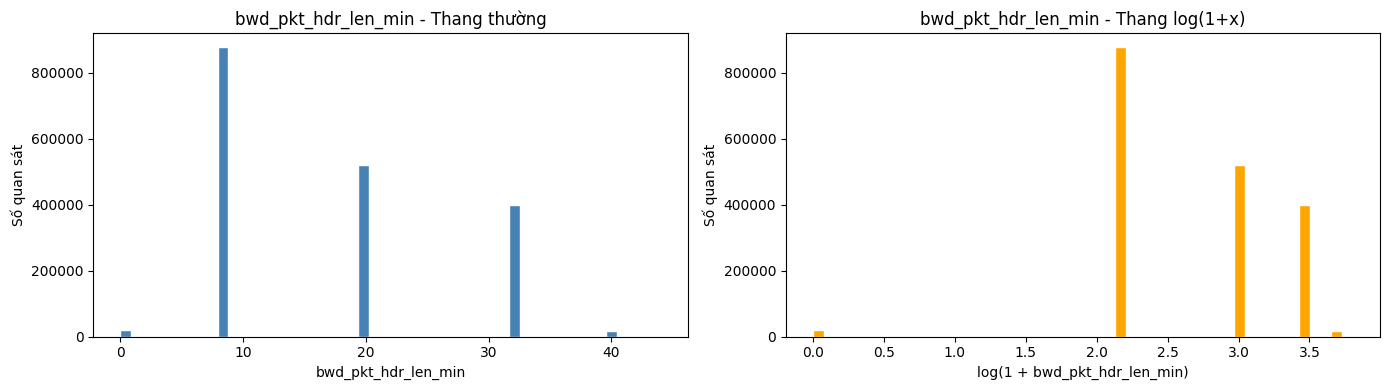

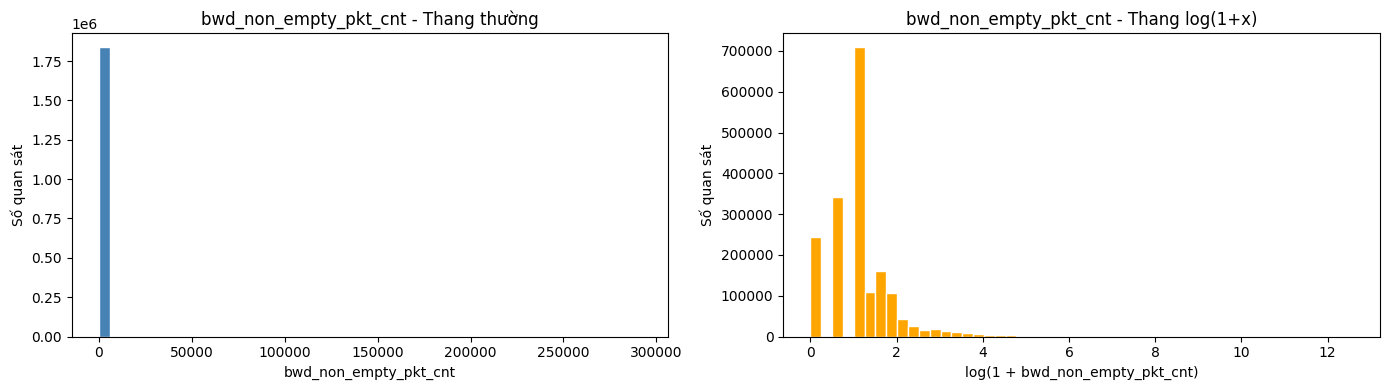

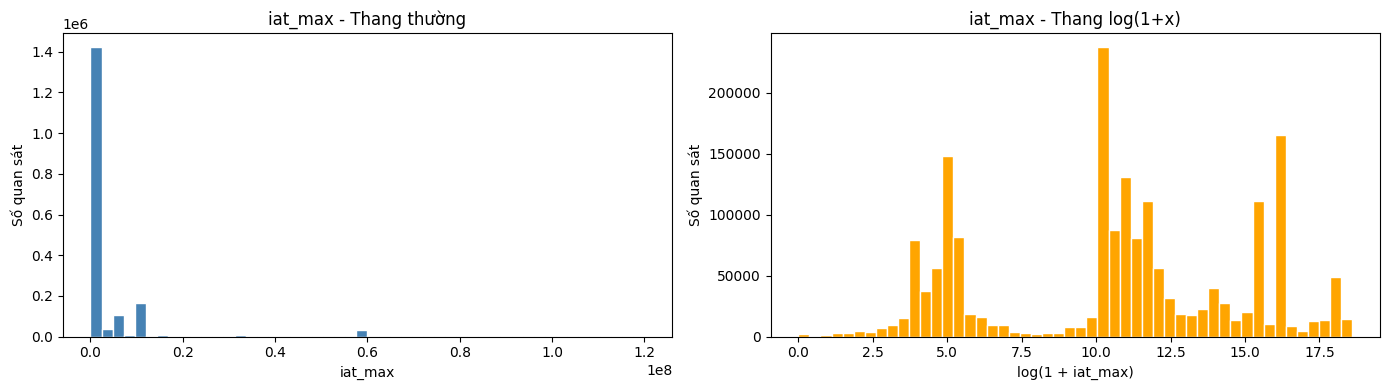

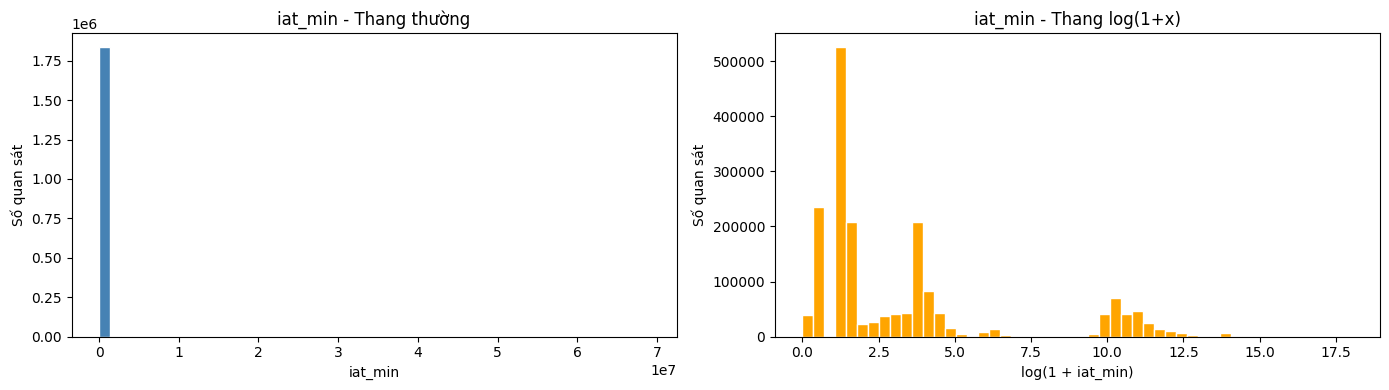

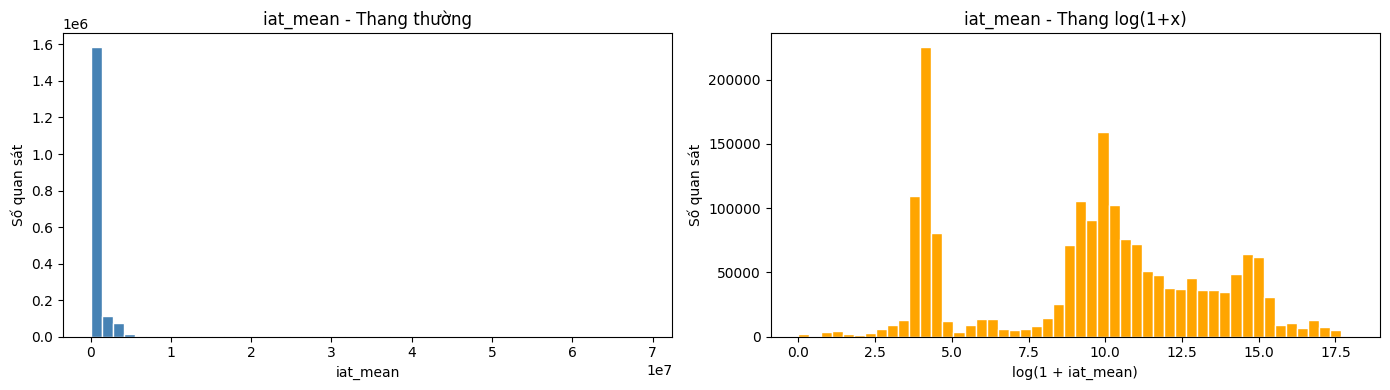

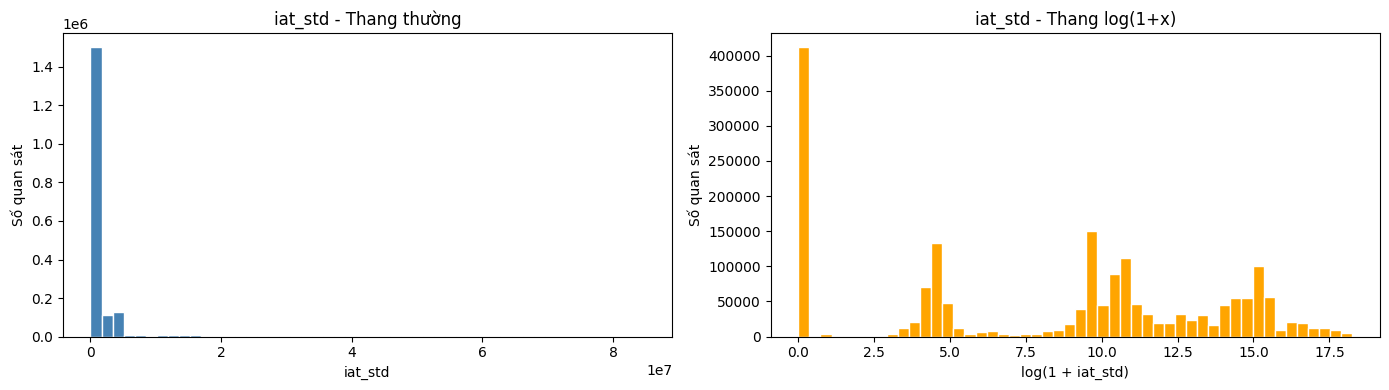

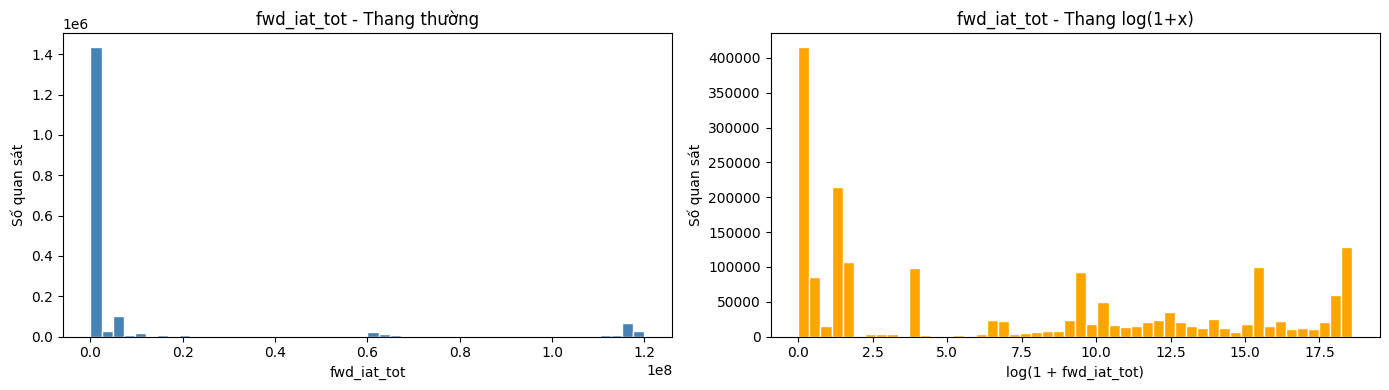

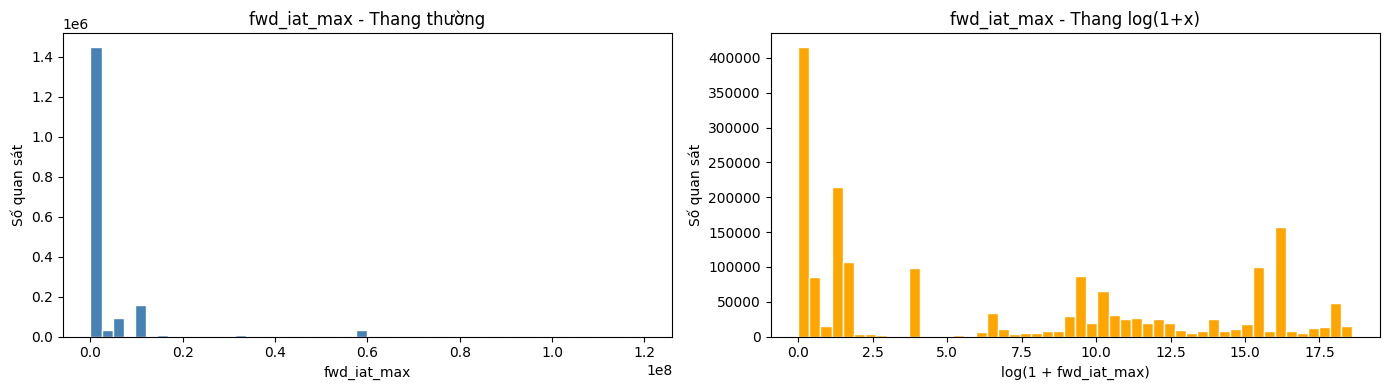

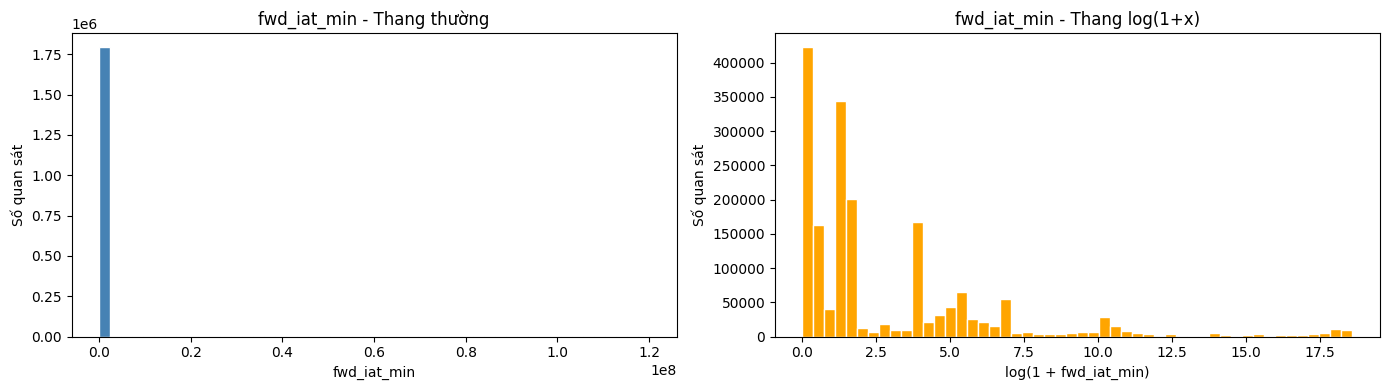

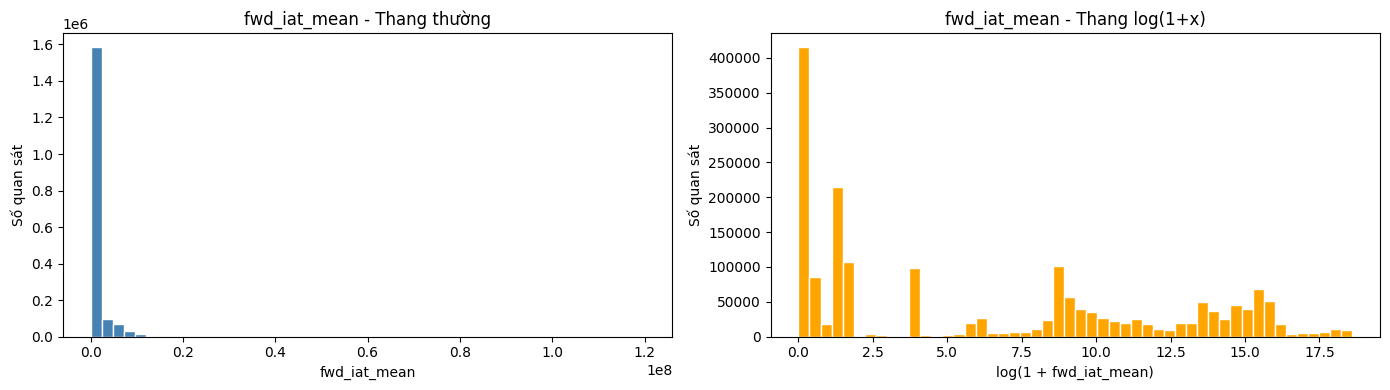

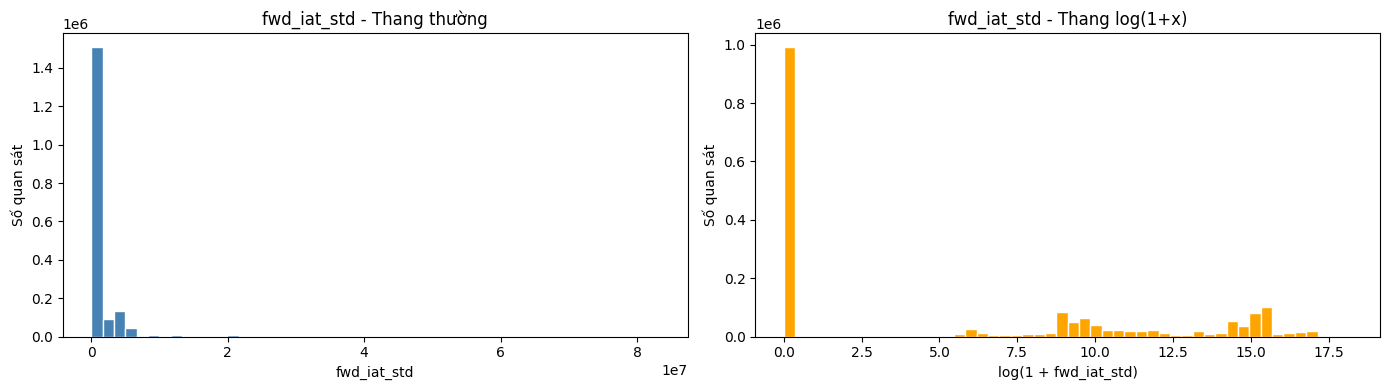

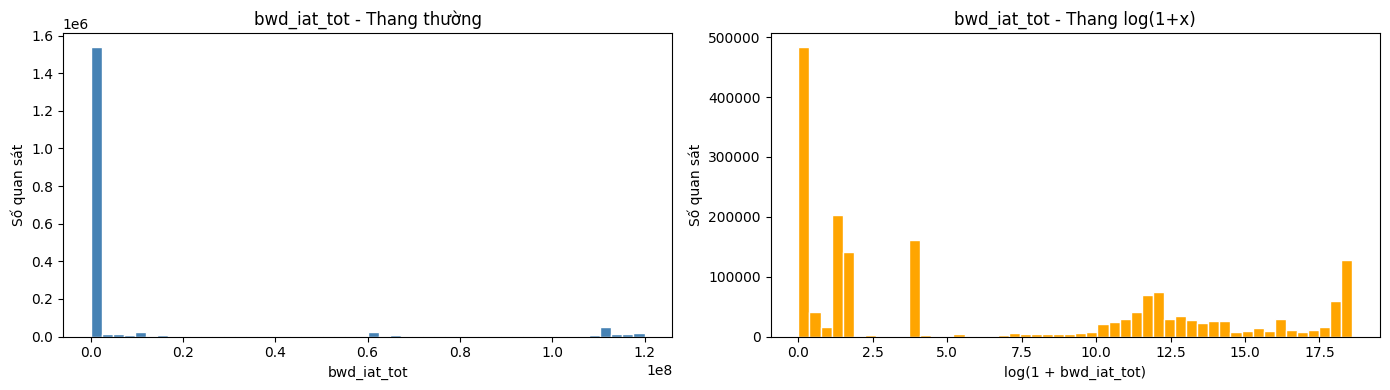

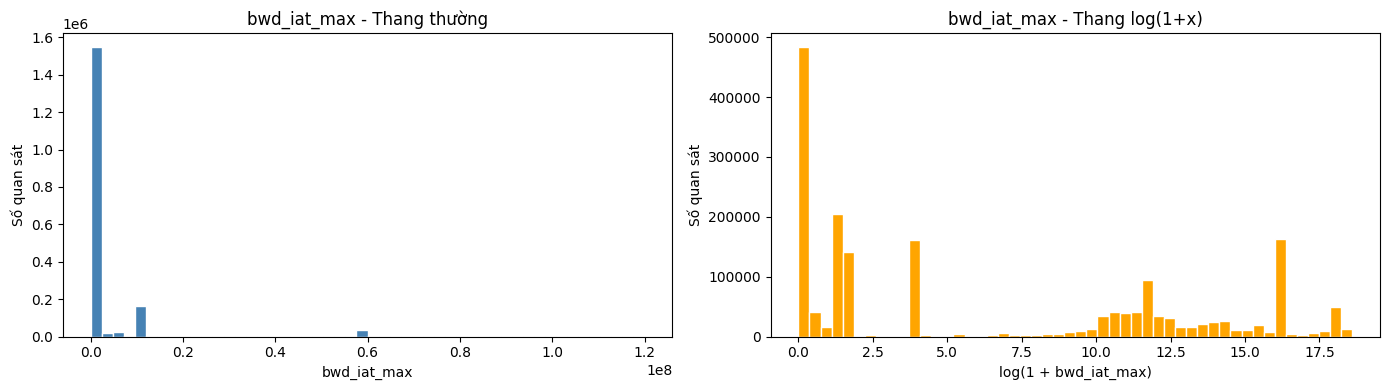

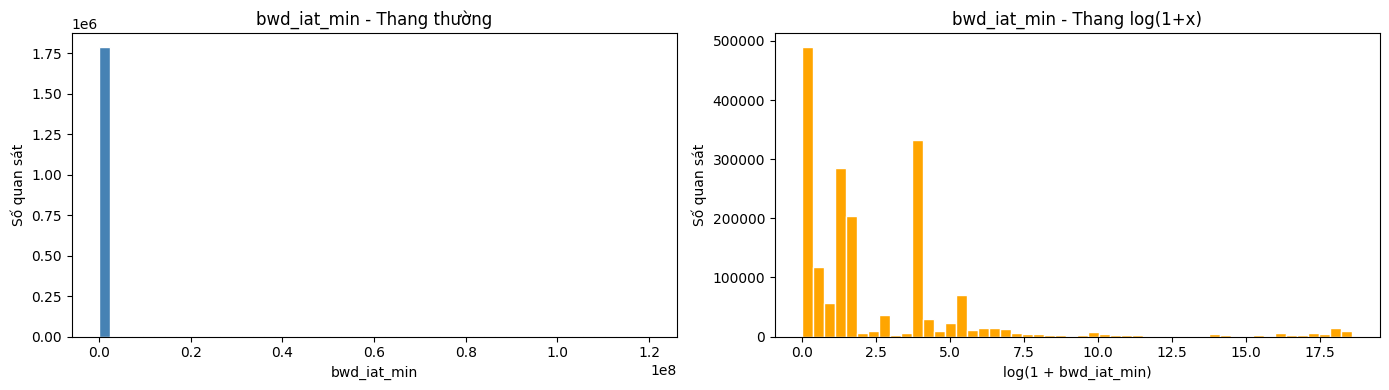

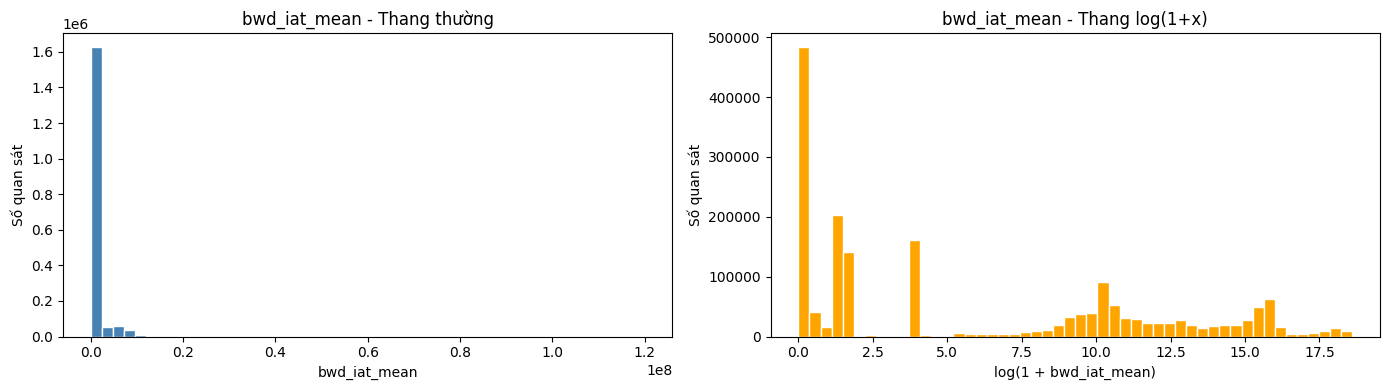

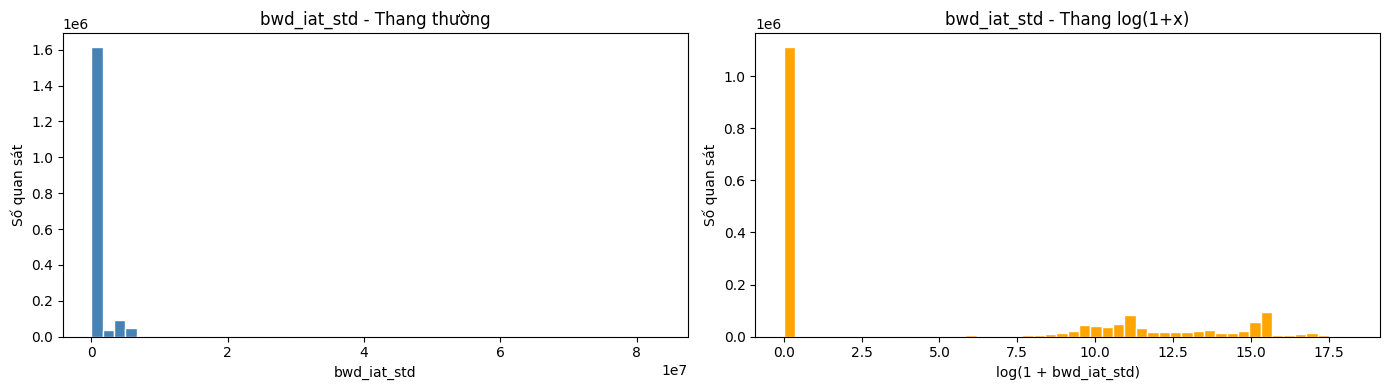

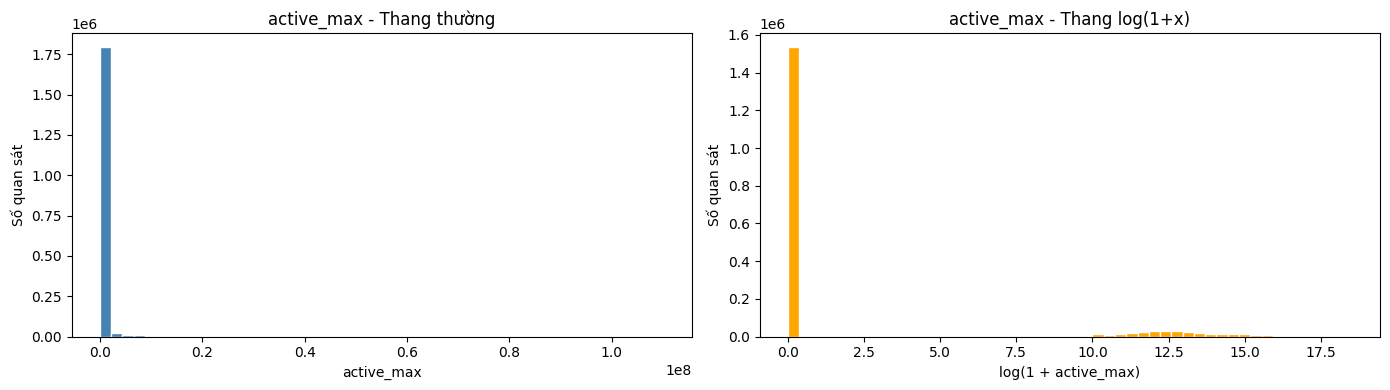

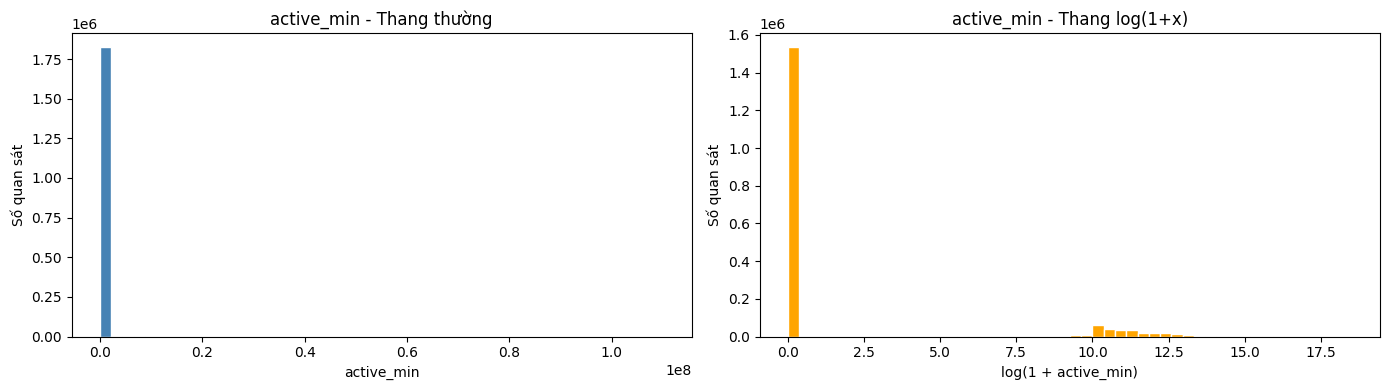

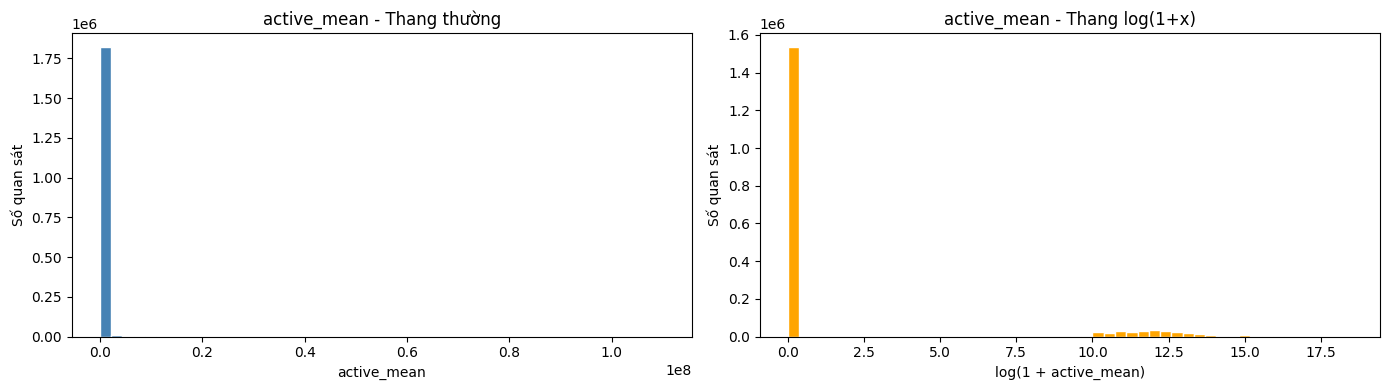

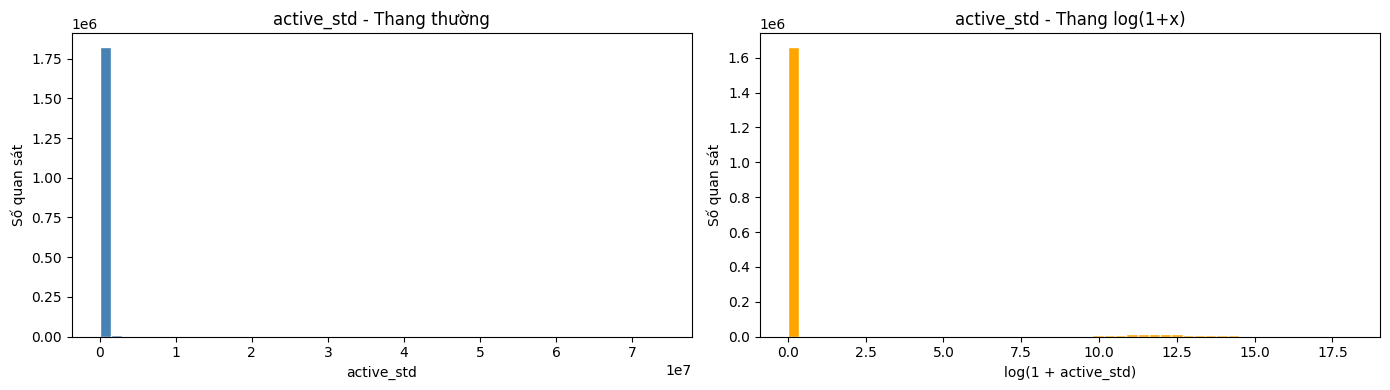

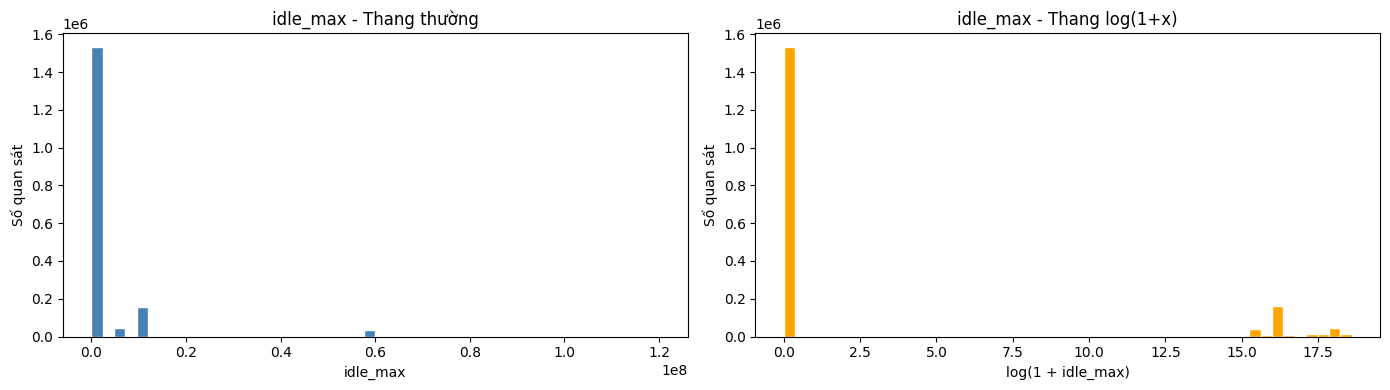

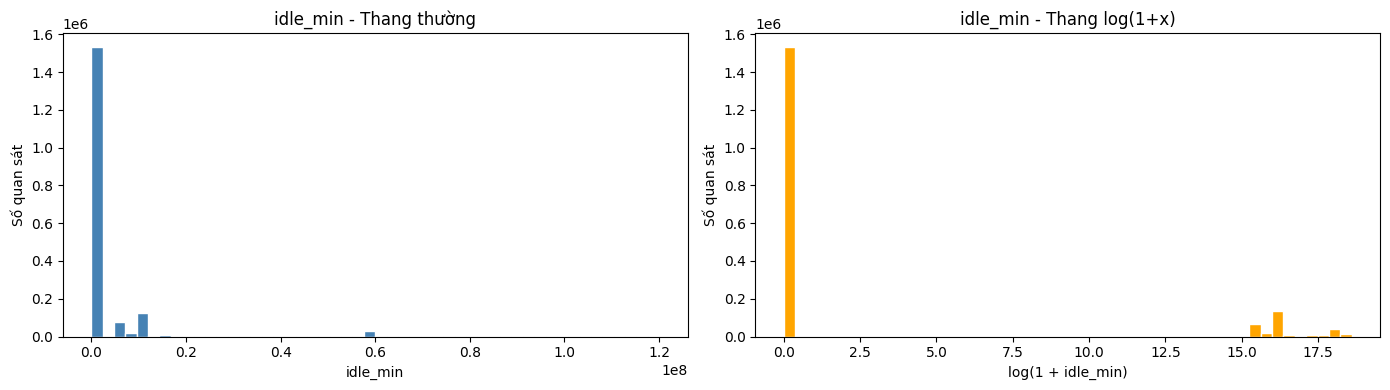

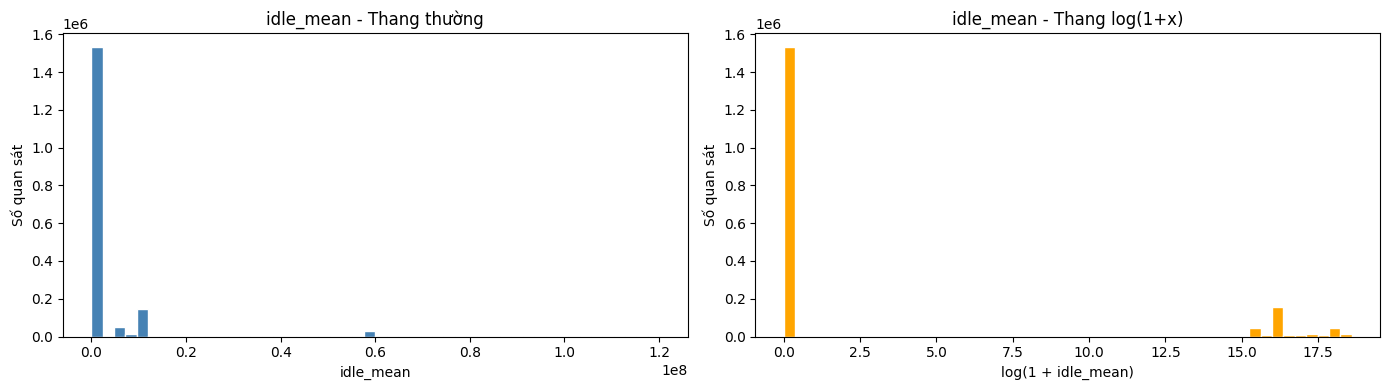

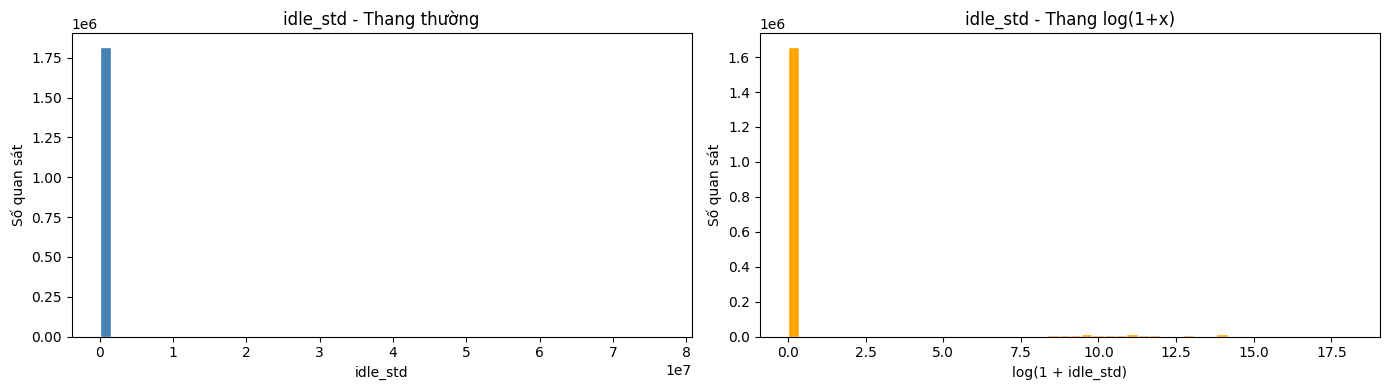

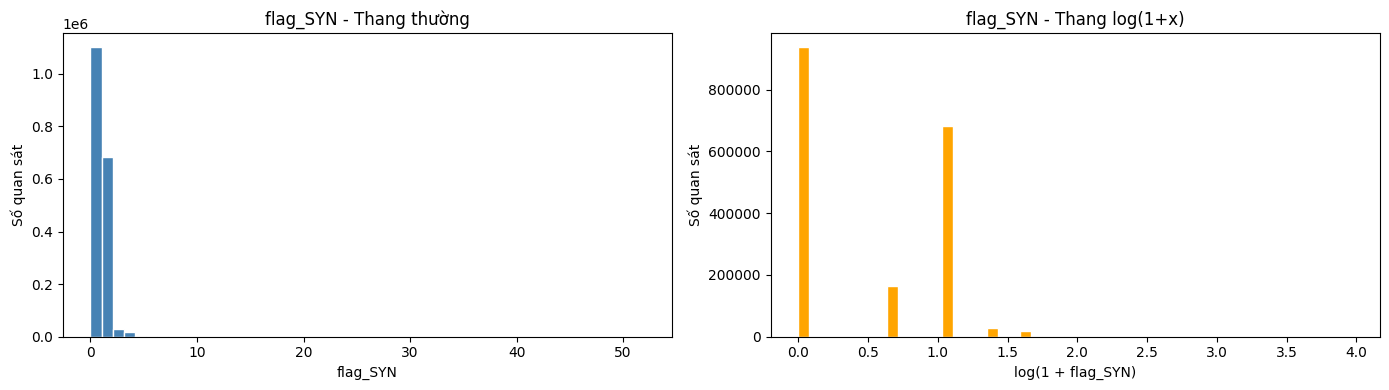

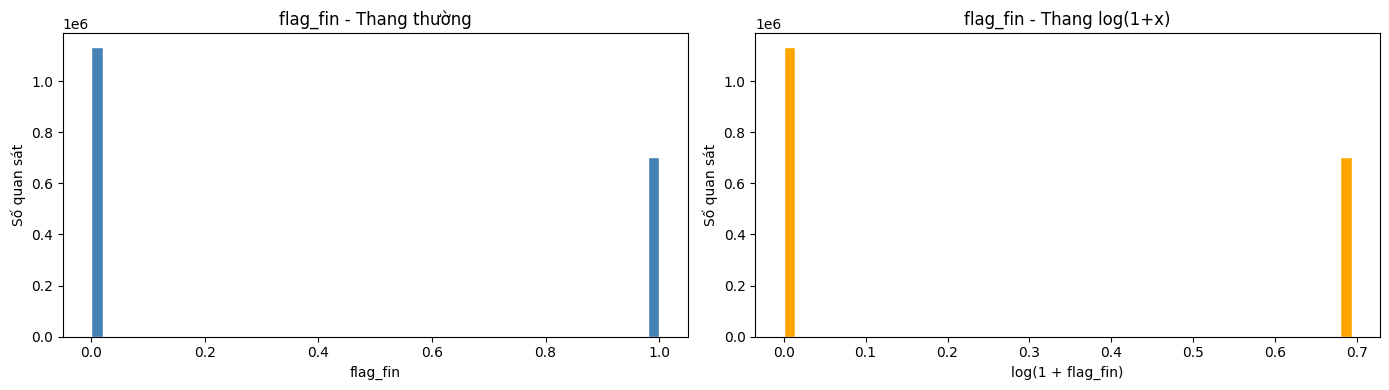

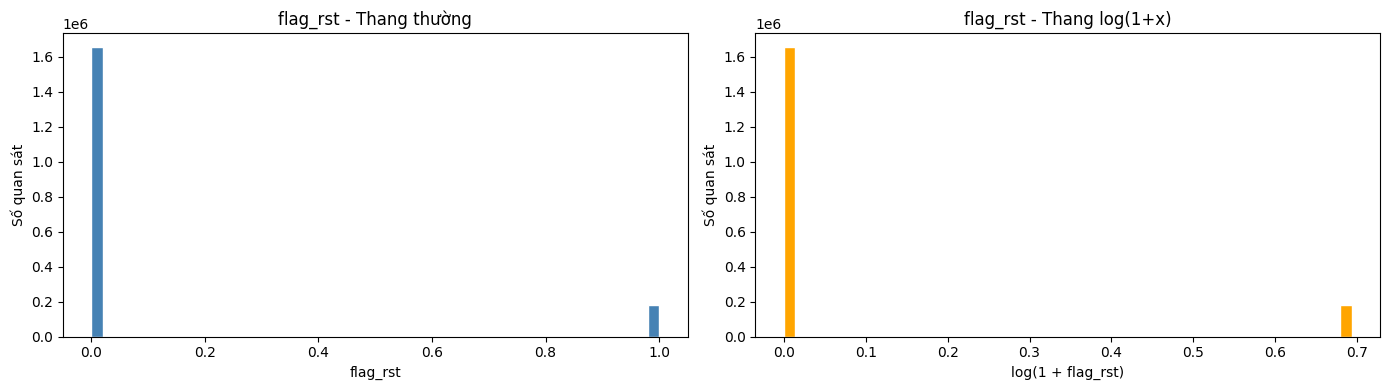

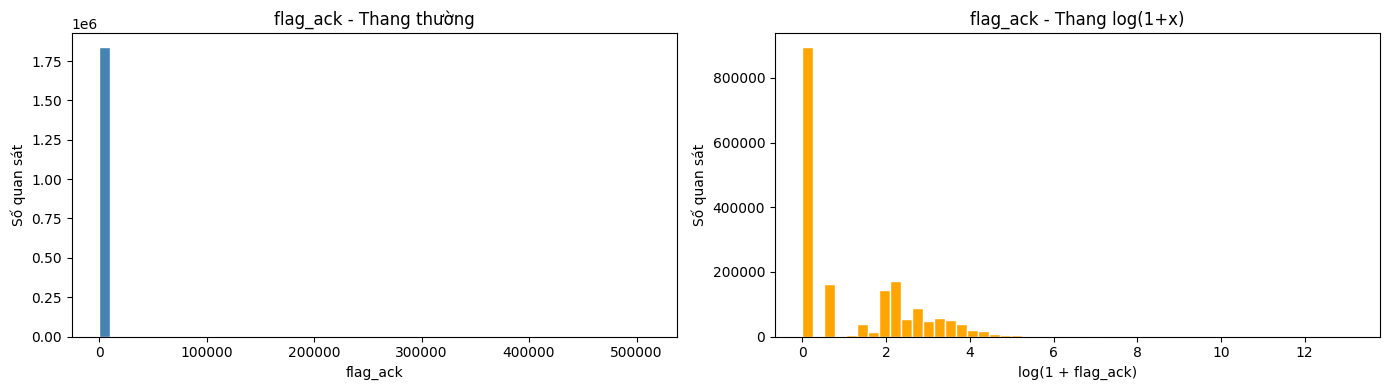

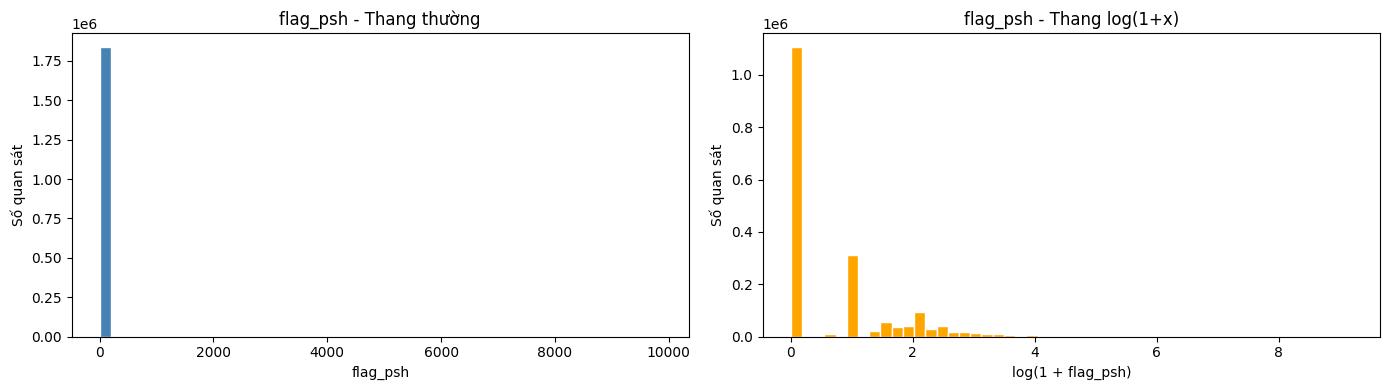

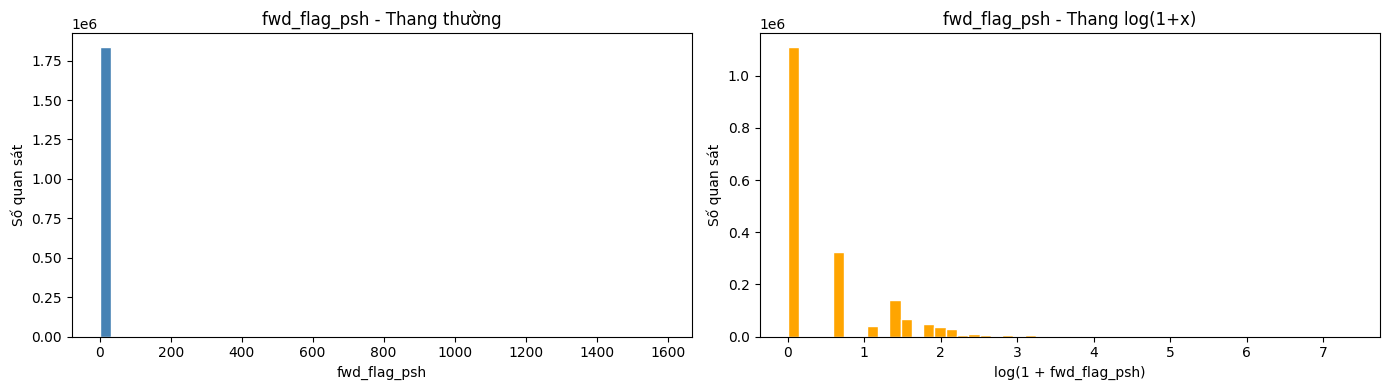

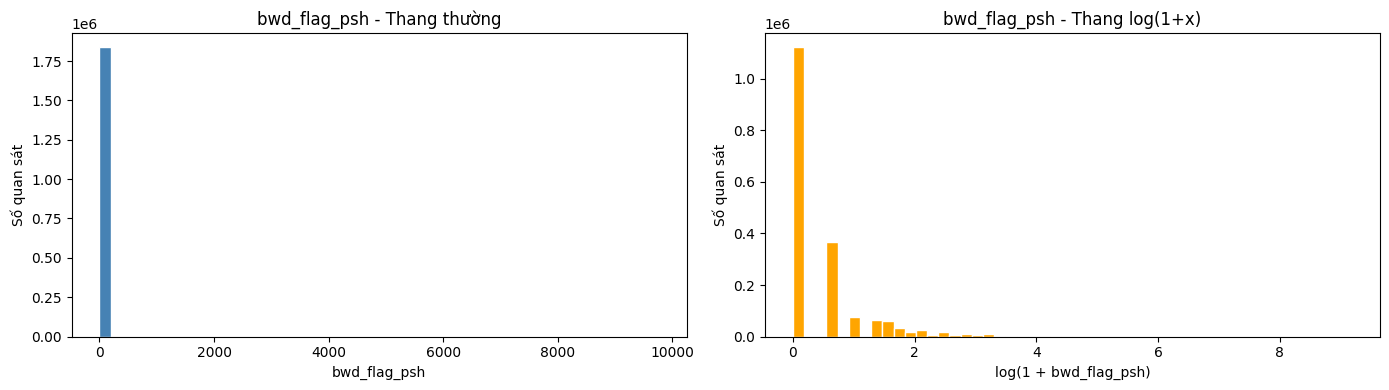

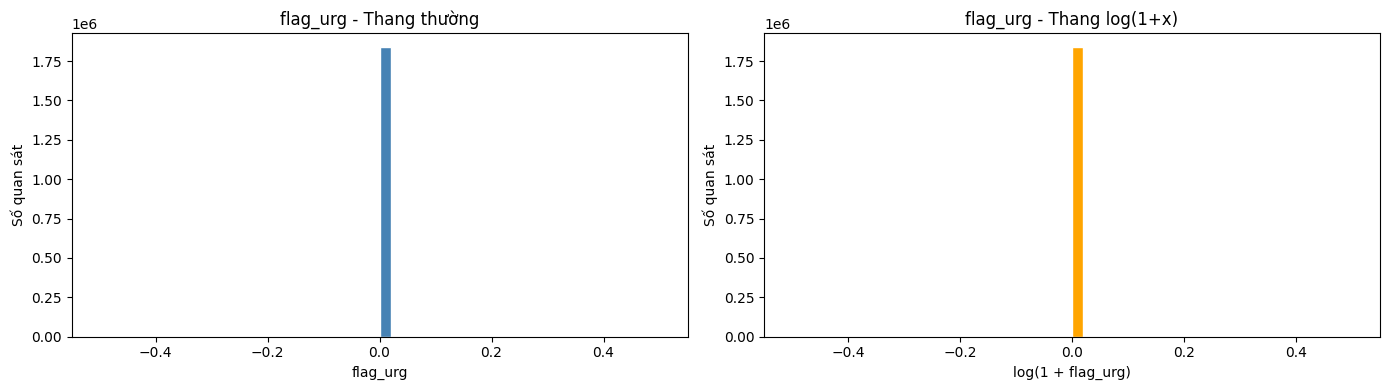

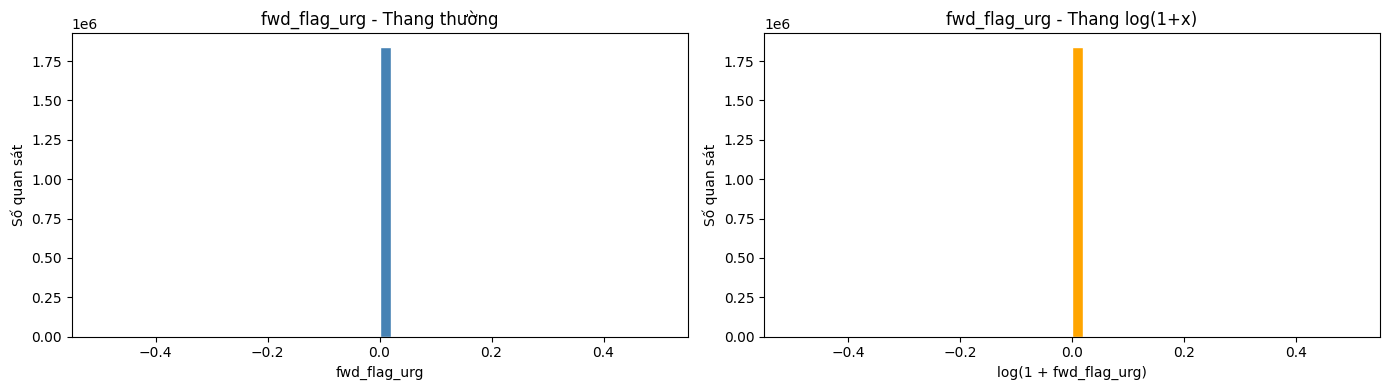

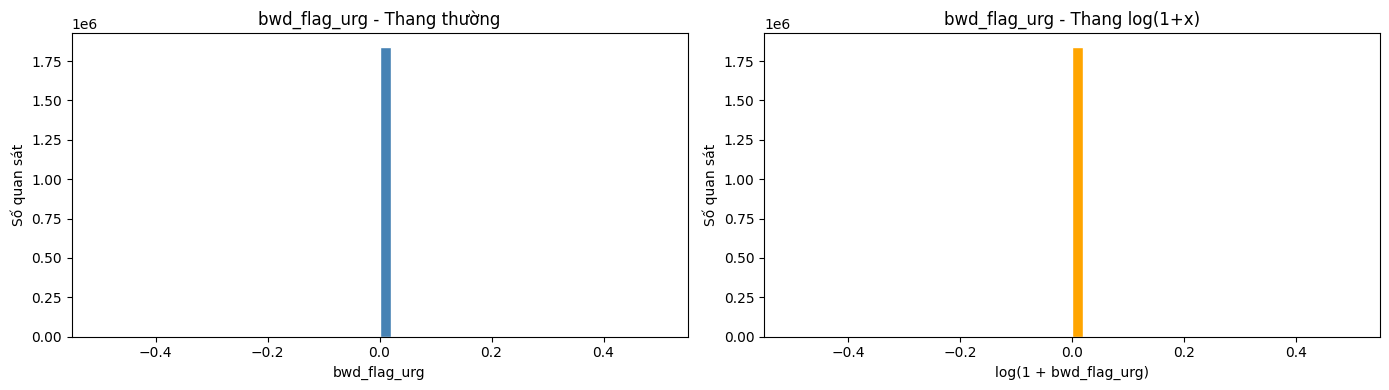

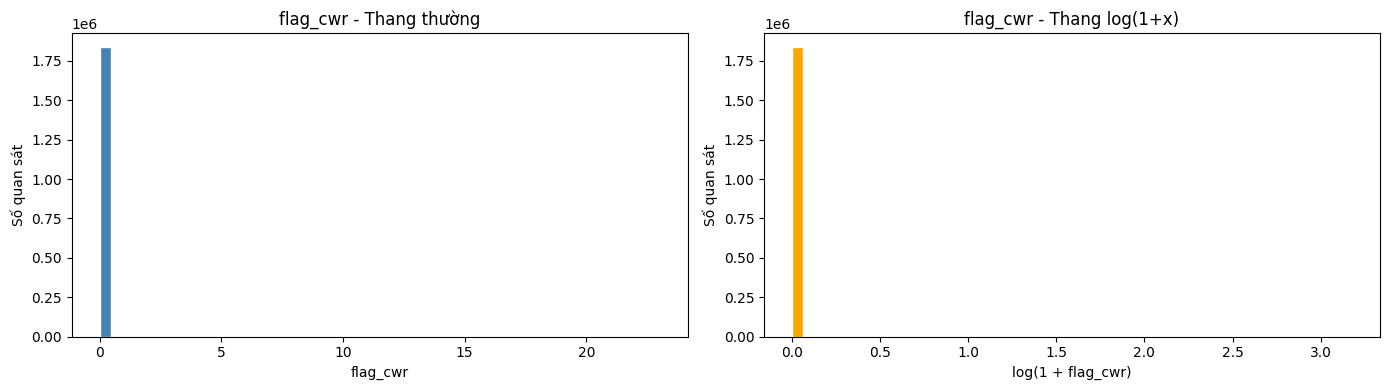

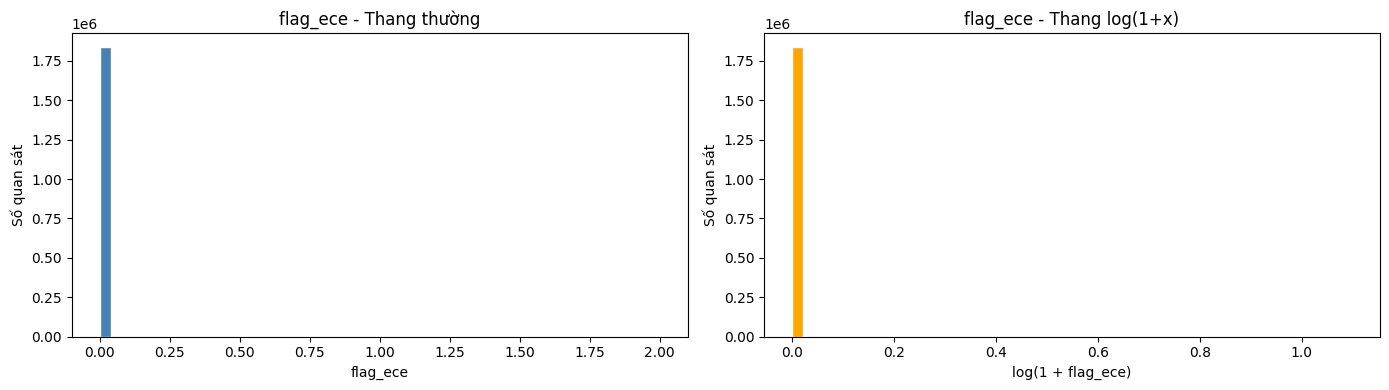

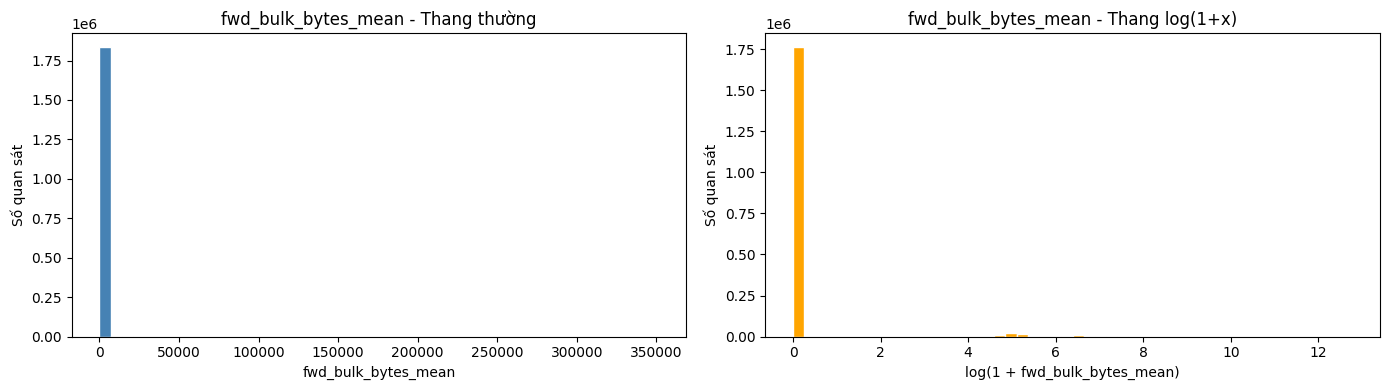

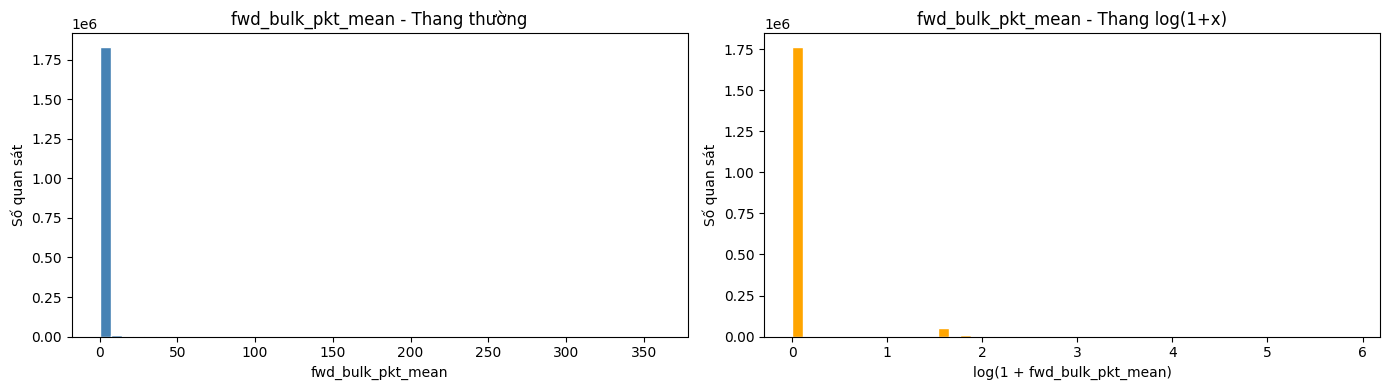

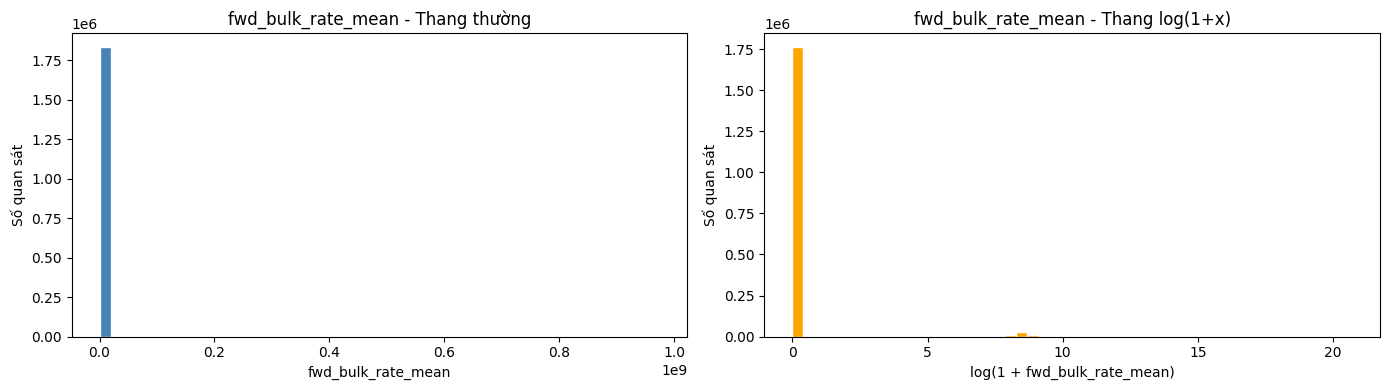

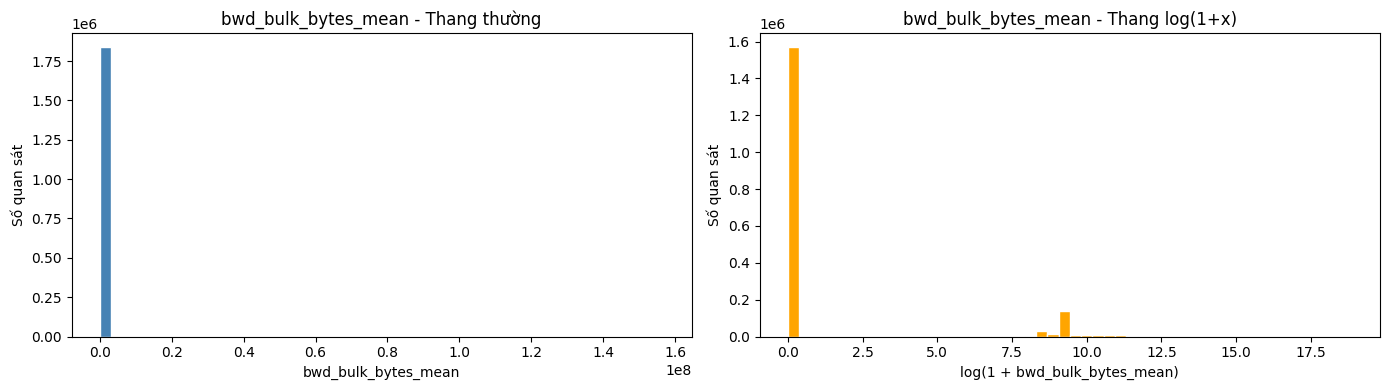

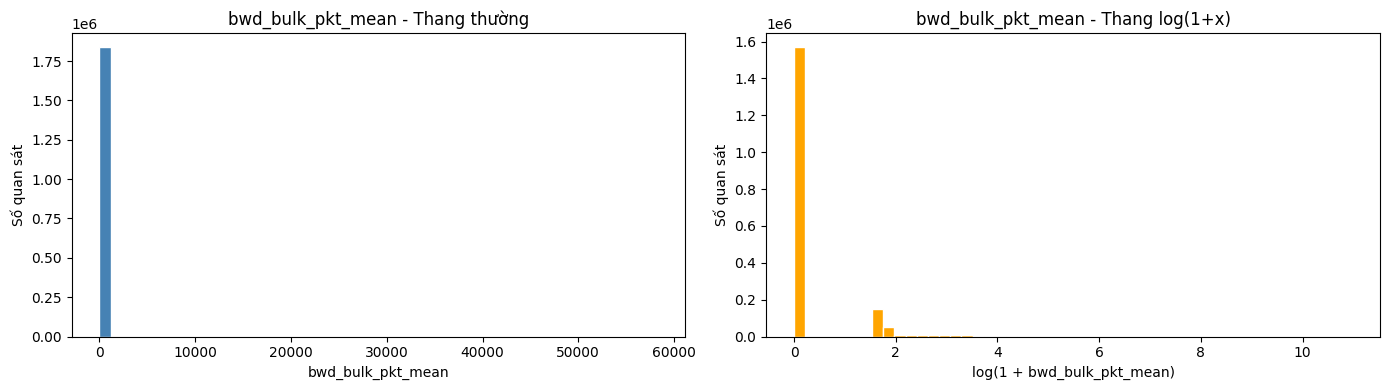

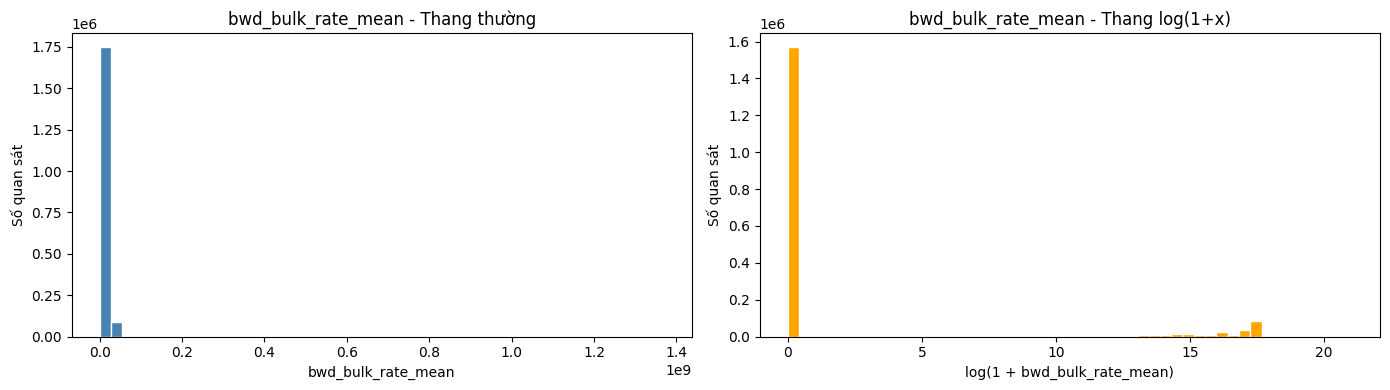

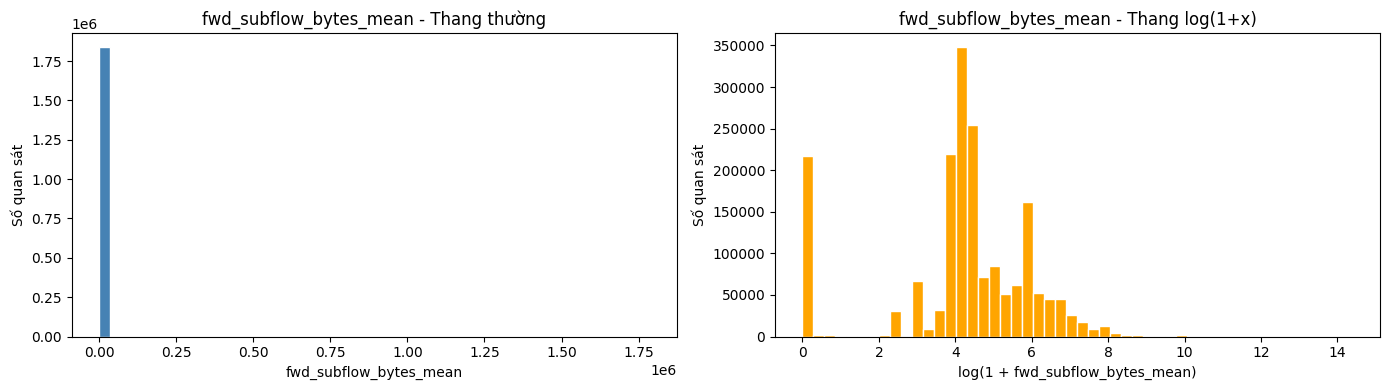

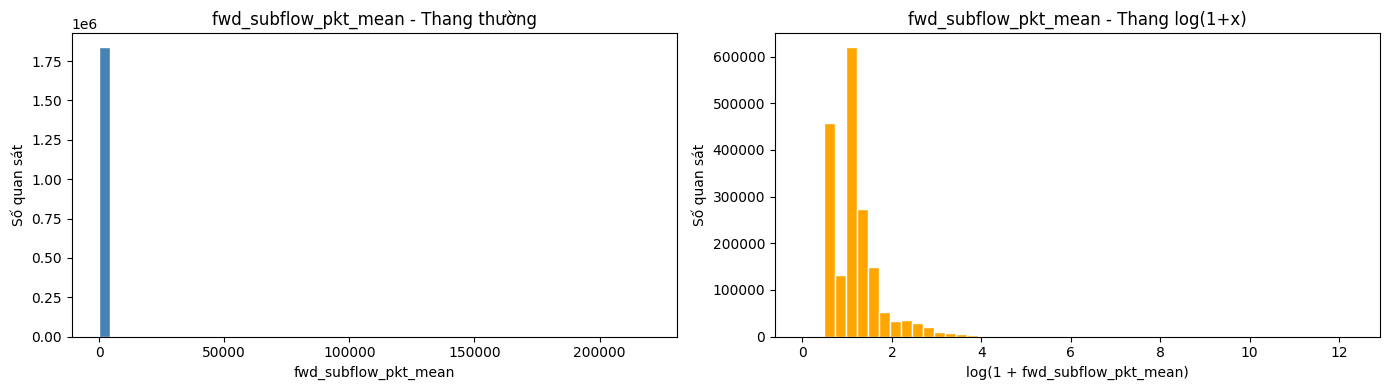

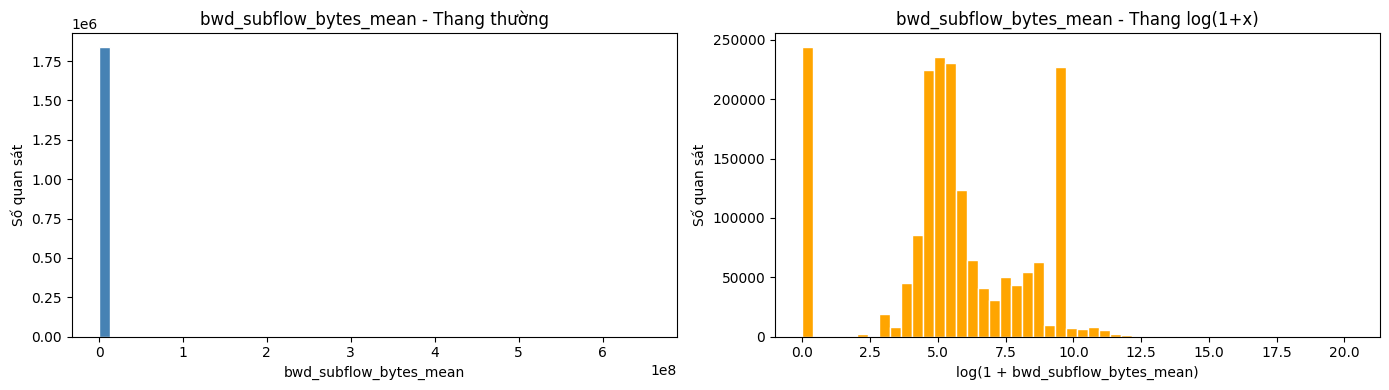

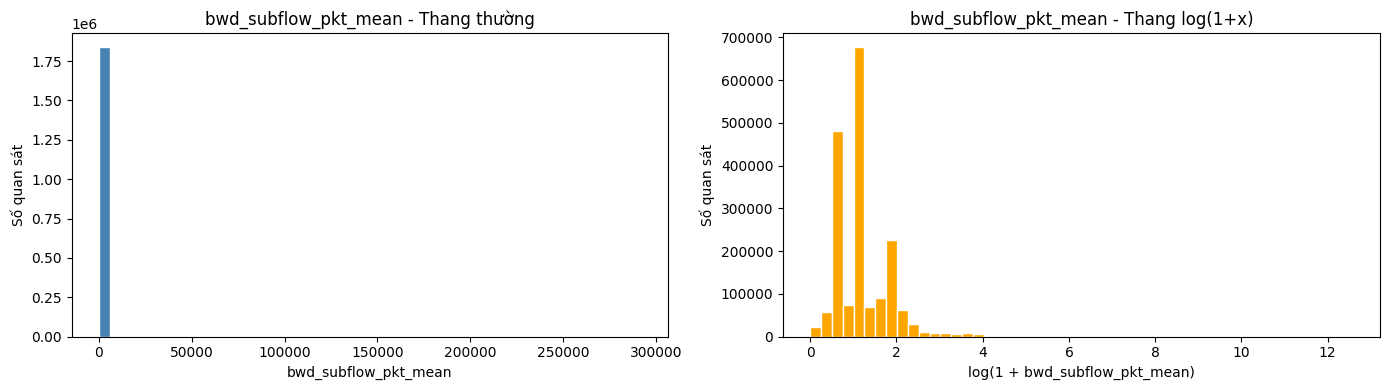

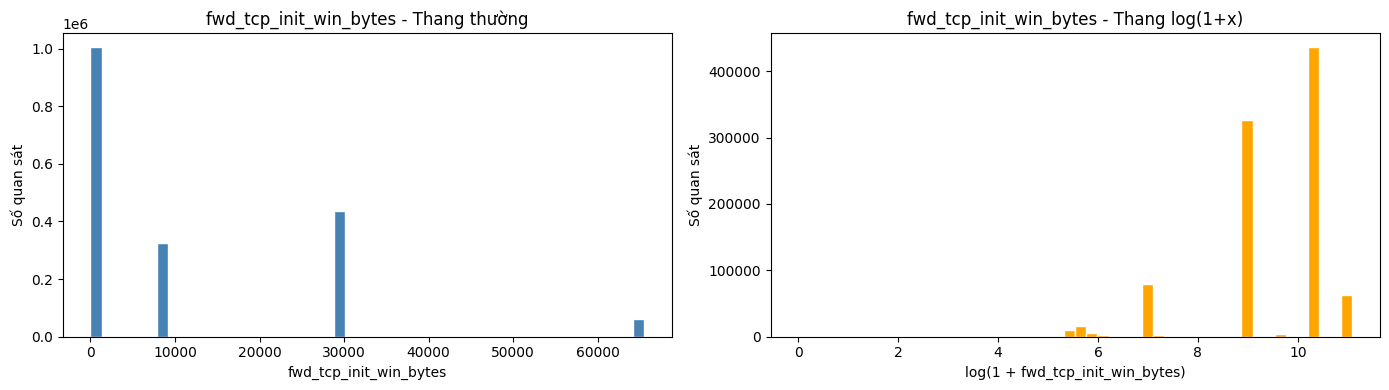

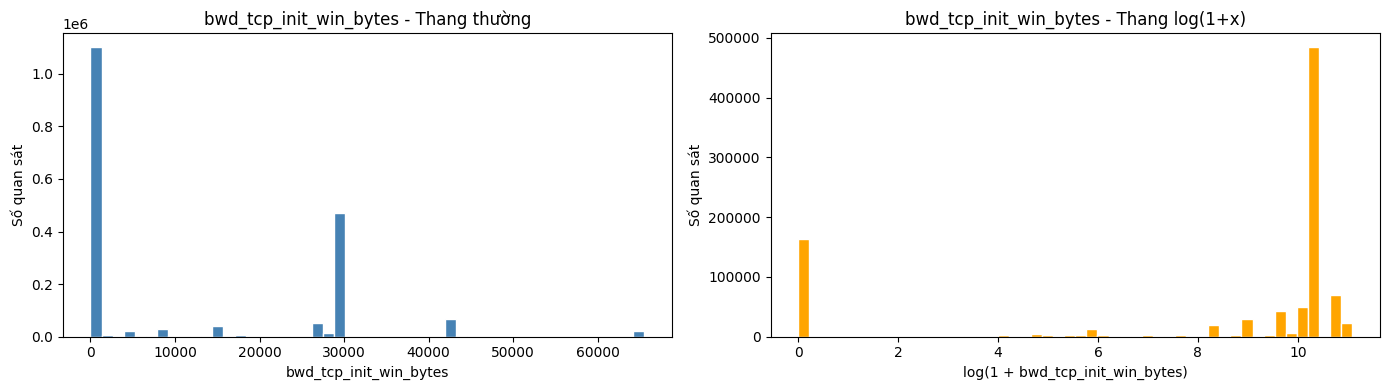

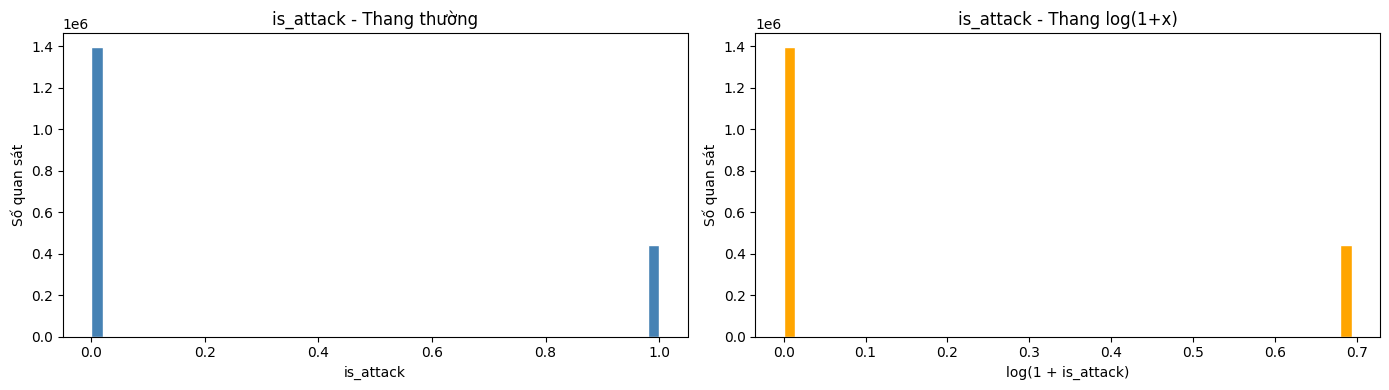

In [20]:
# Vẽ histogram trên thang thường và thang log(1+x)
for col in numeric_cols:
    data = df_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
    data_log = data[data >= 0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].hist(data, bins=50, color='steelblue', edgecolor='white')
    axes[0].set_title(f'{col} - Thang thường')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Số quan sát')

    axes[1].hist(np.log1p(data_log), bins=50, color='orange', edgecolor='white')
    axes[1].set_title(f'{col} - Thang log(1+x)')
    axes[1].set_xlabel(f'log(1 + {col})')
    axes[1].set_ylabel('Số quan sát')

    plt.tight_layout()
    plt.show()

=====
central tendency of src_port: {'mean': 48514.12232394267, 'median': 53448.0, 'mode': 123, 'min': 0, 'max': 65535, 'range': 65535}
=====
Dispersion of src_port: 
 {'range': 65535, 'q1': 42784.0, 'q3': 60181.0, 'iqr': 17397.0, 'var': 249868739.40033272, 'skew': -1.5804815617482648, 'kurtosis': 1.8512771518043154}
=====


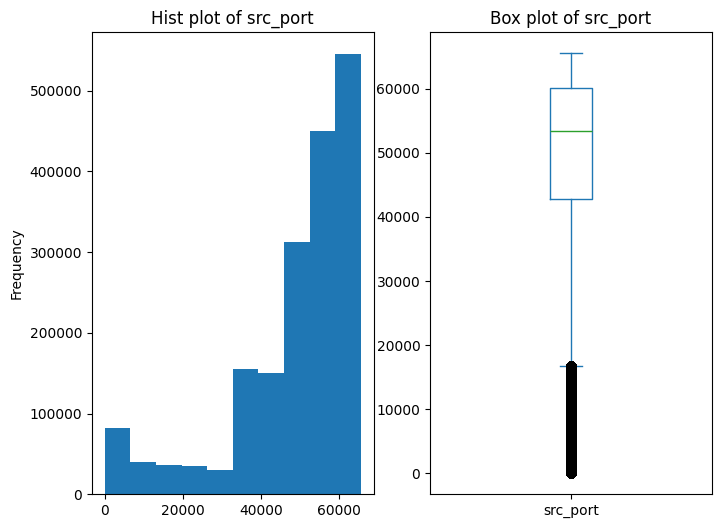

=====
central tendency of dst_port: {'mean': 1016.1741128425718, 'median': 80.0, 'mode': 53, 'min': 0, 'max': 65529, 'range': 65529}
=====
Dispersion of dst_port: 
 {'range': 65529, 'q1': 53.0, 'q3': 443.0, 'iqr': 390.0, 'var': 27212896.73689792, 'skew': 8.533264901907964, 'kurtosis': 79.43600746319251}
=====


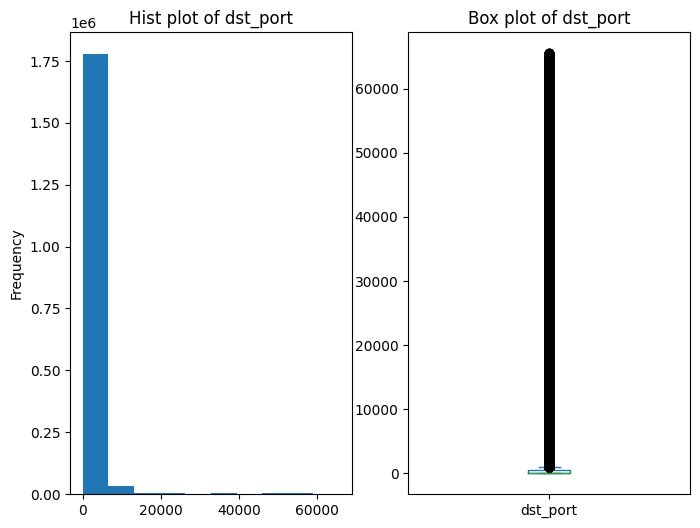

=====
central tendency of ip_prot: {'mean': 11.31387789265621, 'median': 6.0, 'mode': 6, 'min': 1, 'max': 132, 'range': 131}
=====
Dispersion of ip_prot: 
 {'range': 131, 'q1': 6.0, 'q3': 17.0, 'iqr': 11.0, 'var': 30.723871073210184, 'skew': 0.41246355390027384, 'kurtosis': 5.557236856901874}
=====


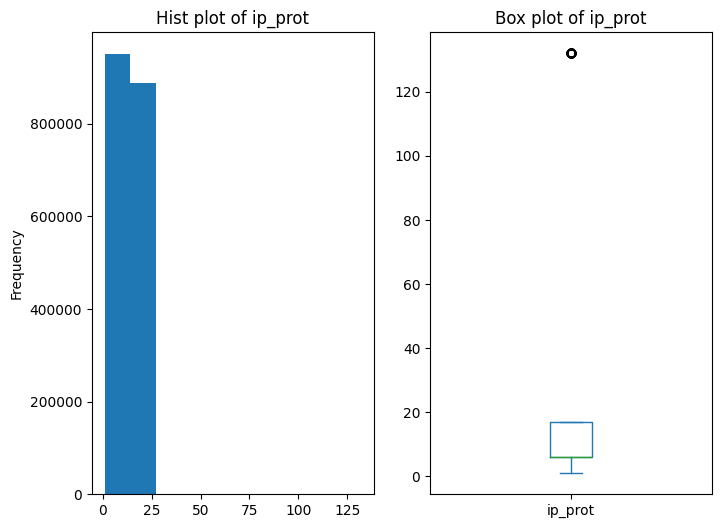

=====
central tendency of timestamp: {'mean': 1499276514235305.5, 'median': 1499263034295687.0, 'mode': 1499263206097907, 'min': 1499082997567312, 'max': 1499457759567285, 'range': 374761999973}
=====
Dispersion of timestamp: 
 {'range': 374761999973, 'q1': 1499175111853781.0, 'q3': 1499434874491744.0, 'iqr': 259762637963.0, 'var': 1.69686640218863e+22, 'skew': 0.07837808809656877, 'kurtosis': -1.331293900082861}
=====


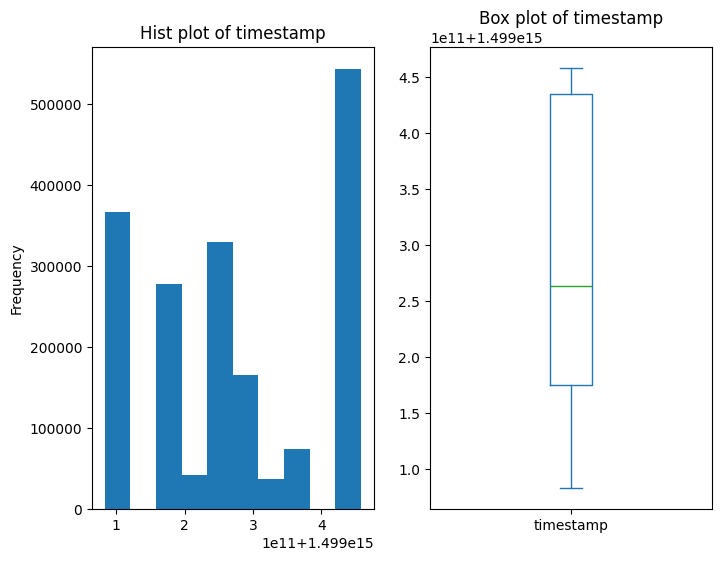

=====
central tendency of flow_duration: {'mean': 11993751.739467472, 'median': 62050.0, 'mode': 43, 'min': 0, 'max': 119999998, 'range': 119999998}
=====
Dispersion of flow_duration: 
 {'range': 119999998, 'q1': 324.0, 'q3': 1459715.5, 'iqr': 1459391.5, 'var': 955742291588323.4, 'skew': 2.676049516132347, 'kurtosis': 5.723619282058412}
=====


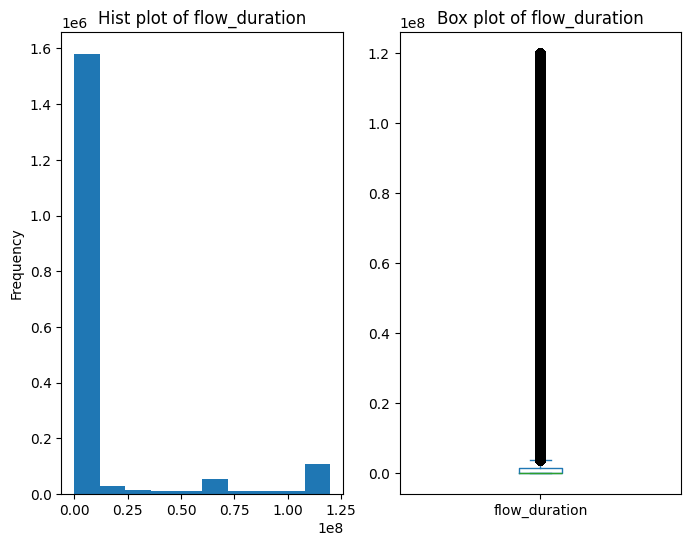

=====
central tendency of down_up_ratio: {'mean': 1.0513746334640903, 'median': 1.0, 'mode': 1.0, 'min': 0.0, 'max': 8.070423, 'range': 8.070423}
=====
Dispersion of down_up_ratio: 
 {'range': 8.070423, 'q1': 1.0, 'q3': 1.0, 'iqr': 0.0, 'var': 0.16663307018657603, 'skew': 1.1333418387955074, 'kurtosis': 4.620579327376066}
=====


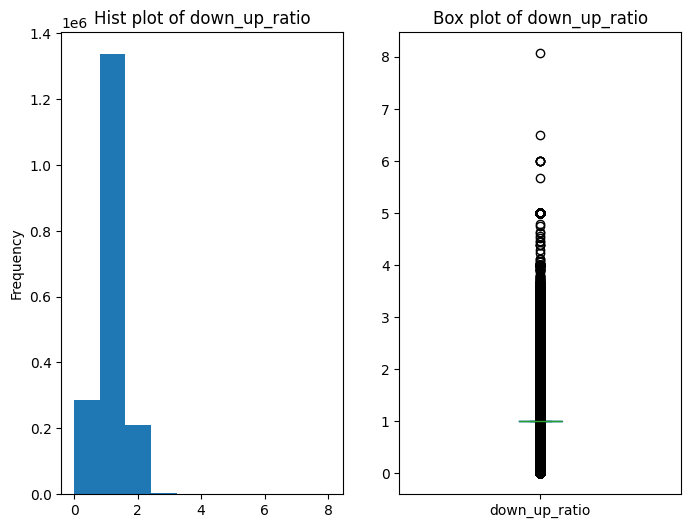

=====
central tendency of pkt_len_max: {'mean': 1388.6792731202972, 'median': 138.0, 'mode': 0.0, 'min': 0.0, 'max': 24820.0, 'range': 24820.0}
=====
Dispersion of pkt_len_max: 
 {'range': 24820.0, 'q1': 68.0, 'q3': 1460.0, 'iqr': 1392.0, 'var': 5644506.594456167, 'skew': 2.1524519386344783, 'kurtosis': 4.423959465336802}
=====


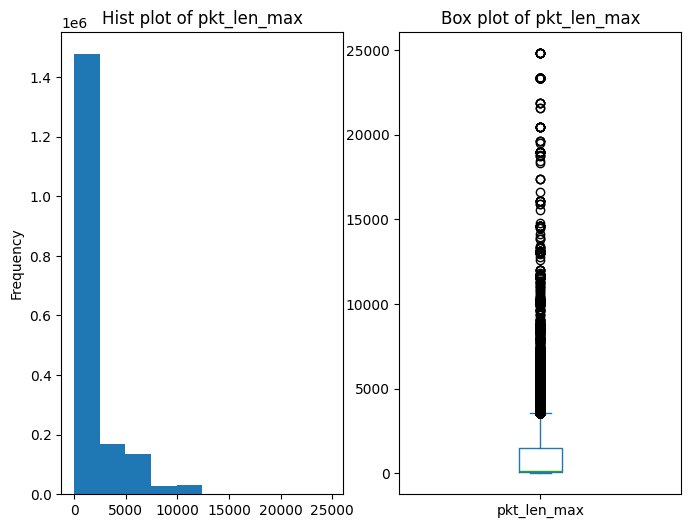

=====
central tendency of pkt_len_min: {'mean': 21.174455700087837, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 1448.0, 'range': 1448.0}
=====
Dispersion of pkt_len_min: 
 {'range': 1448.0, 'q1': 0.0, 'q3': 41.0, 'iqr': 41.0, 'var': 699.000741841684, 'skew': 7.311207945730882, 'kurtosis': 297.57771322254115}
=====


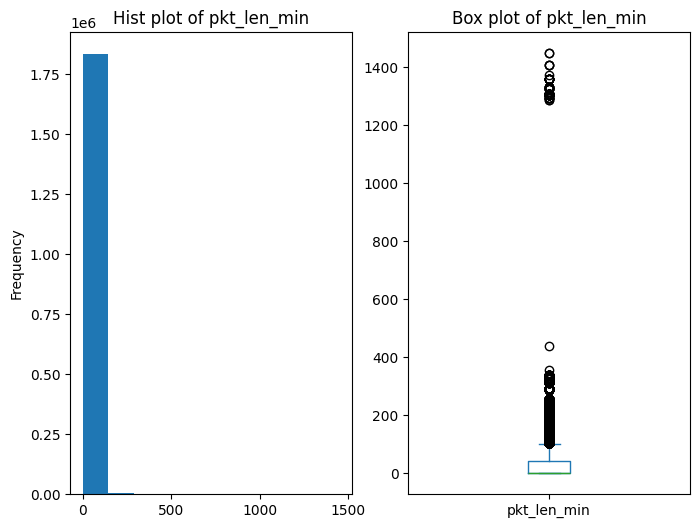

=====
central tendency of pkt_len_mean: {'mean': 305.18858299066113, 'median': 84.5, 'mode': 0.0, 'min': 0.0, 'max': 2391.375, 'range': 2391.375}
=====
Dispersion of pkt_len_mean: 
 {'range': 2391.375, 'q1': 53.0, 'q3': 274.8, 'iqr': 221.8, 'var': 213680.8095659552, 'skew': 1.7620046533599294, 'kurtosis': 1.5633280288211404}
=====


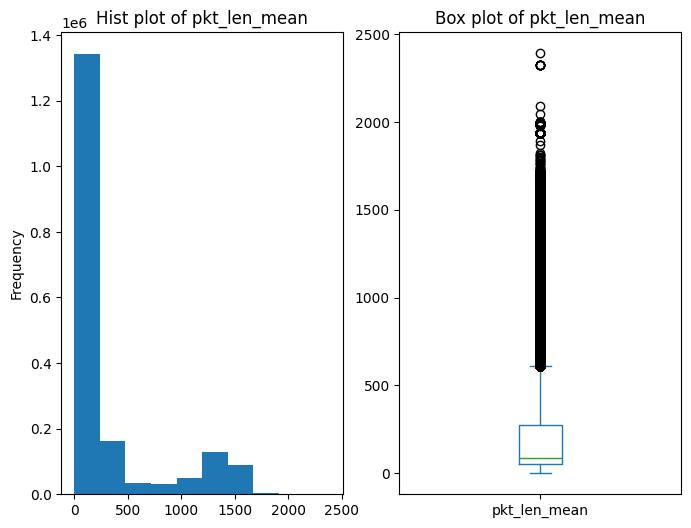

=====
central tendency of pkt_len_var: {'mean': 948497.1007454598, 'median': 3267.0, 'mode': 0.0, 'min': 0.0, 'max': 26865695.0, 'range': 26865695.0}
=====
Dispersion of pkt_len_var: 
 {'range': 26865695.0, 'q1': 341.333333, 'q3': 271906.807692, 'iqr': 271565.474359, 'var': 6901391839495.047, 'skew': 4.073046712921312, 'kurtosis': 19.55748383111322}
=====


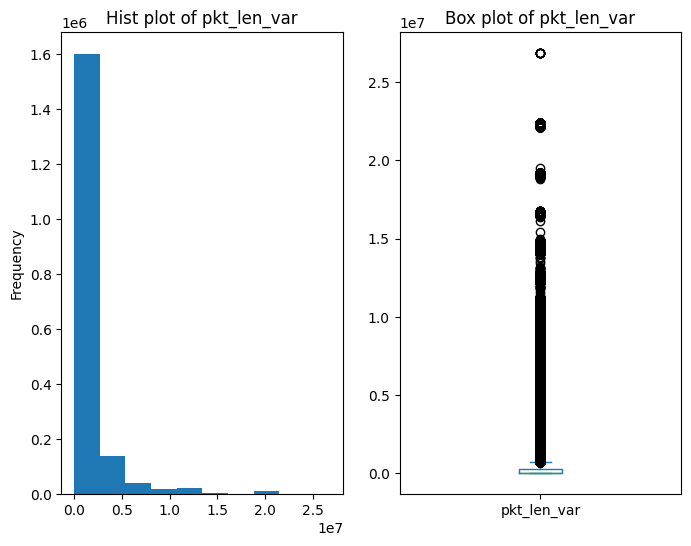

=====
central tendency of pkt_len_std: {'mean': 477.57964098427385, 'median': 57.157677, 'mode': 0.0, 'min': 0.0, 'max': 5183.212807, 'range': 5183.212807}
=====
Dispersion of pkt_len_std: 
 {'range': 5183.212807, 'q1': 18.475209, 'q3': 521.446841, 'iqr': 502.97163199999994, 'var': 720415.1793107875, 'skew': 2.2844609145598196, 'kurtosis': 4.889564326800744}
=====


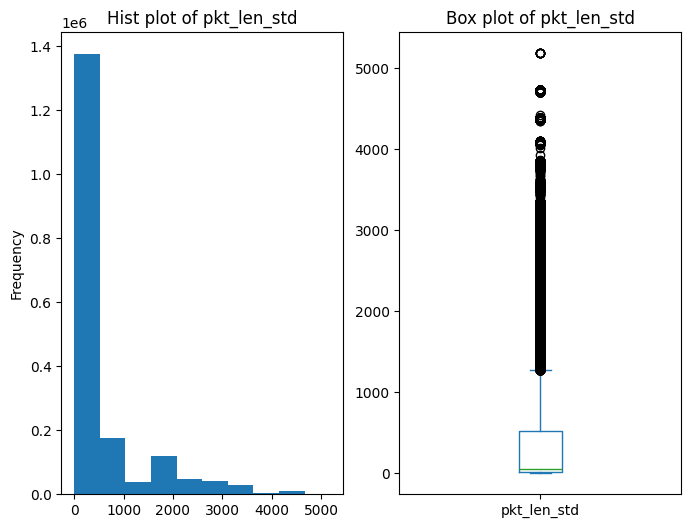

=====
central tendency of bytes_per_s: {'mean': 590284.6995366423, 'median': 5623.0890805, 'mode': 0.0, 'min': 0.0, 'max': 1983000000.0, 'range': 1983000000.0}
=====
Dispersion of bytes_per_s: 
 {'range': 1983000000.0, 'q1': 217.89949125, 'q3': 81667.864092, 'iqr': 81449.96460075, 'var': 73174856341219.14, 'skew': 114.46999585703905, 'kurtosis': 20839.930089047284}
=====


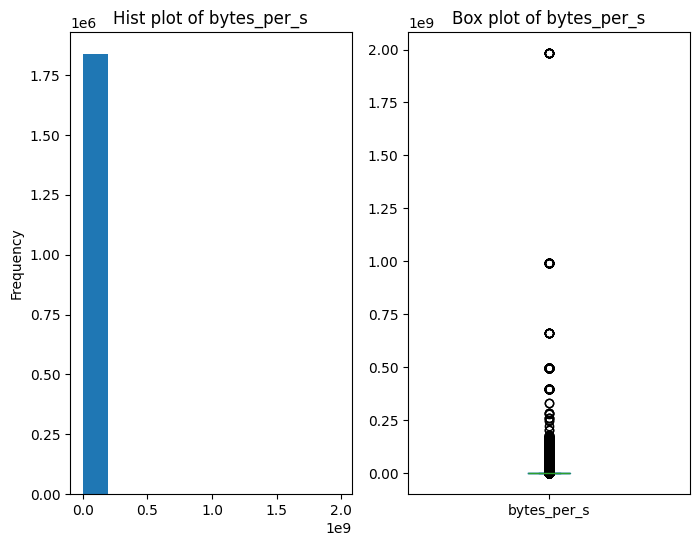

=====
central tendency of pkt_per_s: {'mean': 12335.991702468516, 'median': 65.272021, 'mode': 46511.627907, 'min': 0.0, 'max': 2000000.0, 'range': 2000000.0}
=====
Dispersion of pkt_per_s: 
 {'range': 2000000.0, 'q1': 6.62374725, 'q3': 12383.900929, 'iqr': 12377.27718175, 'var': 4144082804.2462783, 'skew': 17.028622528456335, 'kurtosis': 403.58579436581186}
=====


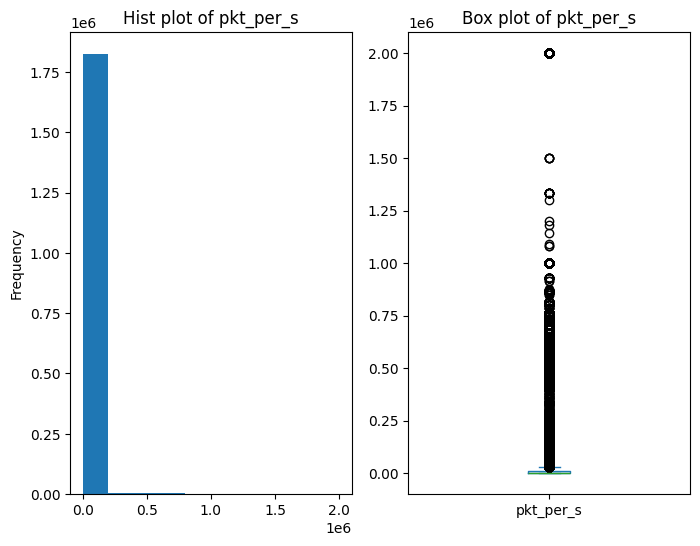

=====
central tendency of fwd_pkt_per_s: {'mean': 7515.6826609485115, 'median': 32.497075, 'mode': 23255.813953, 'min': 0.0, 'max': 2000000.0, 'range': 2000000.0}
=====
Dispersion of fwd_pkt_per_s: 
 {'range': 2000000.0, 'q1': 2.8047315, 'q3': 6116.207951, 'iqr': 6113.4032195, 'var': 2569768831.6396823, 'skew': 16.844664987420604, 'kurtosis': 382.4473769864198}
=====


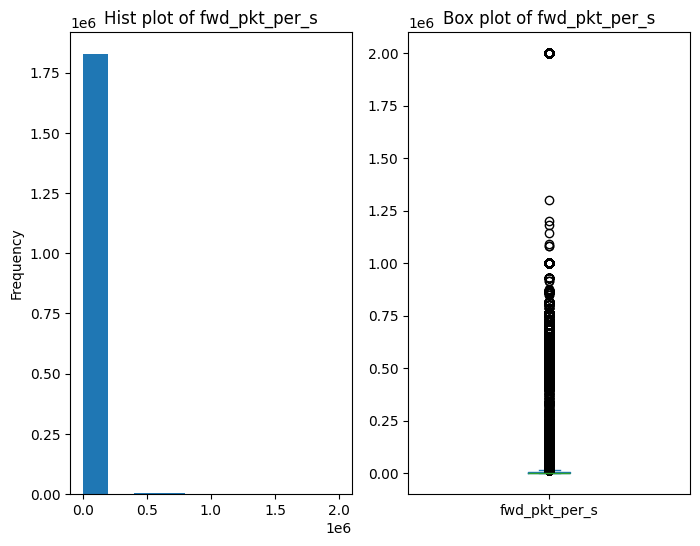

=====
central tendency of bwd_pkt_per_s: {'mean': 4820.309041508117, 'median': 32.926147, 'mode': 0.0, 'min': 0.0, 'max': 2000000.0, 'range': 2000000.0}
=====
Dispersion of bwd_pkt_per_s: 
 {'range': 2000000.0, 'q1': 3.2086759999999996, 'q3': 4618.937644, 'iqr': 4615.728967999999, 'var': 715549473.3065093, 'skew': 32.143906336951446, 'kurtosis': 1456.4756709213634}
=====


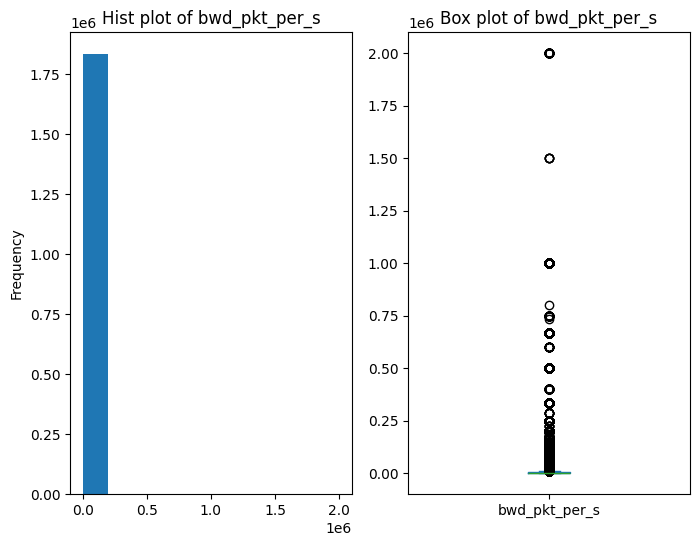

=====
central tendency of fwd_pkt_cnt: {'mean': 12.141304099378612, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 219759, 'range': 219759}
=====
Dispersion of fwd_pkt_cnt: 
 {'range': 219759, 'q1': 2.0, 'q3': 5.0, 'iqr': 3.0, 'var': 864879.3735233056, 'skew': 197.18406111888828, 'kurtosis': 40167.429762908716}
=====


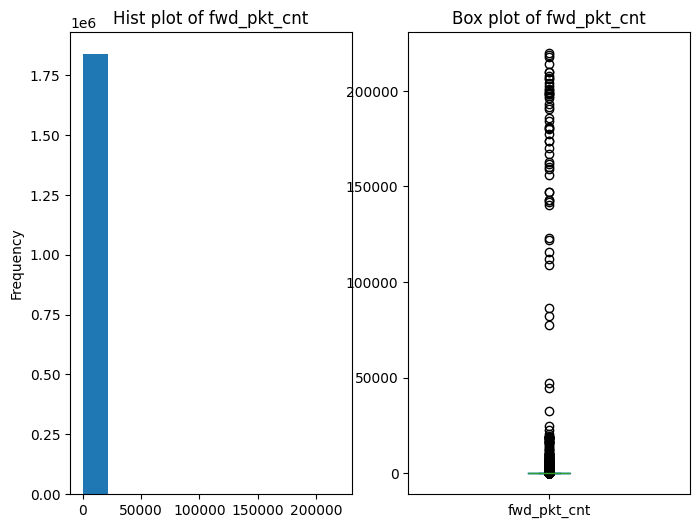

=====
central tendency of fwd_pkt_len_tot: {'mean': 575.187670952567, 'median': 82.0, 'mode': 0, 'min': 0, 'max': 3127392, 'range': 3127392}
=====
Dispersion of fwd_pkt_len_tot: 
 {'range': 3127392, 'q1': 50.0, 'q3': 362.0, 'iqr': 312.0, 'var': 29738698.130864773, 'skew': 231.28283122727902, 'kurtosis': 99307.59152349224}
=====


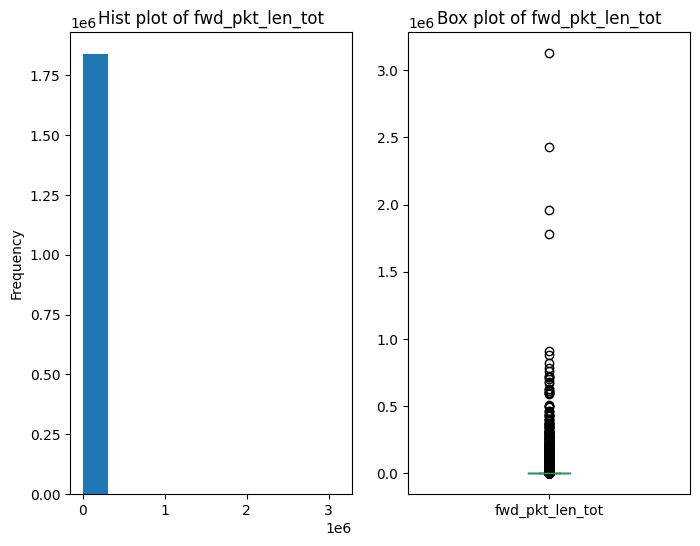

=====
central tendency of fwd_pkt_len_max: {'mean': 215.6581373149794, 'median': 46.0, 'mode': 0.0, 'min': 0.0, 'max': 24820.0, 'range': 24820.0}
=====
Dispersion of fwd_pkt_len_max: 
 {'range': 24820.0, 'q1': 32.0, 'q3': 324.0, 'iqr': 292.0, 'var': 229203.06668769167, 'skew': 11.467707345351558, 'kurtosis': 343.6213302047256}
=====


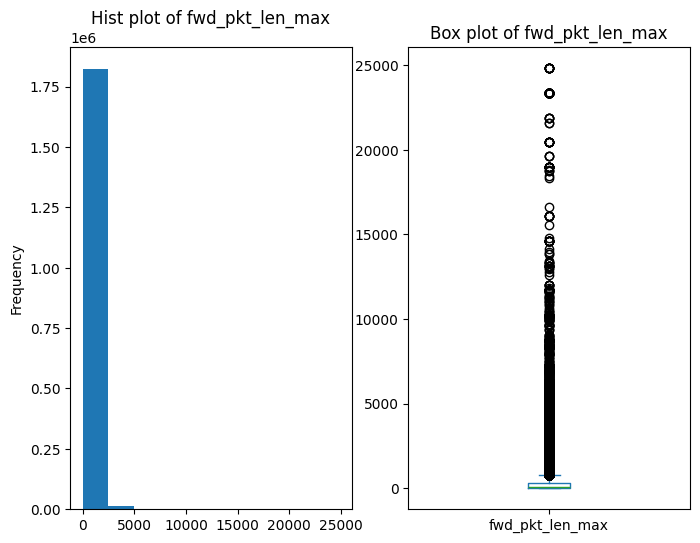

=====
central tendency of fwd_pkt_len_min: {'mean': 21.435128092656427, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 2293.0, 'range': 2293.0}
=====
Dispersion of fwd_pkt_len_min: 
 {'range': 2293.0, 'q1': 0.0, 'q3': 41.0, 'iqr': 41.0, 'var': 1272.714372670487, 'skew': 22.144180055924405, 'kurtosis': 873.8026047729203}
=====


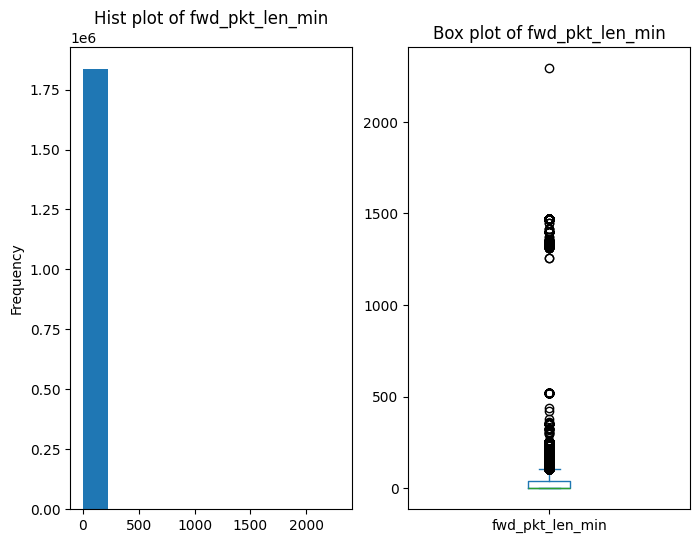

=====
central tendency of fwd_pkt_len_mean: {'mean': 60.66870248781984, 'median': 43.0, 'mode': 0.0, 'min': 0.0, 'max': 5940.514286, 'range': 5940.514286}
=====
Dispersion of fwd_pkt_len_mean: 
 {'range': 5940.514286, 'q1': 30.0, 'q3': 63.0, 'iqr': 33.0, 'var': 9752.598524789188, 'skew': 11.58498665433857, 'kurtosis': 257.6521128723365}
=====


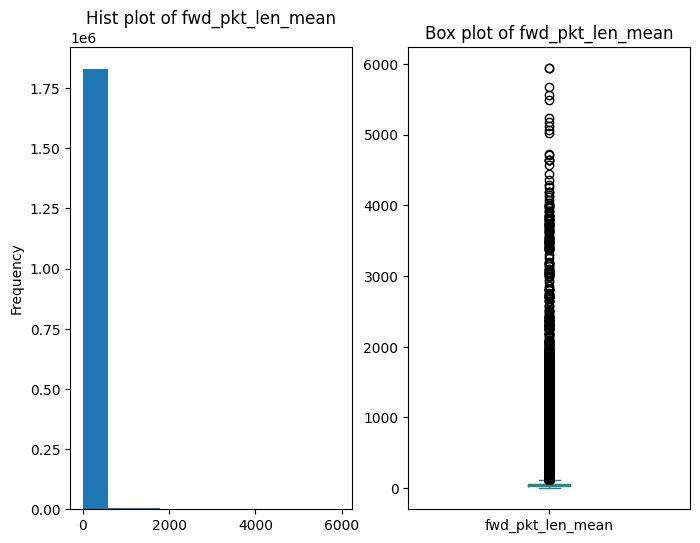

=====
central tendency of fwd_pkt_len_std: {'mean': 71.15021605705586, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 7127.074364, 'range': 7127.074364}
=====
Dispersion of fwd_pkt_len_std: 
 {'range': 7127.074364, 'q1': 0.0, 'q3': 108.75, 'iqr': 108.75, 'var': 23996.08135714062, 'skew': 6.308274550192978, 'kurtosis': 86.96053353916034}
=====


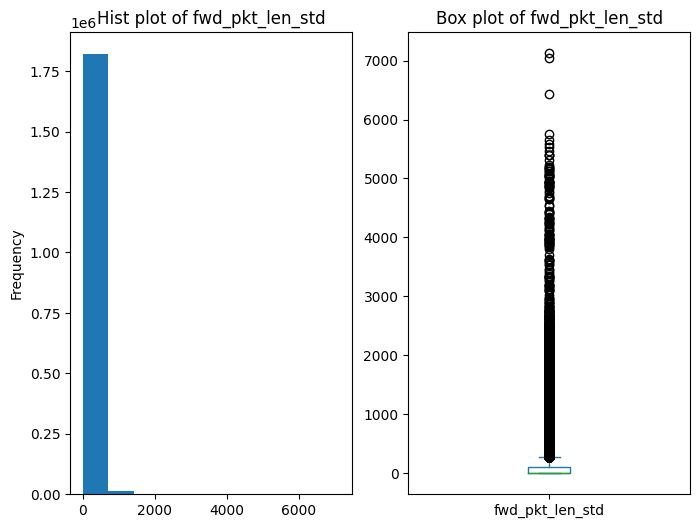

=====
central tendency of fwd_pkt_hdr_len_tot: {'mean': 277.03681636660286, 'median': 32.0, 'mode': 16, 'min': 0, 'max': 4644908, 'range': 4644908}
=====
Dispersion of fwd_pkt_hdr_len_tot: 
 {'range': 4644908, 'q1': 16.0, 'q3': 132.0, 'iqr': 116.0, 'var': 377718318.2977403, 'skew': 196.70047404650057, 'kurtosis': 40094.65799959114}
=====


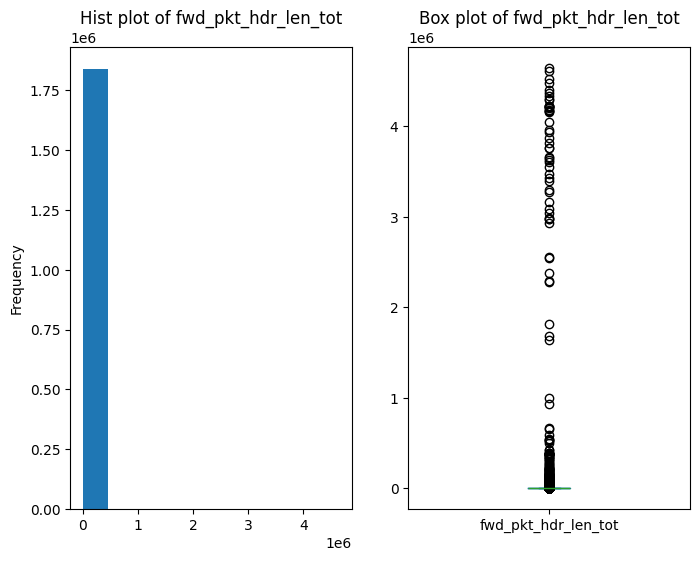

=====
central tendency of fwd_pkt_hdr_len_min: {'mean': 17.933927547132026, 'median': 20.0, 'mode': 8, 'min': 0, 'max': 44, 'range': 44}
=====
Dispersion of fwd_pkt_hdr_len_min: 
 {'range': 44, 'q1': 8.0, 'q3': 32.0, 'iqr': 24.0, 'var': 116.61840551339246, 'skew': 0.5158729451617842, 'kurtosis': -1.1913438015514348}
=====


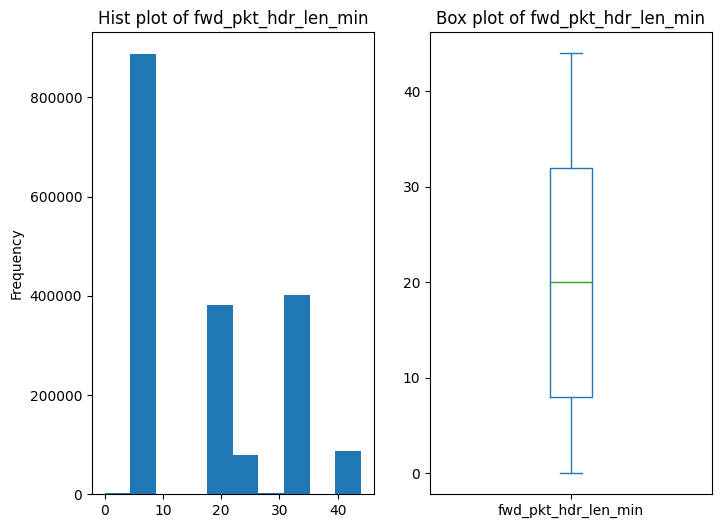

=====
central tendency of fwd_non_empty_pkt_cnt: {'mean': 2.7518163285075685, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 2388, 'range': 2388}
=====
Dispersion of fwd_non_empty_pkt_cnt: 
 {'range': 2388, 'q1': 1.0, 'q3': 3.0, 'iqr': 2.0, 'var': 41.96046473164504, 'skew': 89.03110479548236, 'kurtosis': 21033.39326485712}
=====


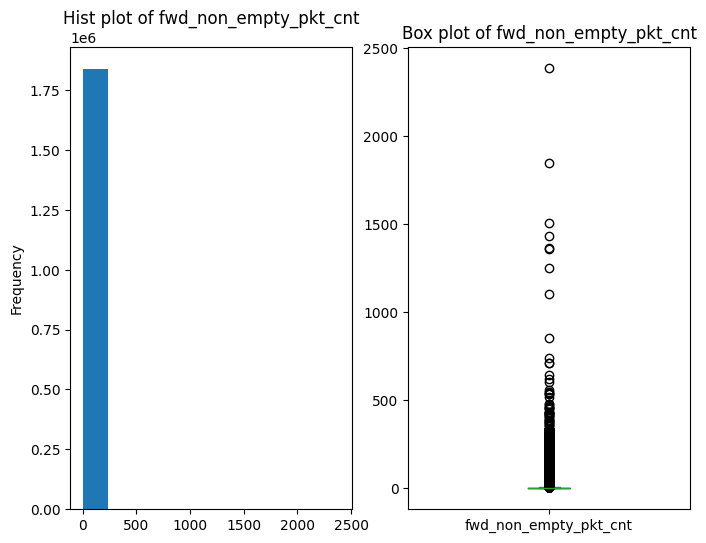

=====
central tendency of bwd_pkt_cnt: {'mean': 14.674267400563156, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 291922, 'range': 291922}
=====
Dispersion of bwd_pkt_cnt: 
 {'range': 291922, 'q1': 1.0, 'q3': 6.0, 'iqr': 5.0, 'var': 1530484.5851543096, 'skew': 197.48605271775045, 'kurtosis': 40359.24538658912}
=====


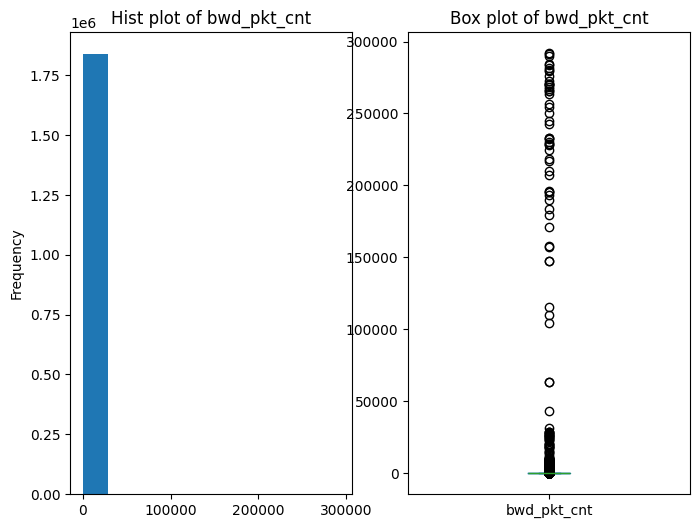

=====
central tendency of bwd_pkt_len_tot: {'mean': 23963.518453897635, 'median': 234.0, 'mode': 11595, 'min': 0, 'max': 655452323, 'range': 655452323}
=====
Dispersion of bwd_pkt_len_tot: 
 {'range': 655452323, 'q1': 110.0, 'q3': 4406.0, 'iqr': 4296.0, 'var': 7883885092088.172, 'skew': 197.05977837269836, 'kurtosis': 40045.13442191729}
=====


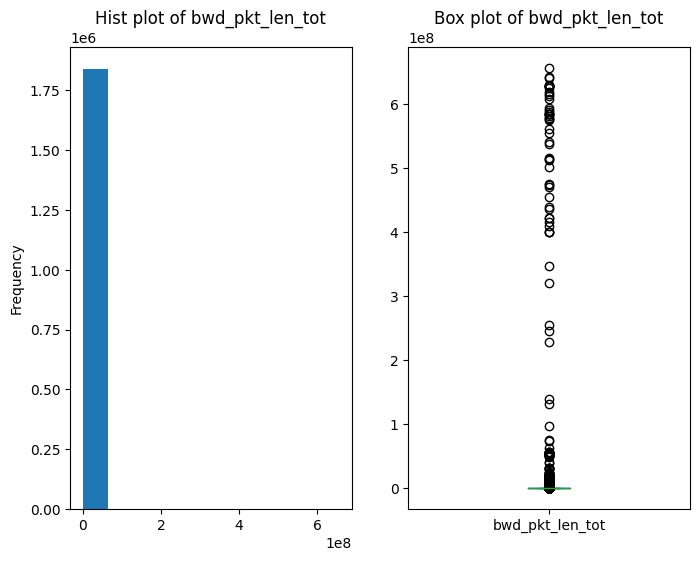

=====
central tendency of bwd_pkt_len_max: {'mean': 1351.6539892832536, 'median': 134.0, 'mode': 0.0, 'min': 0.0, 'max': 19530.0, 'range': 19530.0}
=====
Dispersion of bwd_pkt_len_max: 
 {'range': 19530.0, 'q1': 67.0, 'q3': 1460.0, 'iqr': 1393.0, 'var': 5591111.522248175, 'skew': 2.1673025942036115, 'kurtosis': 4.271035234429739}
=====


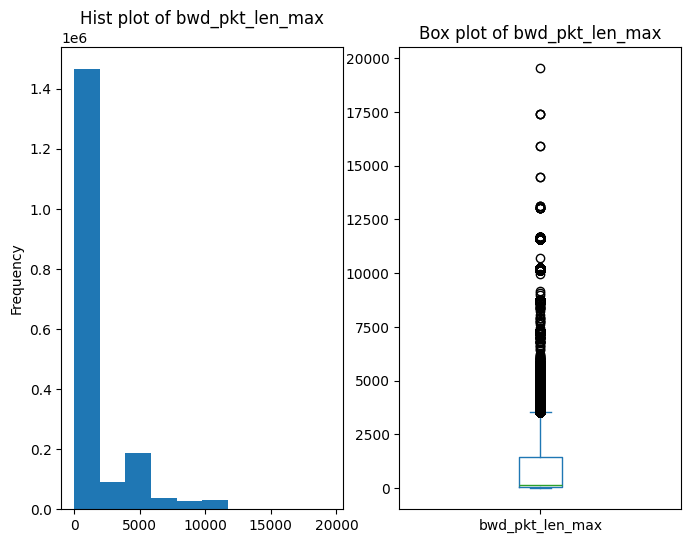

=====
central tendency of bwd_pkt_len_min: {'mean': 0.15506792388345456, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 1983.0, 'range': 1983.0}
=====
Dispersion of bwd_pkt_len_min: 
 {'range': 1983.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 36.32794198356374, 'skew': 87.62961213625884, 'kurtosis': 16790.934705899977}
=====


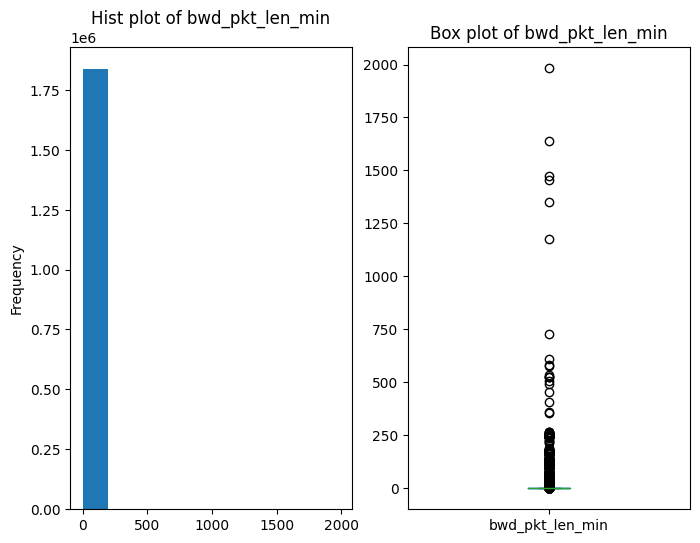

=====
central tendency of bwd_pkt_len_mean: {'mean': 475.90304423317355, 'median': 122.0, 'mode': 0.0, 'min': 0.0, 'max': 4370.686524, 'range': 4370.686524}
=====
Dispersion of bwd_pkt_len_mean: 
 {'range': 4370.686524, 'q1': 61.0, 'q3': 459.893275, 'iqr': 398.893275, 'var': 544347.0700260648, 'skew': 1.794540606237313, 'kurtosis': 1.9164072163178822}
=====


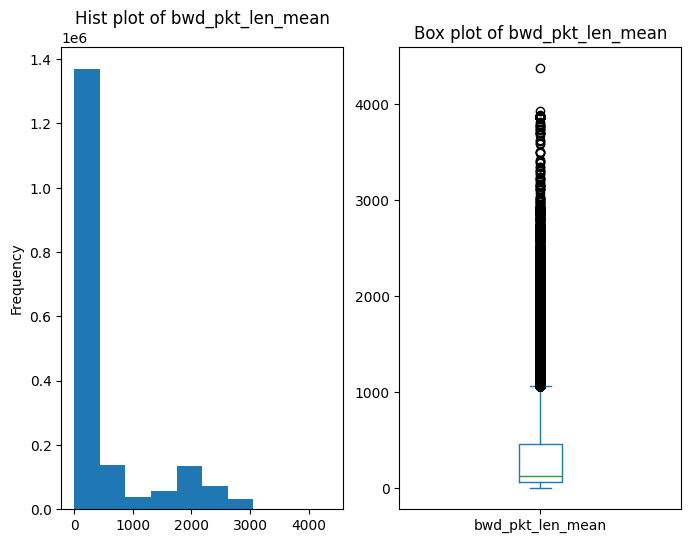

=====
central tendency of bwd_pkt_len_std: {'mean': 532.2374566290111, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 6715.738331, 'range': 6715.738331}
=====
Dispersion of bwd_pkt_len_std: 
 {'range': 6715.738331, 'q1': 0.0, 'q3': 635.9283745, 'iqr': 635.9283745, 'var': 1090600.404727226, 'skew': 2.5461353481502225, 'kurtosis': 6.773523627604882}
=====


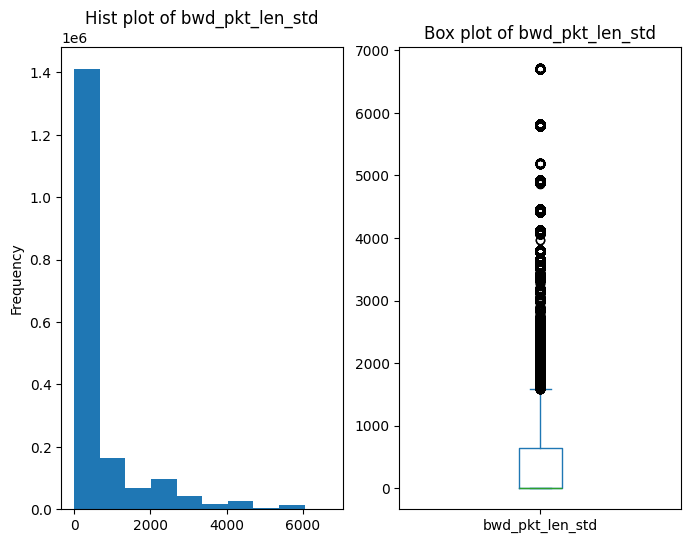

=====
central tendency of bwd_pkt_hdr_len_tot: {'mean': 328.04939107416715, 'median': 20.0, 'mode': 16, 'min': 0, 'max': 5838440, 'range': 5838440}
=====
Dispersion of bwd_pkt_hdr_len_tot: 
 {'range': 5838440, 'q1': 16.0, 'q3': 168.0, 'iqr': 152.0, 'var': 613767074.5162479, 'skew': 196.7949893953519, 'kurtosis': 40153.908955837134}
=====


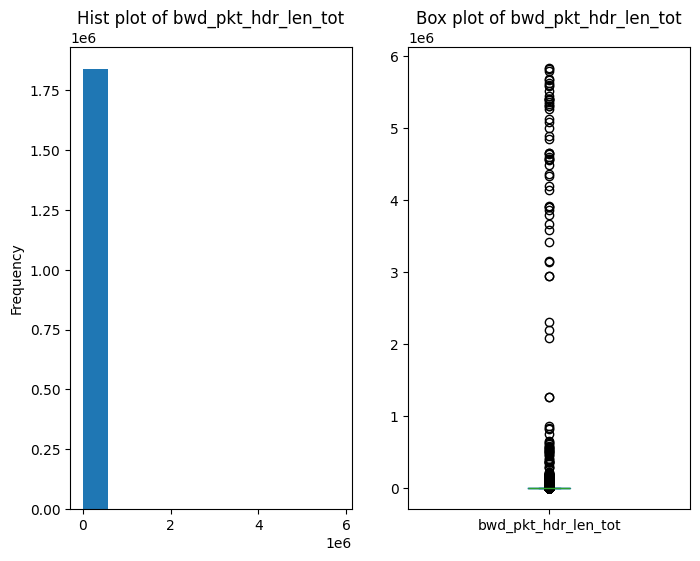

=====
central tendency of bwd_pkt_hdr_len_min: {'mean': 16.843333707029885, 'median': 20.0, 'mode': 8, 'min': 0, 'max': 44, 'range': 44}
=====
Dispersion of bwd_pkt_hdr_len_min: 
 {'range': 44, 'q1': 8.0, 'q3': 20.0, 'iqr': 12.0, 'var': 98.30644068946921, 'skew': 0.5055976931972149, 'kurtosis': -1.1465587704611089}
=====


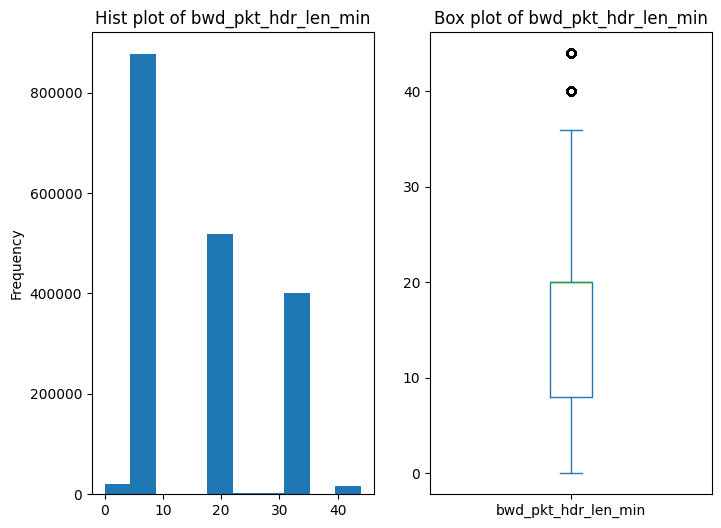

=====
central tendency of bwd_non_empty_pkt_cnt: {'mean': 12.681925640191173, 'median': 2.0, 'mode': 2, 'min': 0, 'max': 291805, 'range': 291805}
=====
Dispersion of bwd_non_empty_pkt_cnt: 
 {'range': 291805, 'q1': 1.0, 'q3': 3.0, 'iqr': 2.0, 'var': 1529175.6202502323, 'skew': 197.50802870058877, 'kurtosis': 40364.7410962198}
=====


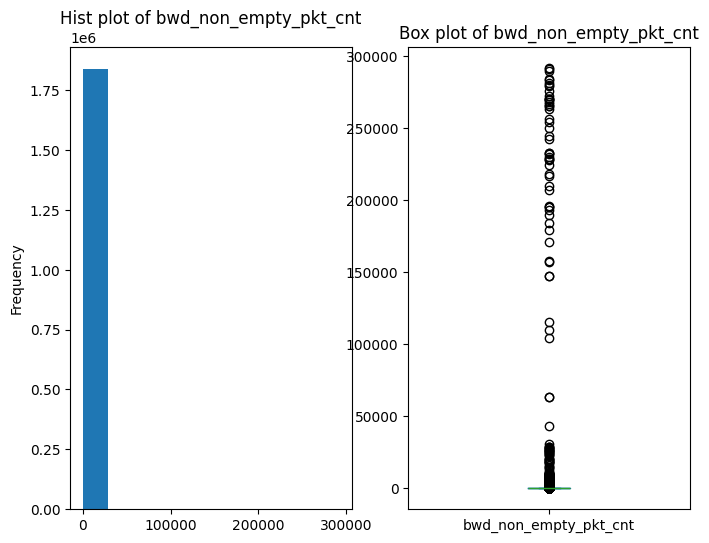

=====
central tendency of iat_max: {'mean': 4592724.5585997915, 'median': 53271.5, 'mode': 43.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of iat_max: 
 {'range': 119999735.0, 'q1': 290.0, 'q3': 1213640.5, 'iqr': 1213350.5, 'var': 203917404031448.28, 'skew': 4.657750589832414, 'kurtosis': 23.78315120577175}
=====


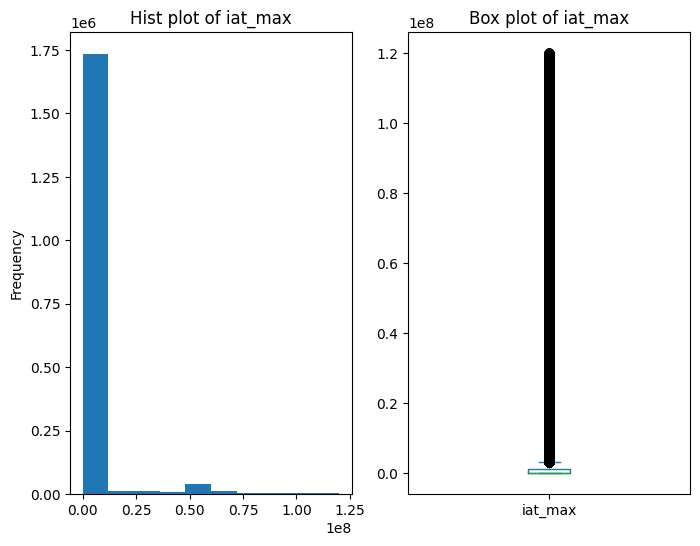

=====
central tendency of iat_min: {'mean': 18202.355479026373, 'median': 4.0, 'mode': 3.0, 'min': -14.0, 'max': 69000029.0, 'range': 69000043.0}
=====
Dispersion of iat_min: 
 {'range': 69000043.0, 'q1': 3.0, 'q3': 50.0, 'iqr': 47.0, 'var': 62781348213.70424, 'skew': 129.05727360778639, 'kurtosis': 27277.450667939265}
=====


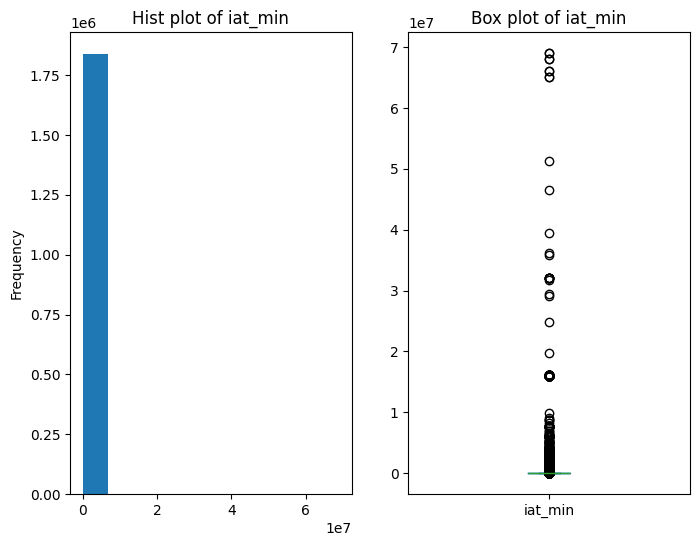

=====
central tendency of iat_mean: {'mean': 879279.8647131164, 'median': 20391.666667, 'mode': 43.0, 'min': 0.0, 'max': 69000029.0, 'range': 69000029.0}
=====
Dispersion of iat_mean: 
 {'range': 69000029.0, 'q1': 107.0, 'q3': 187650.1857145, 'iqr': 187543.1857145, 'var': 11868367902807.402, 'skew': 7.239257838965045, 'kurtosis': 60.926482679253375}
=====


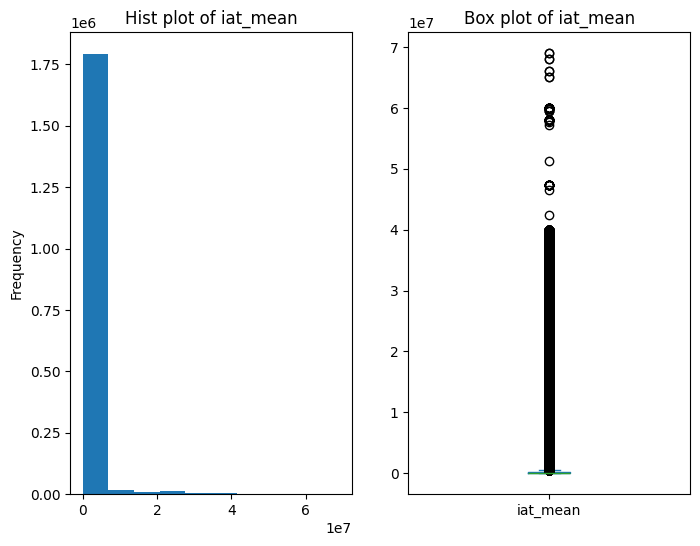

=====
central tendency of iat_std: {'mean': 1721530.78238147, 'median': 17740.544665, 'mode': 0.0, 'min': 0.0, 'max': 84819214.856571, 'range': 84819214.856571}
=====
Dispersion of iat_std: 
 {'range': 84819214.856571, 'q1': 56.589163, 'q3': 419117.63525225, 'iqr': 419061.04608925, 'var': 38680529494720.36, 'skew': 6.518426199003155, 'kurtosis': 49.67452264732382}
=====


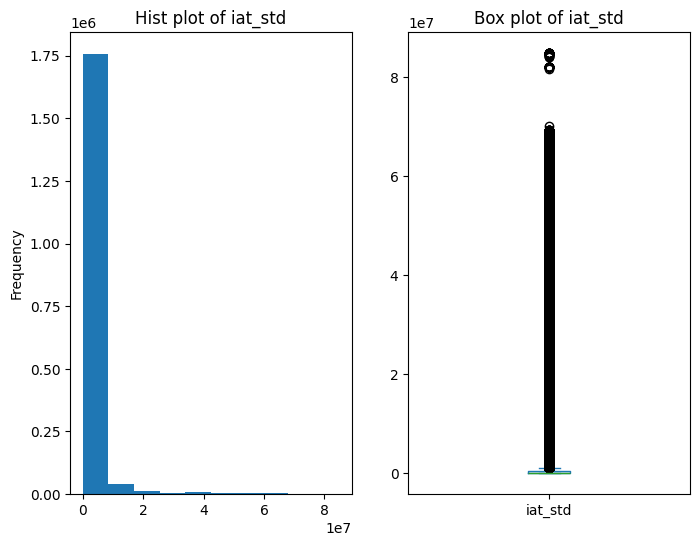

=====
central tendency of fwd_iat_tot: {'mean': 11630502.575558722, 'median': 49.0, 'mode': 0, 'min': 0, 'max': 119999998, 'range': 119999998}
=====
Dispersion of fwd_iat_tot: 
 {'range': 119999998, 'q1': 1.0, 'q3': 594063.75, 'iqr': 594062.75, 'var': 947903453487926.1, 'skew': 2.7133227793324317, 'kurtosis': 5.91497443881138}
=====


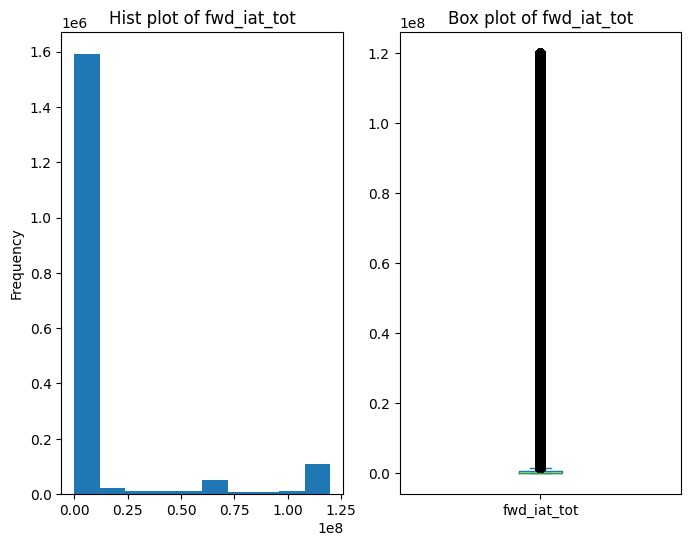

=====
central tendency of fwd_iat_max: {'mean': 4417167.388732396, 'median': 49.0, 'mode': 0.0, 'min': 0.0, 'max': 119999869.0, 'range': 119999869.0}
=====
Dispersion of fwd_iat_max: 
 {'range': 119999869.0, 'q1': 1.0, 'q3': 263761.5, 'iqr': 263760.5, 'var': 203349259047429.7, 'skew': 4.68940436932519, 'kurtosis': 24.062782380458412}
=====


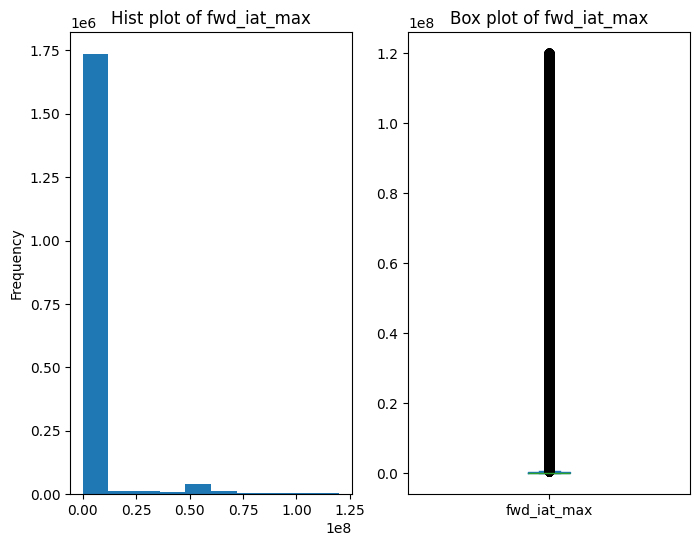

=====
central tendency of fwd_iat_min: {'mean': 1214749.340798194, 'median': 3.0, 'mode': 0.0, 'min': 0.0, 'max': 119999570.0, 'range': 119999570.0}
=====
Dispersion of fwd_iat_min: 
 {'range': 119999570.0, 'q1': 1.0, 'q3': 49.0, 'iqr': 48.0, 'var': 90007797267299.8, 'skew': 8.911015696355364, 'kurtosis': 83.81610193522519}
=====


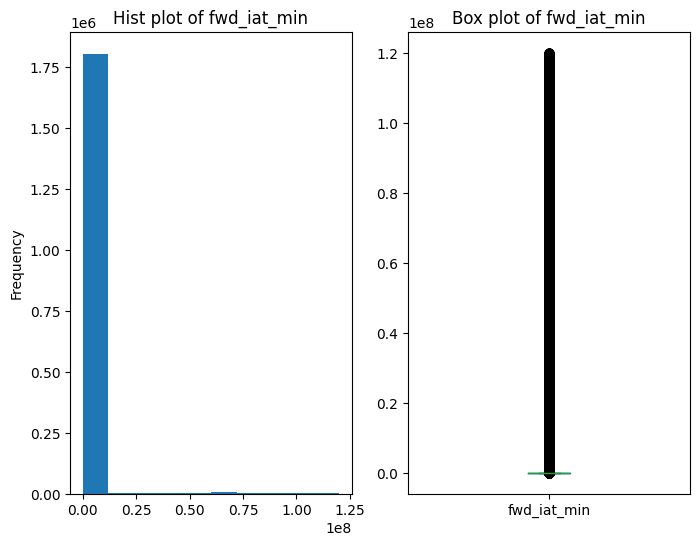

=====
central tendency of fwd_iat_mean: {'mean': 2005897.0636099617, 'median': 49.0, 'mode': 0.0, 'min': 0.0, 'max': 119999570.0, 'range': 119999570.0}
=====
Dispersion of fwd_iat_mean: 
 {'range': 119999570.0, 'q1': 1.0, 'q3': 81101.5, 'iqr': 81100.5, 'var': 95219232375038.03, 'skew': 8.112063399904024, 'kurtosis': 72.55961540535347}
=====


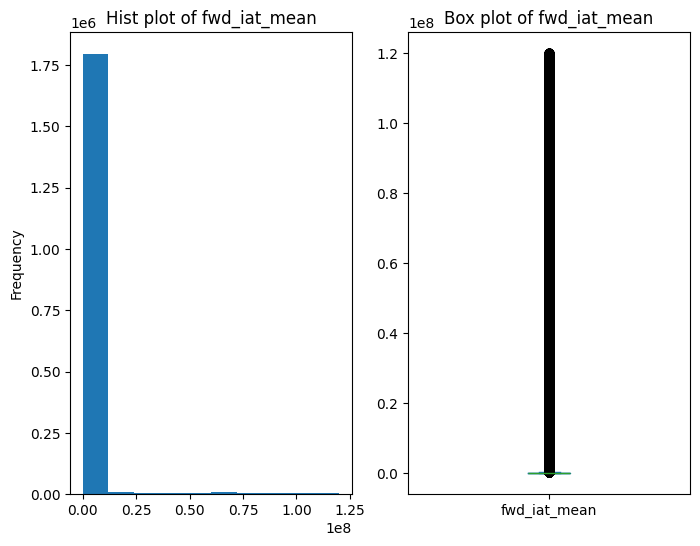

=====
central tendency of fwd_iat_std: {'mean': 1244303.5837361068, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 83228041.458245, 'range': 83228041.458245}
=====
Dispersion of fwd_iat_std: 
 {'range': 83228041.458245, 'q1': 0.0, 'q3': 56931.3376625, 'iqr': 56931.3376625, 'var': 17935867489802.535, 'skew': 7.255411496851478, 'kurtosis': 75.54072917705889}
=====


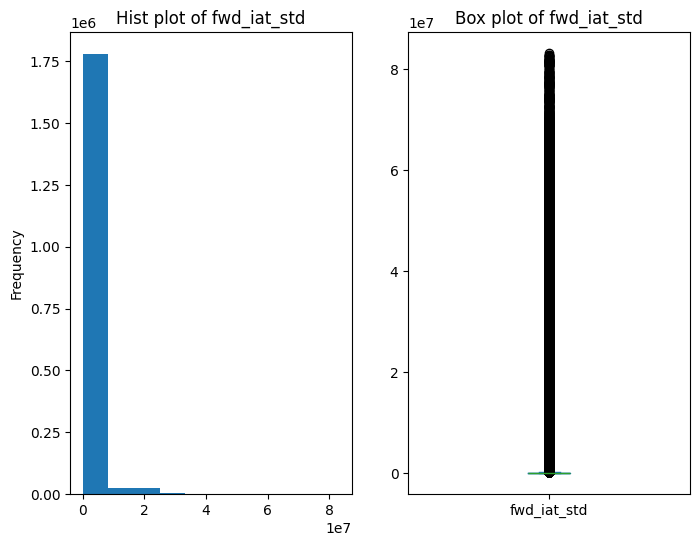

=====
central tendency of bwd_iat_tot: {'mean': 10910015.265792942, 'median': 48.0, 'mode': 0, 'min': 0, 'max': 119999992, 'range': 119999992}
=====
Dispersion of bwd_iat_tot: 
 {'range': 119999992, 'q1': 0.0, 'q3': 239181.75, 'iqr': 239181.75, 'var': 902989340509231.6, 'skew': 2.757984373116458, 'kurtosis': 6.118432001940669}
=====


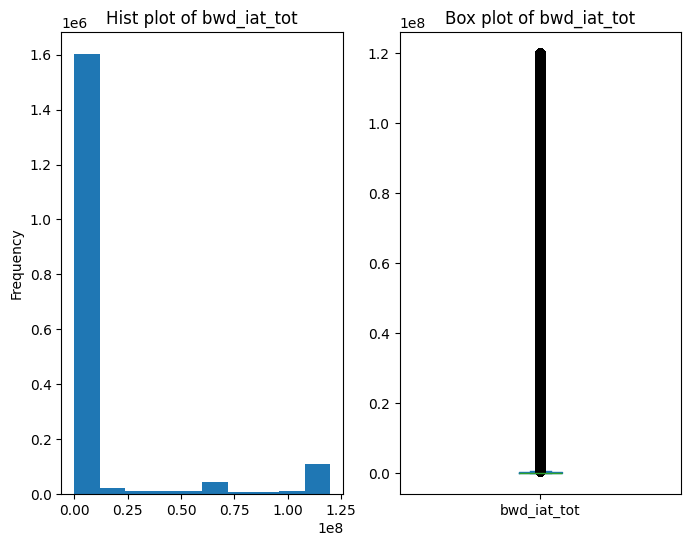

=====
central tendency of bwd_iat_max: {'mean': 3891474.0287456093, 'median': 48.0, 'mode': 0.0, 'min': 0.0, 'max': 119991381.0, 'range': 119991381.0}
=====
Dispersion of bwd_iat_max: 
 {'range': 119991381.0, 'q1': 0.0, 'q3': 155140.5, 'iqr': 155140.5, 'var': 189767788431242.94, 'skew': 4.956180649095514, 'kurtosis': 26.626550434000656}
=====


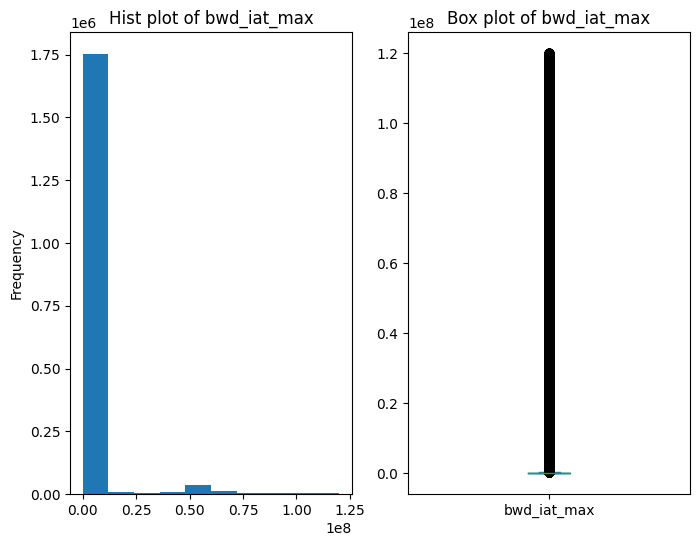

=====
central tendency of bwd_iat_min: {'mean': 1353950.3193184428, 'median': 3.0, 'mode': 0.0, 'min': 0.0, 'max': 119976977.0, 'range': 119976977.0}
=====
Dispersion of bwd_iat_min: 
 {'range': 119976977.0, 'q1': 0.0, 'q3': 48.0, 'iqr': 48.0, 'var': 96334470807342.5, 'skew': 8.327485050578817, 'kurtosis': 73.72707907197429}
=====


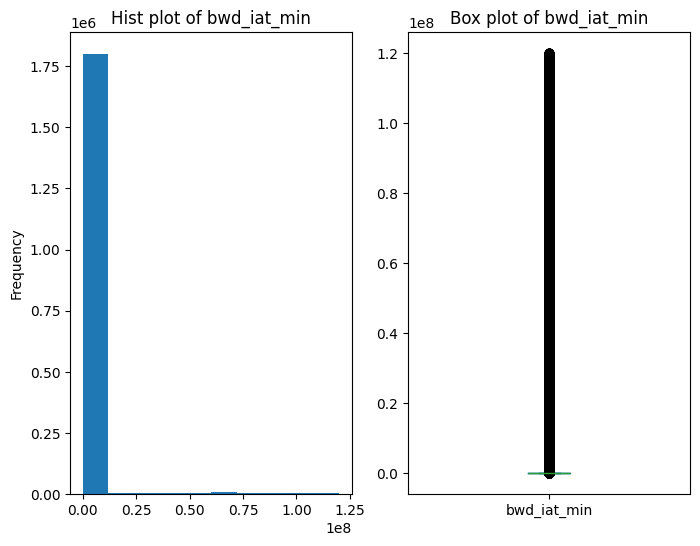

=====
central tendency of bwd_iat_mean: {'mean': 2072981.3334411308, 'median': 48.0, 'mode': 0.0, 'min': 0.0, 'max': 119976977.0, 'range': 119976977.0}
=====
Dispersion of bwd_iat_mean: 
 {'range': 119976977.0, 'q1': 0.0, 'q3': 43910.149999999994, 'iqr': 43910.149999999994, 'var': 104215842303338.56, 'skew': 7.493003075459294, 'kurtosis': 61.835607358372584}
=====


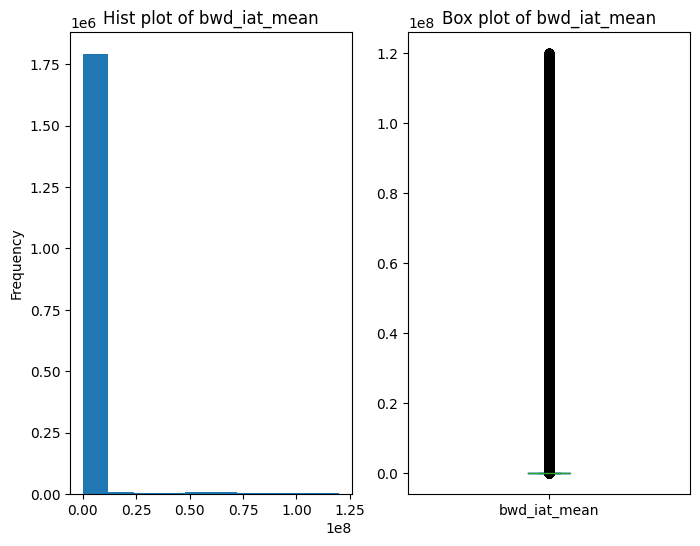

=====
central tendency of bwd_iat_std: {'mean': 999934.0261152615, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 83273028.298771, 'range': 83273028.298771}
=====
Dispersion of bwd_iat_std: 
 {'range': 83273028.298771, 'q1': 0.0, 'q3': 58790.42451775, 'iqr': 58790.42451775, 'var': 17634030560644.13, 'skew': 9.171689196342356, 'kurtosis': 117.31913616461185}
=====


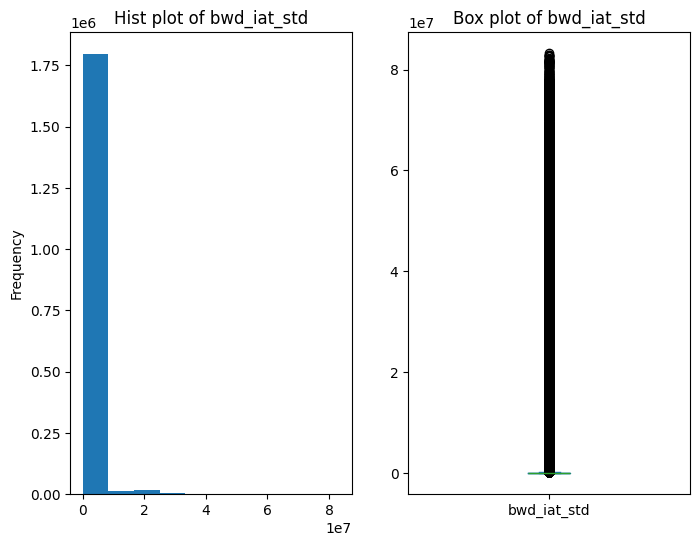

=====
central tendency of active_max: {'mean': 182706.70709029344, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 110097488.0, 'range': 110097488.0}
=====
Dispersion of active_max: 
 {'range': 110097488.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 1220756283782.718, 'skew': 24.20444295488613, 'kurtosis': 1344.2114350649065}
=====


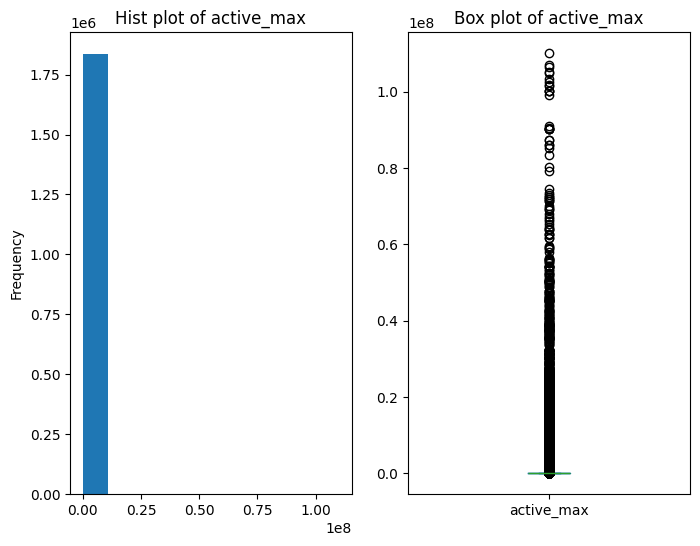

=====
central tendency of active_min: {'mean': 62362.70855968279, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 110097488.0, 'range': 110097488.0}
=====
Dispersion of active_min: 
 {'range': 110097488.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 410026178454.57404, 'skew': 49.461126100786984, 'kurtosis': 5721.584624426495}
=====


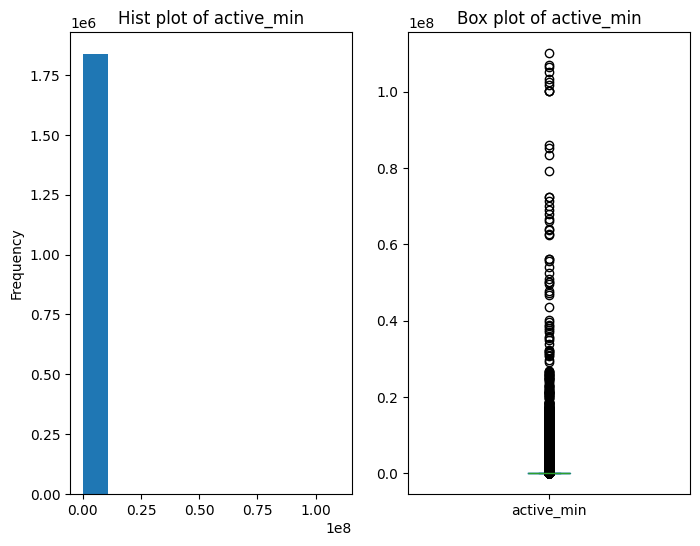

=====
central tendency of active_mean: {'mean': 90855.47339025066, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 110097488.0, 'range': 110097488.0}
=====
Dispersion of active_mean: 
 {'range': 110097488.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 508441791375.9122, 'skew': 40.202158373583295, 'kurtosis': 3920.6992777660994}
=====


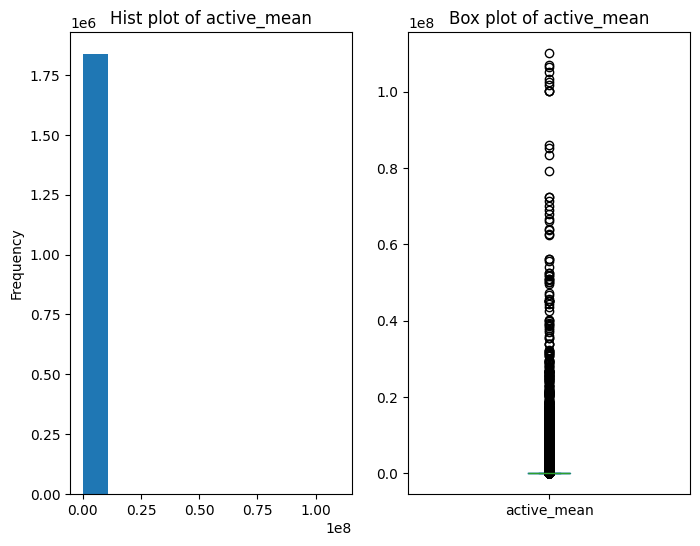

=====
central tendency of active_std: {'mean': 52481.369139203525, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 74154397.744584, 'range': 74154397.744584}
=====
Dispersion of active_std: 
 {'range': 74154397.744584, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 186819270059.87686, 'skew': 40.15785197022466, 'kurtosis': 4054.5715254486145}
=====


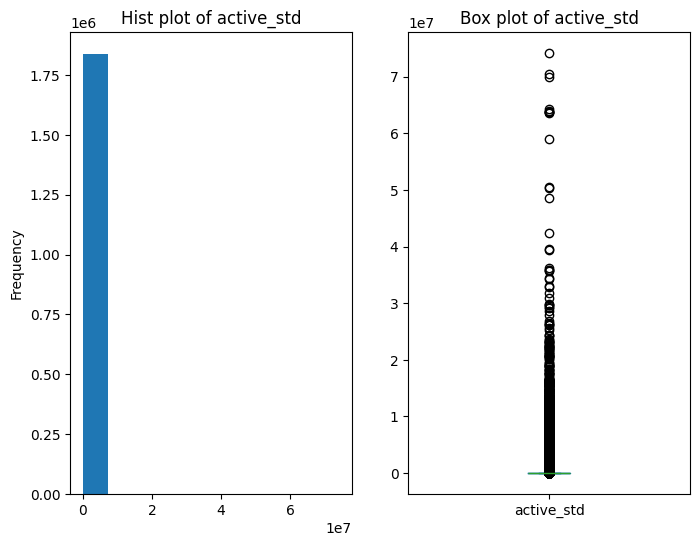

=====
central tendency of idle_max: {'mean': 4033049.586569346, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of idle_max: 
 {'range': 119999735.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 196413552298151.8, 'skew': 4.790198814512726, 'kurtosis': 25.058044506532042}
=====


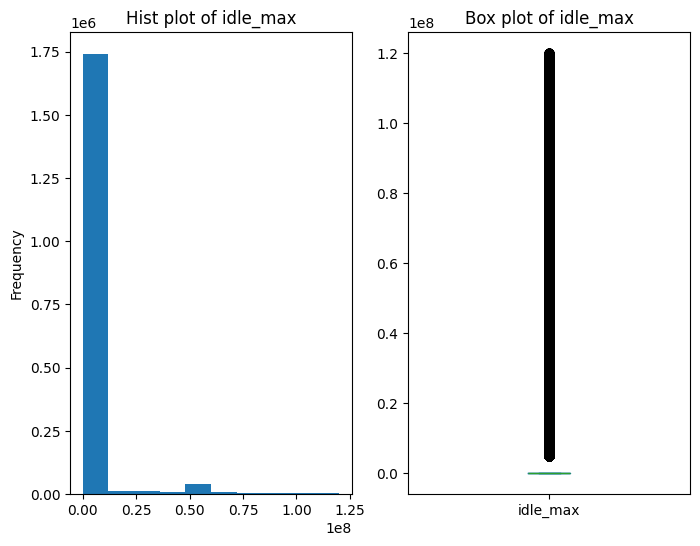

=====
central tendency of idle_min: {'mean': 3658133.306791082, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of idle_min: 
 {'range': 119999735.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 178720382462066.4, 'skew': 5.195765789635457, 'kurtosis': 29.586893500529126}
=====


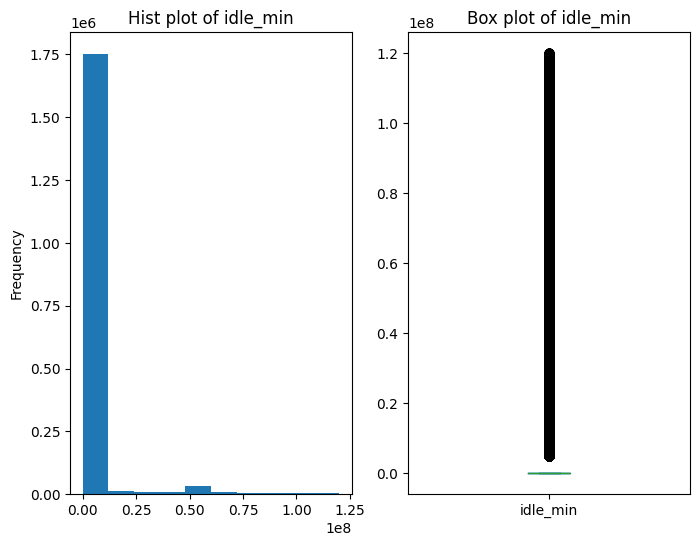

=====
central tendency of idle_mean: {'mean': 3855138.1421034485, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 119999735.0, 'range': 119999735.0}
=====
Dispersion of idle_mean: 
 {'range': 119999735.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 184098296533671.47, 'skew': 5.002860306377417, 'kurtosis': 27.660063698526507}
=====


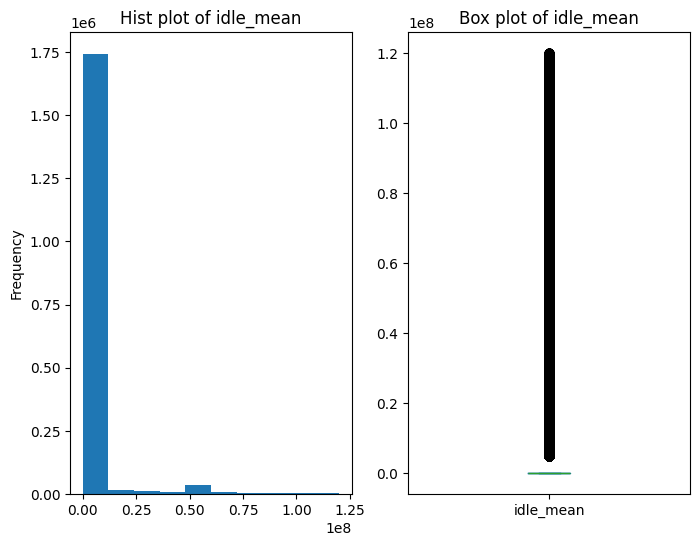

=====
central tendency of idle_std: {'mean': 204665.1016673838, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 76914831.602572, 'range': 76914831.602572}
=====
Dispersion of idle_std: 
 {'range': 76914831.602572, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 4714098662946.028, 'skew': 15.716250632272546, 'kurtosis': 301.1203483912579}
=====


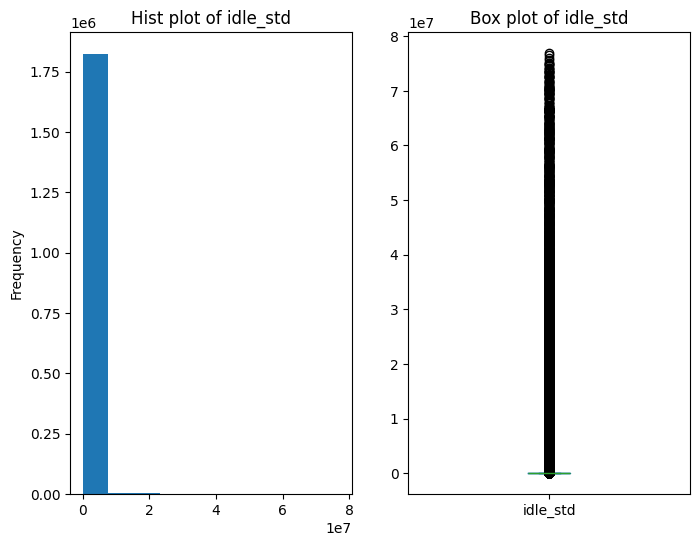

=====
central tendency of flag_SYN: {'mean': 0.9387291850113578, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 52, 'range': 52}
=====
Dispersion of flag_SYN: 
 {'range': 52, 'q1': 0.0, 'q3': 2.0, 'iqr': 2.0, 'var': 1.1222422813721624, 'skew': 0.9470519859510402, 'kurtosis': 6.906866431323574}
=====


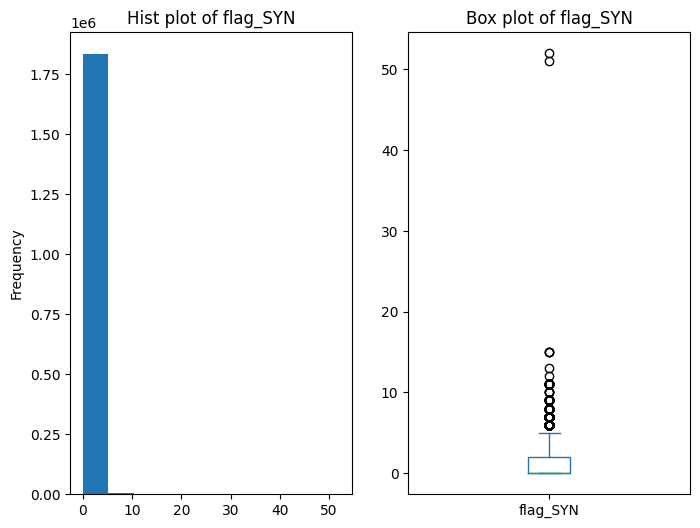

=====
central tendency of flag_fin: {'mean': 0.3834197370554961, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1, 'range': 1}
=====
Dispersion of flag_fin: 
 {'range': 1, 'q1': 0.0, 'q3': 1.0, 'iqr': 1.0, 'var': 0.2364091709499826, 'skew': 0.4795383436826683, 'kurtosis': -1.7700449035208525}
=====


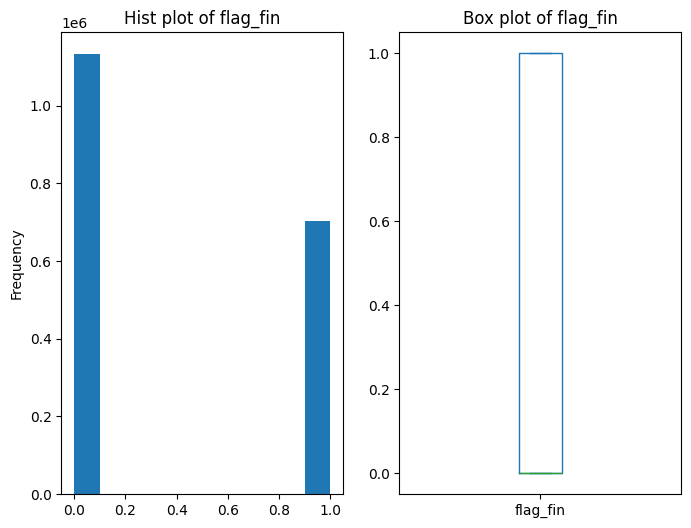

=====
central tendency of flag_rst: {'mean': 0.09971602690179798, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1, 'range': 1}
=====
Dispersion of flag_rst: 
 {'range': 1, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.08977278973671106, 'skew': 2.671937587920636, 'kurtosis': 5.139256067496157}
=====


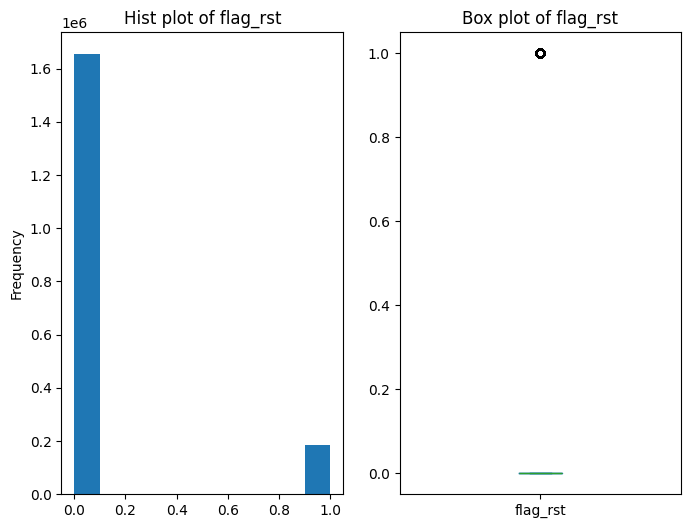

=====
central tendency of flag_ack: {'mean': 24.42313624286938, 'median': 1.0, 'mode': 0, 'min': 0, 'max': 511681, 'range': 511681}
=====
Dispersion of flag_ack: 
 {'range': 511681, 'q1': 0.0, 'q3': 8.0, 'iqr': 8.0, 'var': 4694449.139656008, 'skew': 197.29891790103028, 'kurtosis': 40247.141295553156}
=====


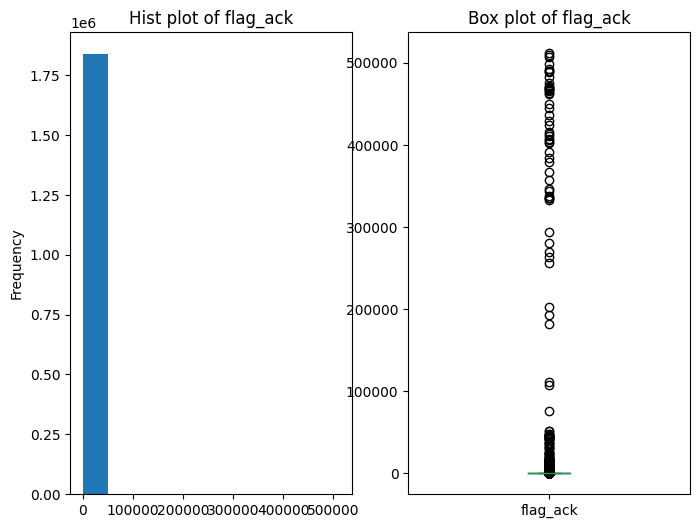

=====
central tendency of flag_psh: {'mean': 3.1683920200185254, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 9861, 'range': 9861}
=====
Dispersion of flag_psh: 
 {'range': 9861, 'q1': 0.0, 'q3': 2.0, 'iqr': 2.0, 'var': 829.8130653498575, 'skew': 167.453202484809, 'kurtosis': 38556.70552037928}
=====


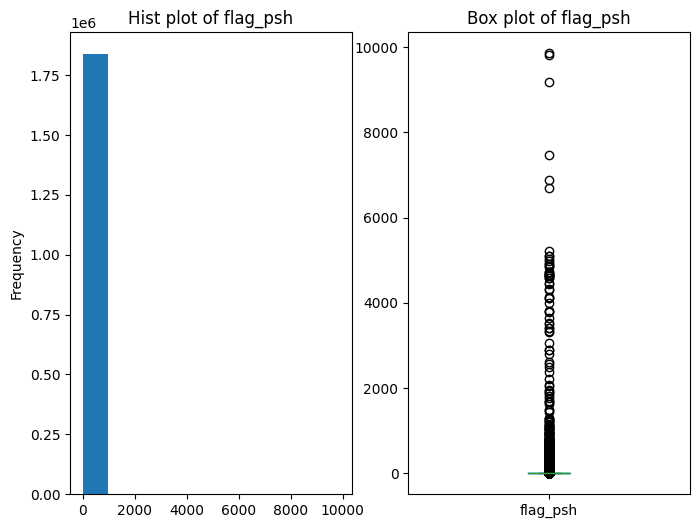

=====
central tendency of fwd_flag_psh: {'mean': 1.4157539219090307, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1589, 'range': 1589}
=====
Dispersion of fwd_flag_psh: 
 {'range': 1589, 'q1': 0.0, 'q3': 1.0, 'iqr': 1.0, 'var': 22.917827369851125, 'skew': 57.04711685041641, 'kurtosis': 10821.28454219773}
=====


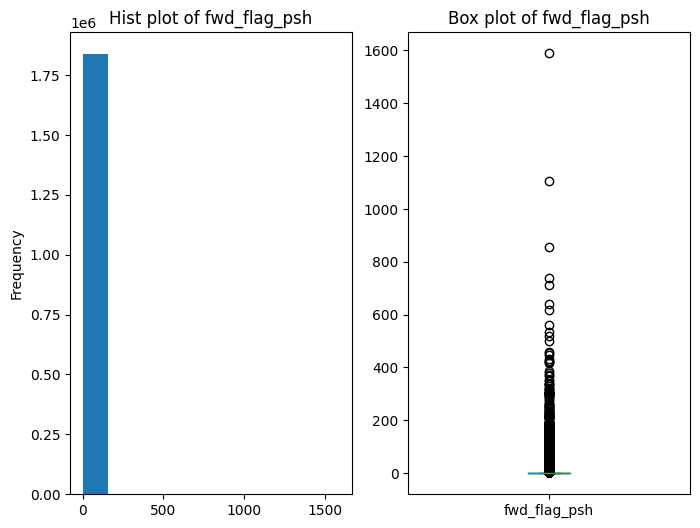

=====
central tendency of bwd_flag_psh: {'mean': 1.7526380981094944, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 9761, 'range': 9761}
=====
Dispersion of bwd_flag_psh: 
 {'range': 9761, 'q1': 0.0, 'q3': 1.0, 'iqr': 1.0, 'var': 726.2836055442918, 'skew': 192.0457283549542, 'kurtosis': 47292.35304774784}
=====


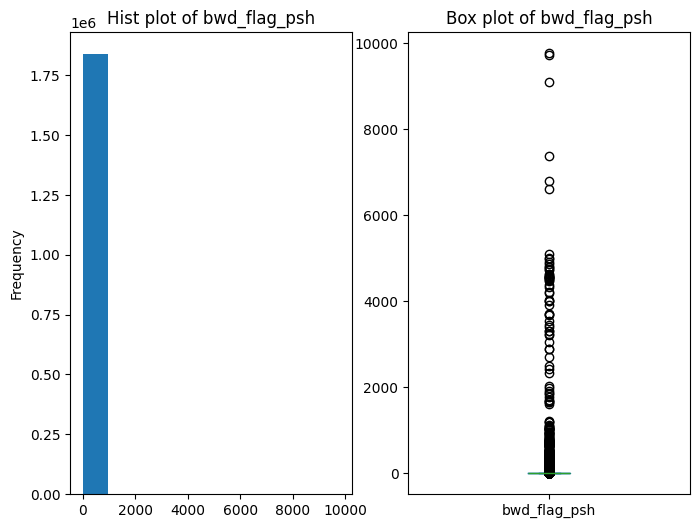

=====
central tendency of flag_urg: {'mean': 0.0, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 0, 'range': 0}
=====
Dispersion of flag_urg: 
 {'range': 0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0, 'skew': 0.0, 'kurtosis': 0.0}
=====


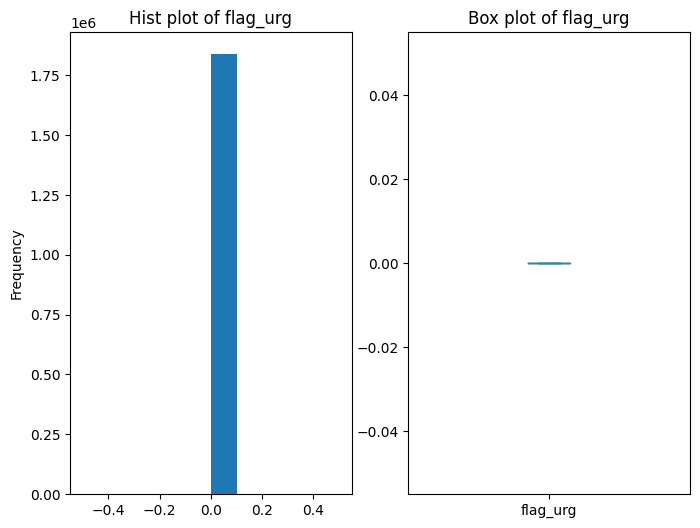

=====
central tendency of fwd_flag_urg: {'mean': 0.0, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 0, 'range': 0}
=====
Dispersion of fwd_flag_urg: 
 {'range': 0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0, 'skew': 0.0, 'kurtosis': 0.0}
=====


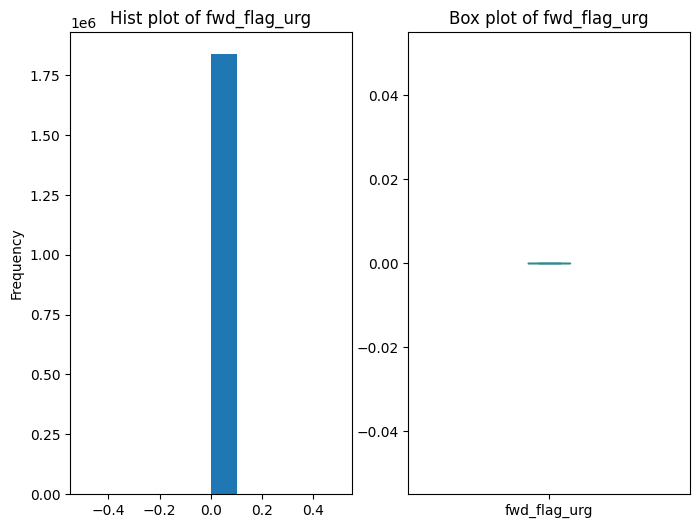

=====
central tendency of bwd_flag_urg: {'mean': 0.0, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 0, 'range': 0}
=====
Dispersion of bwd_flag_urg: 
 {'range': 0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0, 'skew': 0.0, 'kurtosis': 0.0}
=====


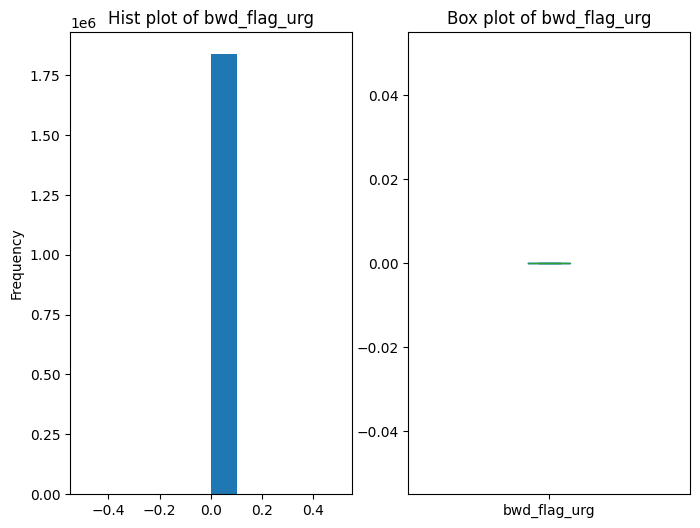

=====
central tendency of flag_cwr: {'mean': 0.00040870792784536365, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 23, 'range': 23}
=====
Dispersion of flag_cwr: 
 {'range': 23, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0008341200341258751, 'skew': 336.2663139268284, 'kurtosis': 230693.25691526328}
=====


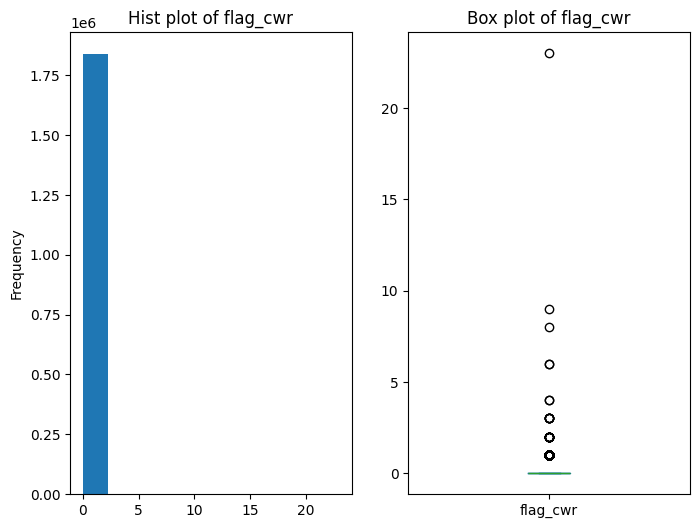

=====
central tendency of flag_ece: {'mean': 0.0006057149449958585, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 2, 'range': 2}
=====
Dispersion of flag_ece: 
 {'range': 2, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.0011658935167057254, 'skew': 57.404033708509154, 'kurtosis': 3325.1696505591226}
=====


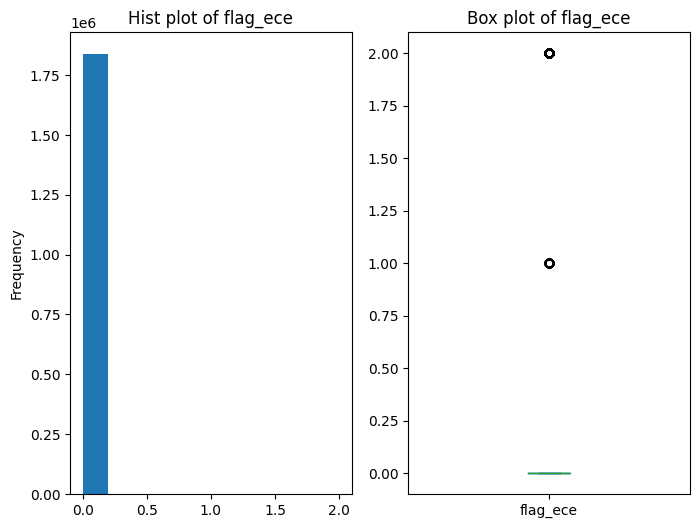

=====
central tendency of fwd_bulk_bytes_mean: {'mean': 67.7536686902544, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 351373.0, 'range': 351373.0}
=====
Dispersion of fwd_bulk_bytes_mean: 
 {'range': 351373.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 1971303.8134196044, 'skew': 93.29873147373445, 'kurtosis': 16138.658510614734}
=====


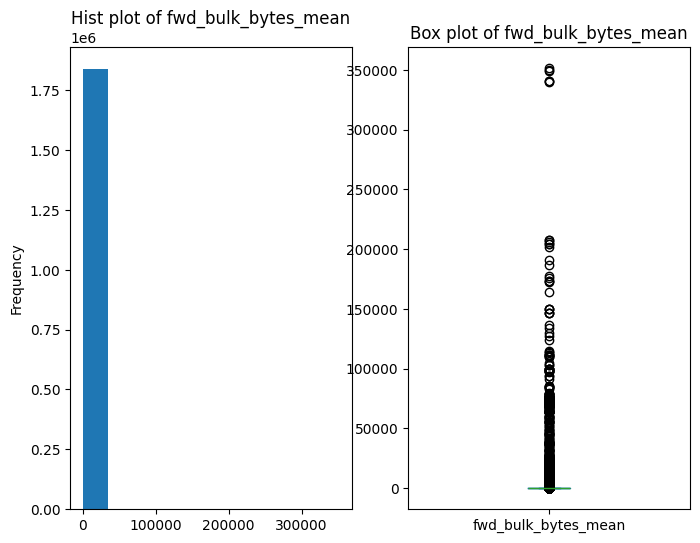

=====
central tendency of fwd_bulk_pkt_mean: {'mean': 0.2369939670715287, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 360.0, 'range': 360.0}
=====
Dispersion of fwd_bulk_pkt_mean: 
 {'range': 360.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 2.698927282083065, 'skew': 36.195316481313476, 'kurtosis': 4370.456263331852}
=====


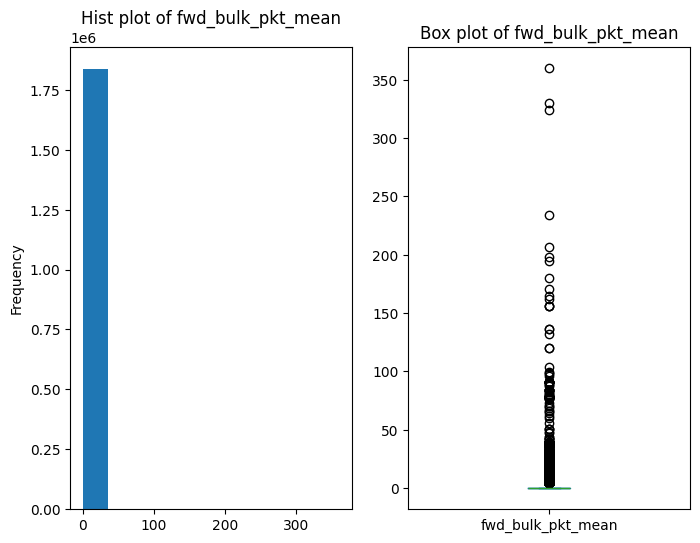

=====
central tendency of fwd_bulk_rate_mean: {'mean': 182195.14421378967, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 974000000.0, 'range': 974000000.0}
=====
Dispersion of fwd_bulk_rate_mean: 
 {'range': 974000000.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 17057822188820.076, 'skew': 51.92490439337114, 'kurtosis': 5952.015713026731}
=====


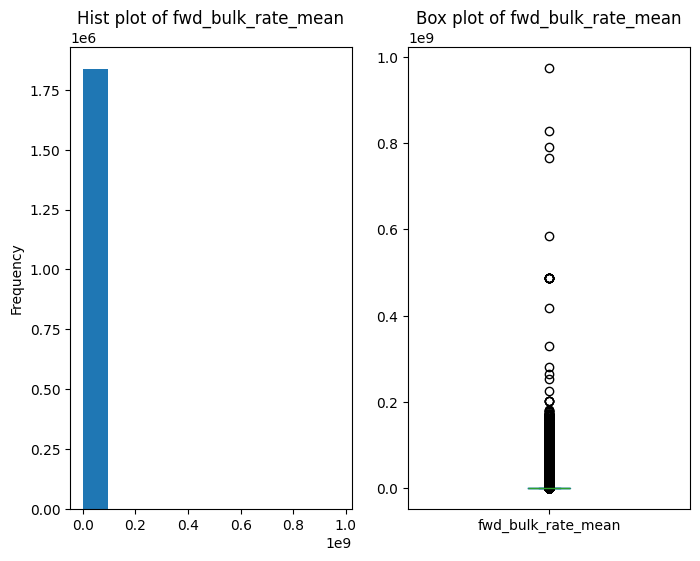

=====
central tendency of bwd_bulk_bytes_mean: {'mean': 4215.857202688916, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 156761876.25, 'range': 156761876.25}
=====
Dispersion of bwd_bulk_bytes_mean: 
 {'range': 156761876.25, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 101392215136.60713, 'skew': 400.7541587568549, 'kurtosis': 180437.8061248833}
=====


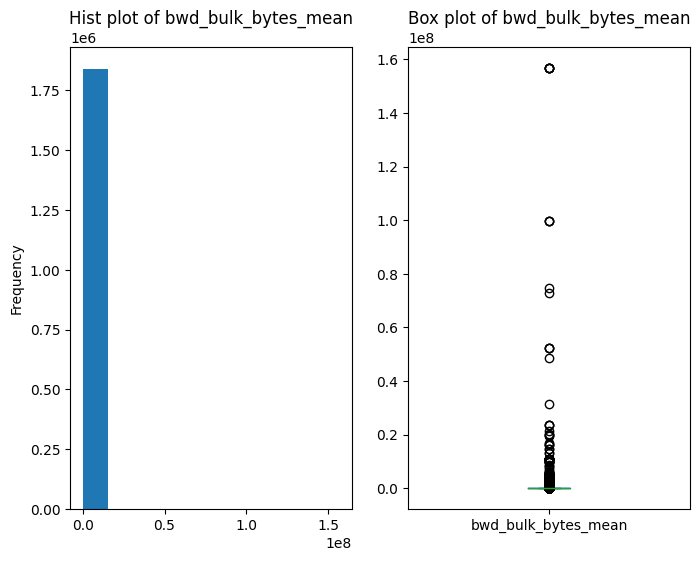

=====
central tendency of bwd_bulk_pkt_mean: {'mean': 2.0933050419782773, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 58270.75, 'range': 58270.75}
=====
Dispersion of bwd_bulk_pkt_mean: 
 {'range': 58270.75, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 12781.165915544985, 'skew': 376.1229499029029, 'kurtosis': 164113.31591496267}
=====


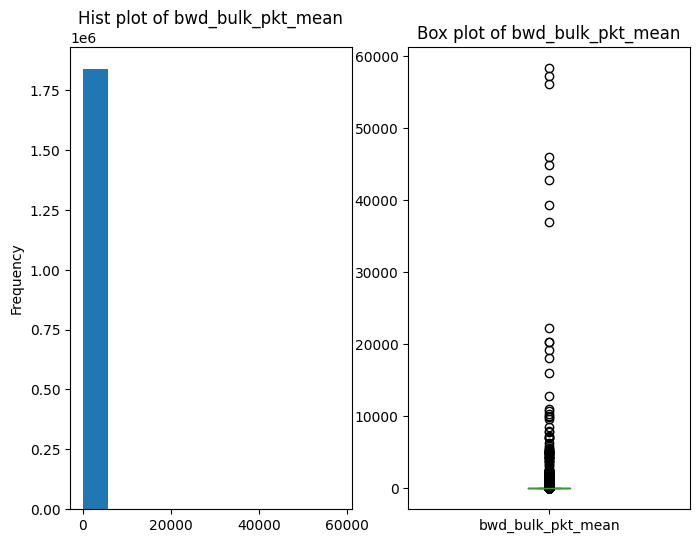

=====
central tendency of bwd_bulk_rate_mean: {'mean': 2855677.4026941564, 'median': 0.0, 'mode': 0.0, 'min': 0.0, 'max': 1369000000.0, 'range': 1369000000.0}
=====
Dispersion of bwd_bulk_rate_mean: 
 {'range': 1369000000.0, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 106853084398559.45, 'skew': 11.927733798005896, 'kurtosis': 702.5766537728558}
=====


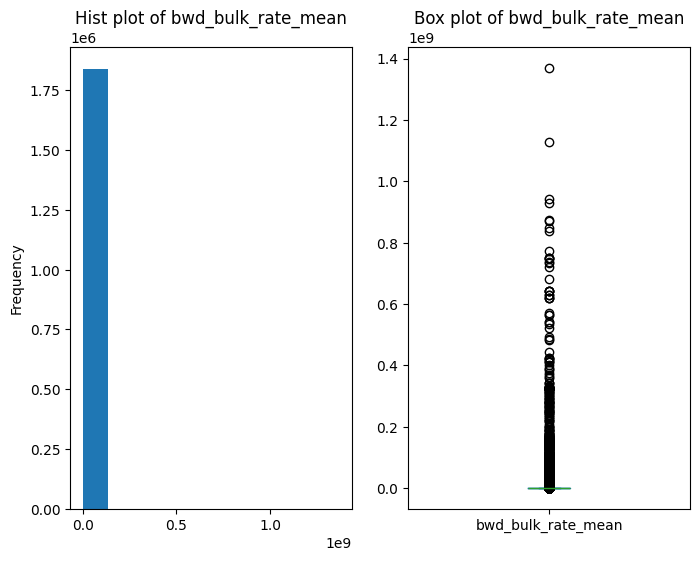

=====
central tendency of fwd_subflow_bytes_mean: {'mean': 268.14844081993175, 'median': 74.0, 'mode': 0.0, 'min': 0.0, 'max': 1783979.0, 'range': 1783979.0}
=====
Dispersion of fwd_subflow_bytes_mean: 
 {'range': 1783979.0, 'q1': 48.0, 'q3': 202.0, 'iqr': 154.0, 'var': 6017734.336430733, 'skew': 419.3760588059683, 'kurtosis': 263456.99759191566}
=====


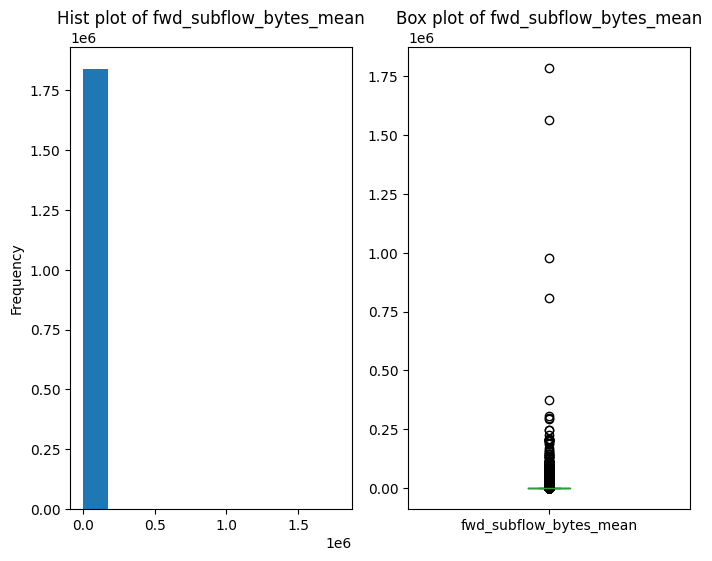

=====
central tendency of fwd_subflow_pkt_mean: {'mean': 6.813950739654139, 'median': 2.0, 'mode': 2.0, 'min': 0.0, 'max': 219759.0, 'range': 219759.0}
=====
Dispersion of fwd_subflow_pkt_mean: 
 {'range': 219759.0, 'q1': 1.0, 'q3': 3.0, 'iqr': 2.0, 'var': 522145.01377331495, 'skew': 257.69445181587054, 'kurtosis': 70222.03745469746}
=====


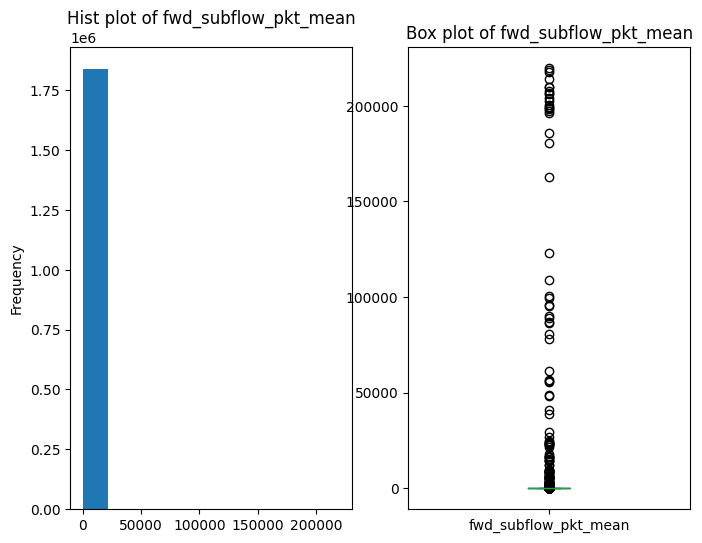

=====
central tendency of bwd_subflow_bytes_mean: {'mean': 13959.962720128824, 'median': 206.0, 'mode': 0.0, 'min': 0.0, 'max': 655452323.0, 'range': 655452323.0}
=====
Dispersion of bwd_subflow_bytes_mean: 
 {'range': 655452323.0, 'q1': 98.0, 'q3': 1762.5, 'iqr': 1664.5, 'var': 4627389610332.941, 'skew': 253.34306942536818, 'kurtosis': 67813.2492445578}
=====


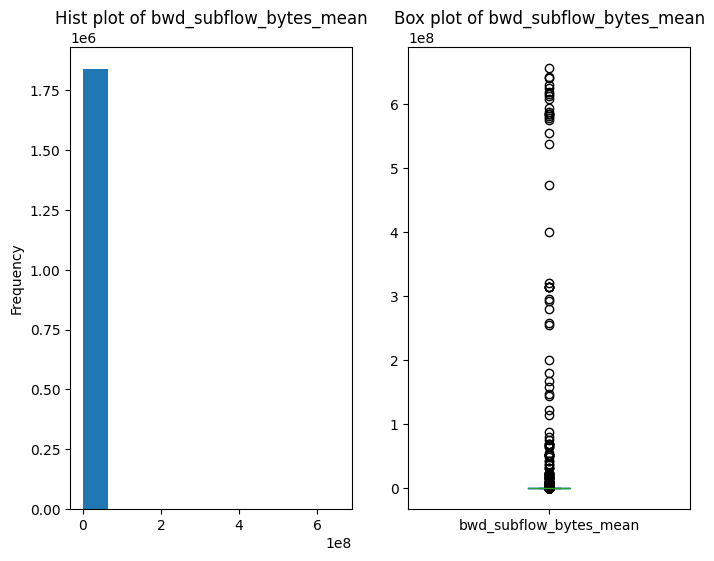

=====
central tendency of bwd_subflow_pkt_mean: {'mean': 8.270970366132099, 'median': 2.0, 'mode': 2.0, 'min': 0.0, 'max': 291922.0, 'range': 291922.0}
=====
Dispersion of bwd_subflow_pkt_mean: 
 {'range': 291922.0, 'q1': 1.0, 'q3': 3.5, 'iqr': 2.5, 'var': 935935.8401020962, 'skew': 258.941660484433, 'kurtosis': 70789.80365777202}
=====


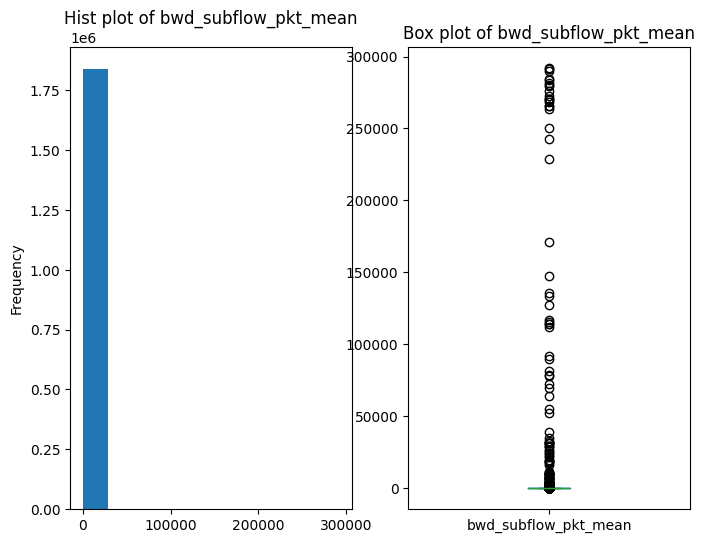

=====
central tendency of fwd_tcp_init_win_bytes: {'mean': 10695.108767465324, 'median': 364.0, 'mode': -1, 'min': -1, 'max': 65535, 'range': 65536}
=====
Dispersion of fwd_tcp_init_win_bytes: 
 {'range': 65536, 'q1': -1.0, 'q3': 29200.0, 'iqr': 29201.0, 'var': 245943014.2544253, 'skew': 1.6644854267014937, 'kurtosis': 2.621052849816807}
=====


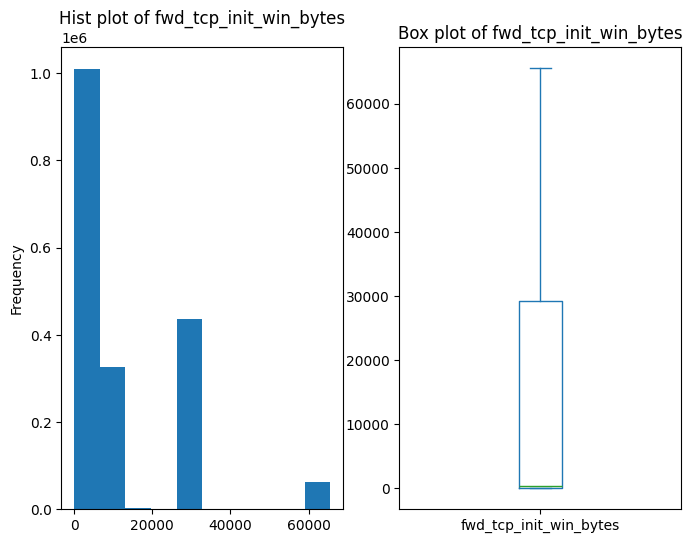

=====
central tendency of bwd_tcp_init_win_bytes: {'mean': 11462.36497509113, 'median': 0.0, 'mode': -1, 'min': -1, 'max': 65535, 'range': 65536}
=====
Dispersion of bwd_tcp_init_win_bytes: 
 {'range': 65536, 'q1': -1.0, 'q3': 28960.0, 'iqr': 28961.0, 'var': 241798244.31923515, 'skew': 1.0011387027953618, 'kurtosis': 0.07666360735557998}
=====


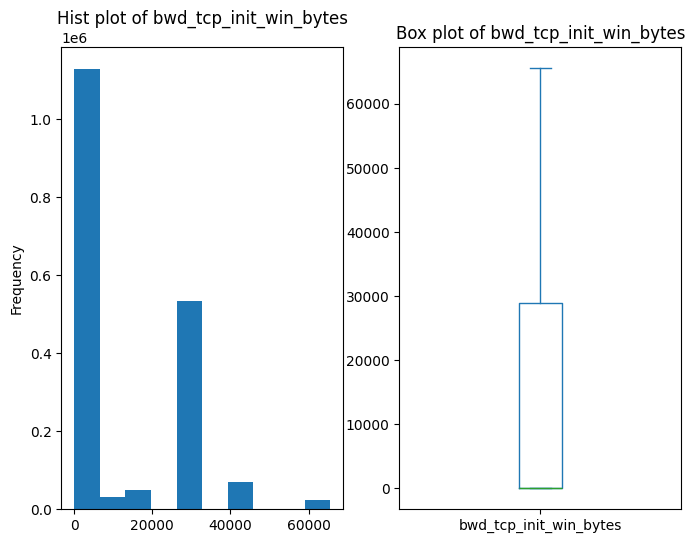

=====
central tendency of is_attack: {'mean': 0.24044815286873783, 'median': 0.0, 'mode': 0, 'min': 0, 'max': 1, 'range': 1}
=====
Dispersion of is_attack: 
 {'range': 1, 'q1': 0.0, 'q3': 0.0, 'iqr': 0.0, 'var': 0.18263293804293285, 'skew': 1.2146888344778637, 'kurtosis': -0.5245316063153727}
=====


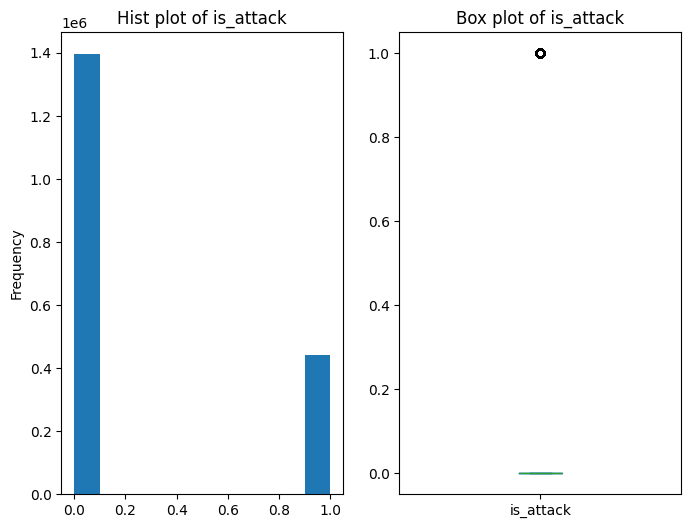

In [21]:
# Phân tích chi tiết từng biến numeric
_analyzer = Analyzer()
for col in numeric_cols:
    _analyzer.analyze_numeric_variable(variable_name=col, df=df_raw)
    print('=' * 50)

## Features - categorical

In [22]:
# Thực hiện thống kê mô tả - dữ liệu categorical
df_raw.select_dtypes(include=['object', 'string']).describe()

,flow_id,src_addr,dst_addr,label,source_day
count,1837498,1837498,1837498,1837498,1837498
unique,942759,268,18095,14,5
top,192.168.10.3-192.168.10.255-137-137-17,172.16.0.1,192.168.10.3,benign,Friday
freq,451,442471,602976,1395675,542962


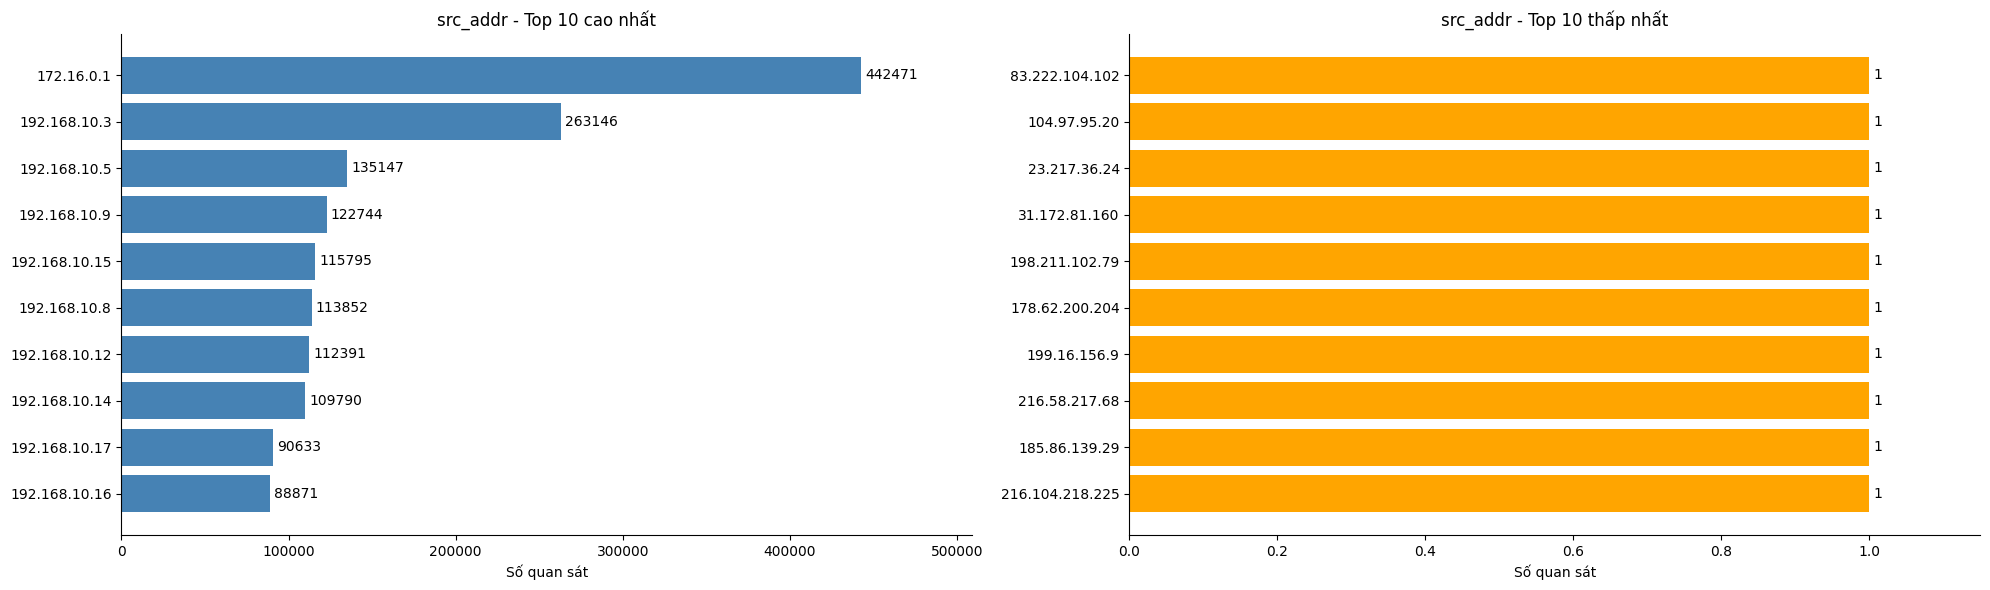

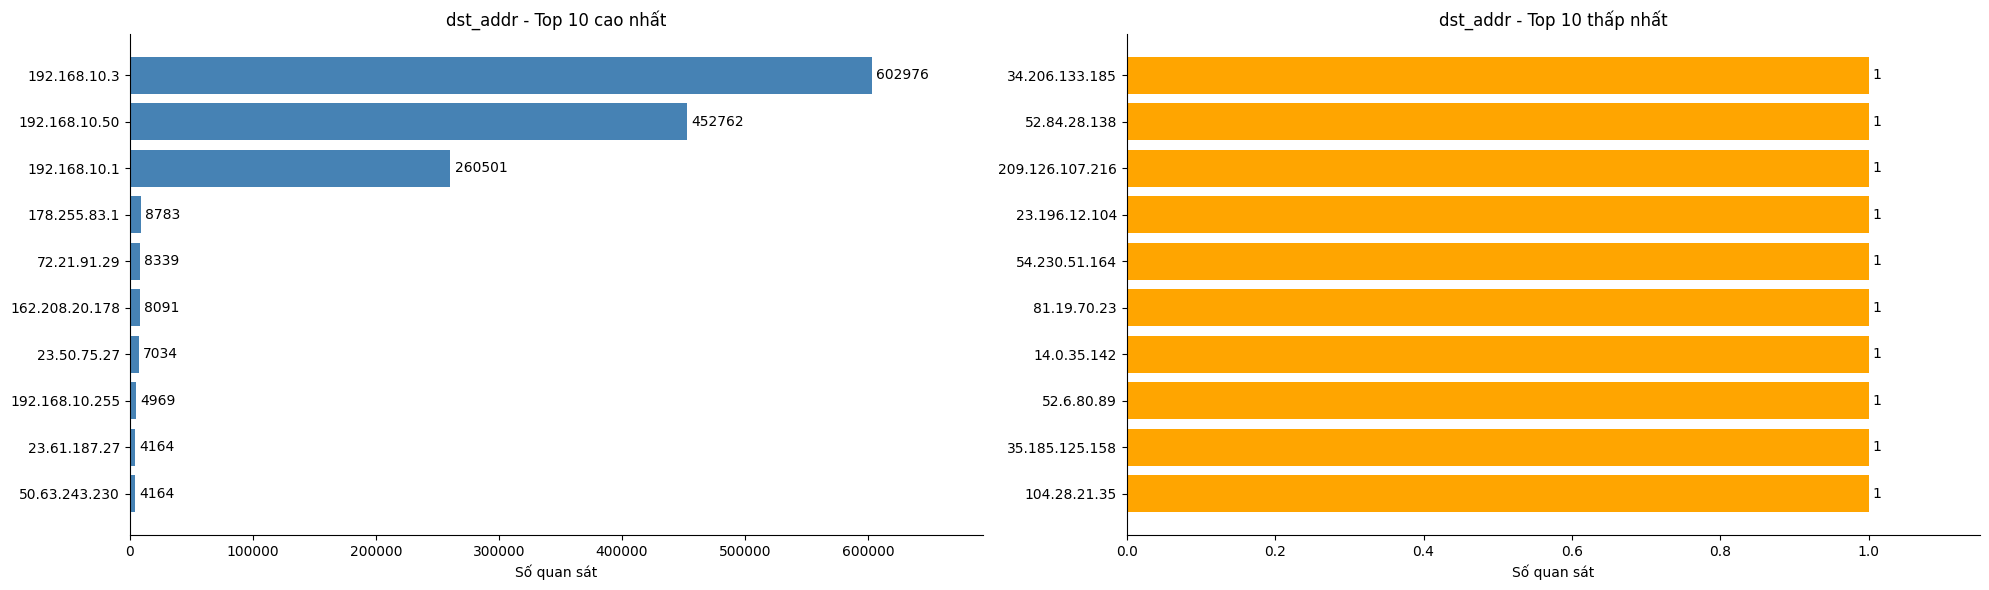

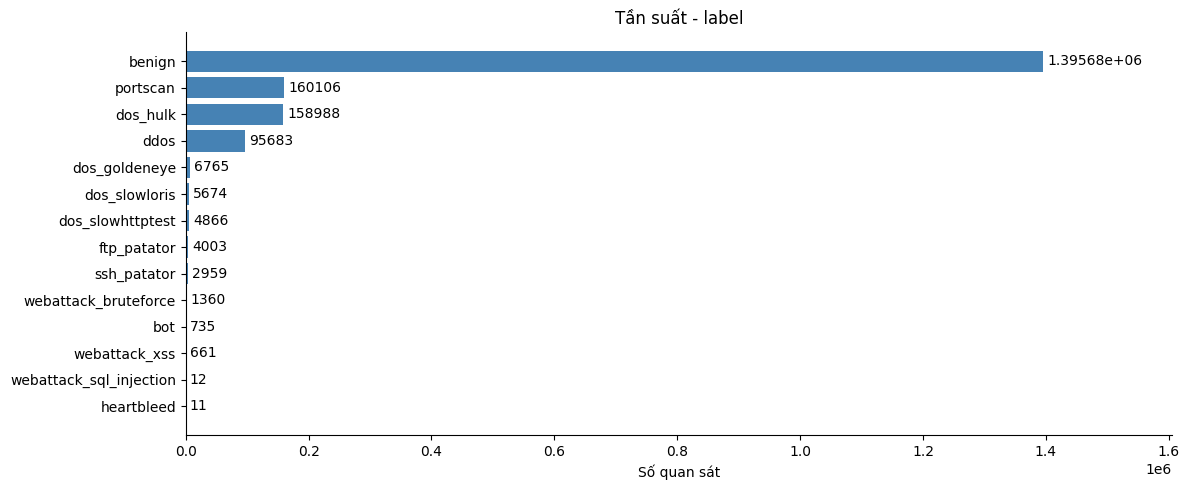

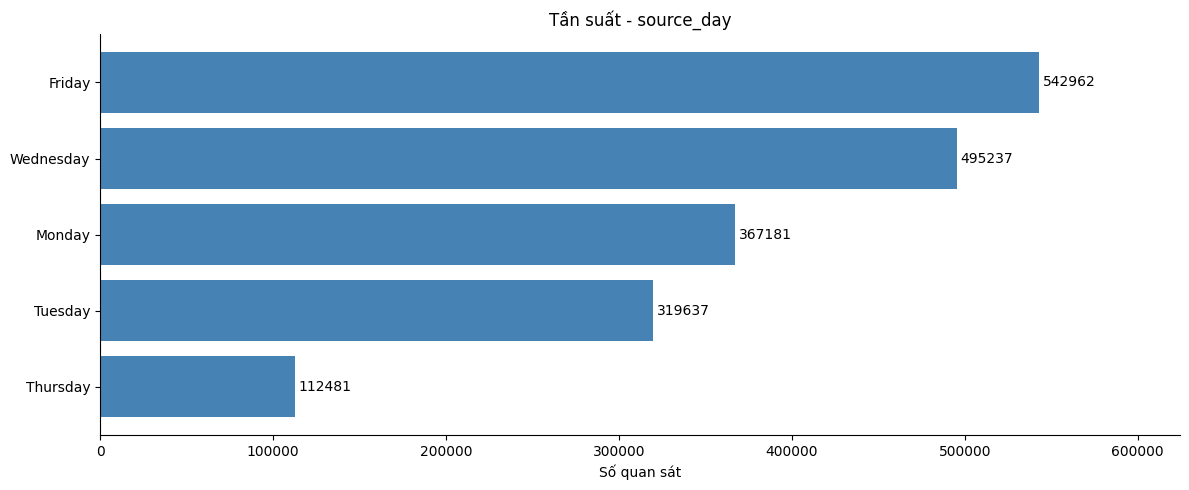

In [23]:
# Tần suất các biến phân loại có ý nghĩa; bỏ qua mã định danh duy nhất
for col in category_cols:
    counts = df_raw[col].value_counts(dropna=False)

    if counts.size > 20:
        fig, axes = plt.subplots(1, 2, figsize=(20, 6))
        top_high = counts.nlargest(10).sort_values()
        top_low = counts.nsmallest(10).sort_values(ascending=False)

        axes[0].barh(top_high.index.astype(str), top_high.values, color='steelblue')
        axes[0].bar_label(axes[0].containers[0], padding=3)
        axes[0].set_title(f'{col} - Top 10 cao nhất')

        axes[1].barh(top_low.index.astype(str), top_low.values, color='orange')
        axes[1].bar_label(axes[1].containers[0], padding=3)
        axes[1].set_title(f'{col} - Top 10 thấp nhất')
    else:
        fig, ax = plt.subplots(figsize=(12, 5))
        counts = counts.sort_values()
        ax.barh(counts.index.astype(str), counts.values, color='steelblue')
        ax.bar_label(ax.containers[0], padding=3)
        ax.set_title(f'Tần suất - {col}')
        axes = [ax]

    for ax in axes:
        ax.set_xlabel('Số quan sát')
        ax.spines[['top', 'right']].set_visible(False)
        ax.margins(x=0.15)
    plt.tight_layout()
    plt.show()

## Correlation of 1 feature & target

In [24]:
def analyze_category_vs_continous(category_var,continous_var, df):
    lst = []
    for name, g in df.groupby(category_var):
        lst.append(g[continous_var])
    f_statistic, p_value = f_oneway(*lst)
    return f_statistic, p_value

### Target & numeric feature

In [25]:
# target = ['label']
target = ['is_attack']


n = len(numeric_cols)
m = len(target)

for j in range(m):
    indepen = []
    dep = []
    for i in range(n):

        f_statistic, p_value = analyze_category_vs_continous(target[j],numeric_cols[i],df_raw)
        alpha = 0.05
        if p_value < alpha:
            dep.append(numeric_cols[i])
        else:
            indepen.append(numeric_cols[i])
    print()
    print(f'Các biến có tác động đến {target}: {dep}')
    print(f'Các biến không có tác động đến {target}: {indepen}')



Các biến có tác động đến ['is_attack']: ['src_port', 'dst_port', 'ip_prot', 'timestamp', 'flow_duration', 'down_up_ratio', 'pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std', 'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot', 'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt', 'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean', 'idle_std', 'flag_SYN', 'flag_fin', 'flag_rst', 'flag_ack', 'flag_psh', 'fwd_flag_p

### Target & categorical feature

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of is_attack and src_addr=====
Reject H0 - Dependent


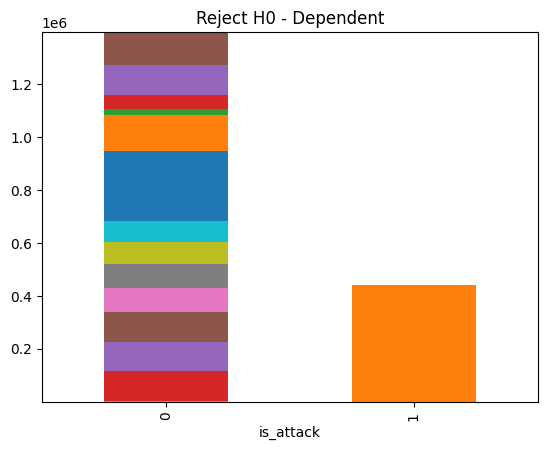

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of is_attack and dst_addr=====
Reject H0 - Dependent


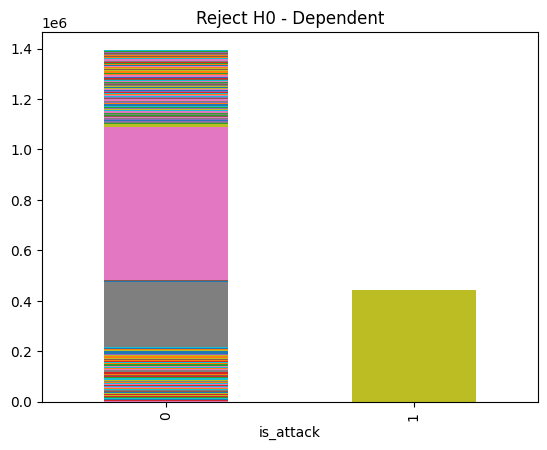

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of is_attack and label=====
Reject H0 - Dependent


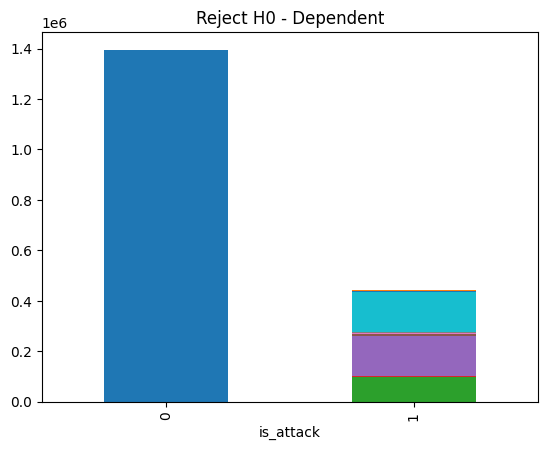

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 
=====Analyze of is_attack and source_day=====
Reject H0 - Dependent


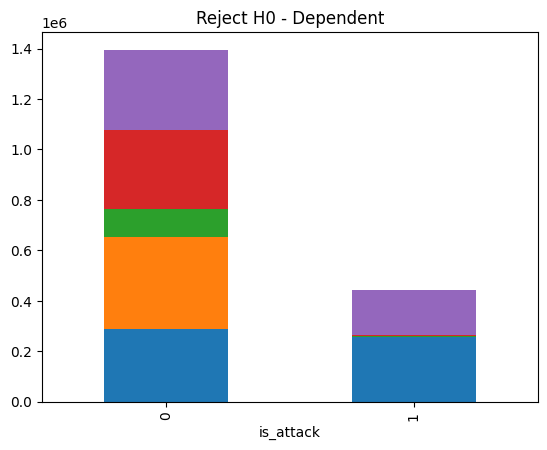

In [26]:
target_col = target[0]

for col in category_cols:
    if col == target_col:
        continue

    print('* ' * 40)
    _analyzer.analyze_category_vs_category(
        var1=target_col,
        var2=col,
        df=df_raw
    )

## Correlation of 2 features

In [27]:
def analyze_continous_vs_continous(var_1, var_2, df):
    # Calculate Pearson correlation coefficient
    correlation_coefficient, p_value = stats.pearsonr(df[var_1], df[var_2])
    print('var 1=',var_1,',','var 2=',var_2)
    print(f"Pearson Correlation Coefficient: {correlation_coefficient:.2f} - P-value: {p_value:.4f}")
    sns.scatterplot(data=df, x=var_1, y=var_2)
    plt.show()

### Numeric & numeric

In [28]:
# n = len(numeric_cols)
# for i in range(n):
#     for j in range(i + 1, n):
#         print('* ' * 40)
#         analyze_continous_vs_continous(var_1=numeric_cols[i], var_2=numeric_cols[j], df=df_raw)

### Numeric & Categorical

In [29]:
# n = len(numeric_cols)
# m = len(category_cols)

# for j in range(m):
#     indepen = []
#     dep = []
#     for i in range(n):

#         f_statistic, p_value = analyze_category_vs_continous(category_cols[j],numeric_cols[i],df_raw)
#         alpha = 0.05
#         if p_value < alpha:
#             dep.append(numeric_cols[i])
#         else:
#             indepen.append(numeric_cols[i])
#     print()
#     print(f'Các biến có tác động đến {category_cols[j]}: {dep}')
#     print(f'Các biến không có tác động đến {category_cols[j]}: {indepen}')


### Categorical & Categorical

In [30]:
# n = len(category_cols)
# for i in range(n):
#     for j in range(i + 1, n):
#         print('* ' * 40)
#         _analyzer.analyze_category_vs_category(
#             var1=category_cols[i],
#             var2=category_cols[j],
#             df=df_raw
#         )

In [31]:
import pandas as pd
import numpy as np

df = df_raw.copy()

# Thay bằng tên cột mục tiêu thực tế
target = "target"

# Thống kê dữ liệu ban đầu
stats_before = {
    "Số dòng dữ liệu": len(df),
    "Số thuộc tính": df.shape[1] - 1,
    "Số giá trị thiếu": df.isna().sum().sum(),
    "Số dòng trùng lặp": df.duplicated().sum()
}

pd.DataFrame(
    stats_before.items(),
    columns=["Chỉ tiêu", "Trước xử lý"]
)

,Chỉ tiêu,Trước xử lý
0,Số dòng dữ liệu,1837498
1,Số thuộc tính,84
2,Số giá trị thiếu,0
3,Số dòng trùng lặp,0


In [32]:
quality = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số giá trị thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": df.isna().mean() * 100,
    "Số giá trị phân biệt": df.nunique()
})

display(
    quality.sort_values(
        "Tỷ lệ thiếu (%)",
        ascending=False
    )
)

,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số giá trị phân biệt
flow_id,object,0,0.0,942759
idle_max,float64,0,0.0,206246
flag_psh,int64,0,0.0,607
flag_ack,int64,0,0.0,2152
flag_rst,int64,0,0.0,2
...,...,...,...,...
bwd_pkt_cnt,int64,0,0.0,1644
fwd_non_empty_pkt_cnt,int64,0,0.0,309
fwd_pkt_hdr_len_min,int64,0,0.0,9
fwd_pkt_hdr_len_tot,int64,0,0.0,3435


# Preprocess

### Loại trùng & thiếu

In [33]:
df_clean = df.copy()

# 1. Loại bỏ dòng trùng lặp hoàn toàn
df_clean = df_clean.drop_duplicates()

# 2. Loại bỏ dòng thiếu biến mục tiêu
df_clean = df_clean.dropna(subset=['is_attack'])

# 3. Xem số dòng còn lại
print("Trước:", len(df))
print("Sau:", len(df_clean))
print("Đã loại:", len(df) - len(df_clean))

Trước: 1837498
Sau: 1837498
Đã loại: 0


## Đổi kiểu dữ liệu

In [34]:
df_clean.columns

Index(['flow_id', 'src_addr', 'src_port', 'dst_addr', 'dst_port', 'ip_prot',
       'timestamp', 'flow_duration', 'down_up_ratio', 'pkt_len_max',
       'pkt_len_min', 'pkt_len_mean', 'pkt_len_var', 'pkt_len_std',
       'bytes_per_s', 'pkt_per_s', 'fwd_pkt_per_s', 'bwd_pkt_per_s',
       'fwd_pkt_cnt', 'fwd_pkt_len_tot', 'fwd_pkt_len_max', 'fwd_pkt_len_min',
       'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'fwd_pkt_hdr_len_tot',
       'fwd_pkt_hdr_len_min', 'fwd_non_empty_pkt_cnt', 'bwd_pkt_cnt',
       'bwd_pkt_len_tot', 'bwd_pkt_len_max', 'bwd_pkt_len_min',
       'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot',
       'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min',
       'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min',
       'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max',
       'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max',
       'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min',
     

In [35]:
# ip_prot là mã giao thức, nên xem là biến phân loại.
df_clean['ip_prot'] = df_clean['ip_prot'].astype('str')

df_clean

,flow_id,src_addr,src_port,dst_addr,dst_port,ip_prot,timestamp,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,pkt_per_s,fwd_pkt_per_s,bwd_pkt_per_s,fwd_pkt_cnt,fwd_pkt_len_tot,fwd_pkt_len_max,fwd_pkt_len_min,fwd_pkt_len_mean,fwd_pkt_len_std,fwd_pkt_hdr_len_tot,fwd_pkt_hdr_len_min,fwd_non_empty_pkt_cnt,bwd_pkt_cnt,bwd_pkt_len_tot,bwd_pkt_len_max,bwd_pkt_len_min,bwd_pkt_len_mean,bwd_pkt_len_std,bwd_pkt_hdr_len_tot,bwd_pkt_hdr_len_min,bwd_non_empty_pkt_cnt,iat_max,iat_min,iat_mean,iat_std,fwd_iat_tot,fwd_iat_max,fwd_iat_min,fwd_iat_mean,fwd_iat_std,bwd_iat_tot,bwd_iat_max,bwd_iat_min,bwd_iat_mean,bwd_iat_std,active_max,active_min,active_mean,active_std,idle_max,idle_min,idle_mean,idle_std,flag_SYN,flag_fin,flag_rst,flag_ack,flag_psh,fwd_flag_psh,bwd_flag_psh,flag_urg,fwd_flag_urg,bwd_flag_urg,flag_cwr,flag_ece,fwd_bulk_bytes_mean,fwd_bulk_pkt_mean,fwd_bulk_rate_mean,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label,source_day,is_attack
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.3,3268,192.168.10.50,56108,6,1499428790315195,112740690,2.000,403.0,0.0,158.333333,31450.099291,177.341758,6.741133e+01,0.425756,0.141919,0.283837,16,1152,72.0,0.0,72.000,0.000000,512,32,16,32,6448,403.0,0.0,201.5,204.724205,1024,32,16,16399772.0,3.0,2.398738e+06,5.798698e+06,112740348,16400110.0,3.0,7.516023e+06,8.323385e+06,112740690,16399772.0,3.0,3.636796e+06,6.848761e+06,380.0,343.0,3.594286e+02,1.199802e+01,16399772.0,15375229.0,1.610540e+07,4.988048e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,144.000000,2.000000,806.000000,4.000000,2078,377,benign,Friday,0
1,192.168.10.50-192.168.10.3-42144-389-6,192.168.10.50,42144,192.168.10.3,389,6,1499428790316273,112740560,0.500,403.0,0.0,239.666667,30619.460993,174.984174,1.020396e+02,0.425756,0.283838,0.141919,32,6448,403.0,0.0,201.500,204.724205,1024,32,16,16,5056,316.0,0.0,316.0,0.000000,512,32,16,16399782.0,2.0,2.398735e+06,5.798710e+06,112740560,16399782.0,2.0,3.636792e+06,6.848777e+06,112740242,16400110.0,4.0,7.516016e+06,8.323376e+06,330.0,285.0,3.202857e+02,1.574499e+01,16399782.0,15375263.0,1.610543e+07,4.987937e+05,0,0,0,48,32,16,16,0,0,0,0,0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,806.000000,4.000000,632.000000,2.000000,955,2078,benign,Friday,0
2,192.168.10.9-224.0.0.22-0-0-2,192.168.10.9,0,224.0.0.22,0,2,1499428834843793,54760,0.000,8.0,8.0,8.000000,0.000000,0.000000,5.843682e+02,73.046019,73.046019,0.000000,4,32,8.0,8.0,8.000,0.000000,32,8,4,0,0,0.0,0.0,0.0,0.000000,0,0,0,53431.0,108.0,1.825333e+04,3.046984e+04,54760,53431.0,108.0,1.825333e+04,3.046984e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,32.0,4.0,5.843682e+02,0.0,0.0,0.0,32.000000,4.000000,0.000000,0.000000,-1,-1,benign,Friday,0
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,1499428834845380,100126,0.000,28.0,28.0,28.000000,0.000000,0.000000,6.152248e+03,219.723149,219.723149,0.000000,22,616,28.0,28.0,28.000,0.000000,176,8,22,0,0,0.0,0.0,0.0,0.000000,0,0,0,100055.0,1.0,4.767905e+03,2.183302e+04,100126,100055.0,1.0,4.767905e+03,2.183302e+04,0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0,0,0,0,0,0,0,0,0,0,0,0,616.0,22.0,6.152248e+03,0.0,0.0,0.0,616.000000,22.000000,0.000000,0.000000,-1,-1,benign,Friday,0
4,192.168.10.9-192.168.10.3-137-137-17,192.168.10.9,137,192.168.10.3,137,17,1499428835164943,93069427,1.000,68.0,50.0,59.000000,46.153846,6.793662,2.535741e+01,0.429787,0.214893,0.214893,20,1180,68.0,50.0,59.000,9.233805,160,8,20,20,1180,62.0,0.0,59.0,3.077935,160,8,20,50763066.0,3.0,2.386396e+06,9.205496e+06,93069292,50763154.0,3.0,4.898384e+06,1.288064e+07,93069201,50763201.0,3.0,4.898379e+06,1.288065e+07,11894792.0,1512212.0,6.703502e+06,7.3

## Phân hạng features

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

# Điền các cột định danh cần loại, nếu có
id_cols = ["flow_id", "src_addr", "dst_addr", "timestamp", "label"]
# cột id là duy nhất nên loại, label loại vì nó chứa nhãn
# loại "src_addr", "dst_addr" vì lỡ mô hình nhớ IP thì khó tổng quát khi gặp mạng mới
# timestamp không dùng trực tiếp vì trực tiếp dễ học lịch thu thập hoặc thời điểm diễn ra tấn công.
# ip_prot là mã giao thức, nên xem là biến phân loại.

print("Các cột loại thủ công:", id_cols)


target_col = 'is_attack'

# Loại thuộc tính thiếu >= 50% (ngưỡng minh họa)
feature_cols = df_clean.columns.drop(target_col)
missing_rate = df_clean[feature_cols].isna().mean()
drop_missing = missing_rate[missing_rate >= 0.5].index.tolist()
print("Các cột bị loại do thiếu >=50%:", drop_missing)

# Loại thuộc tính chỉ có 1 giá trị phân biệt hoặc ít hơn
drop_constant = [
    c for c in feature_cols
    if df_clean[c].nunique(dropna=True) <= 1
]
print("Các cột bị loại do thuộc tính chỉ có 1 giá trị:", drop_constant)


drop_cols = set(id_cols + drop_missing + drop_constant)

candidate_cols = [
    c for c in feature_cols if c not in drop_cols
]

X = df_clean[candidate_cols].copy()
y = df_clean[target_col]

# Chỉ dùng tập huấn luyện để lựa chọn thuộc tính
train_idx, test_idx = train_test_split(
    df_clean.index,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train = X.loc[train_idx].copy()
y_train = y.loc[train_idx]

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = [
    c for c in X_train.columns if c not in numeric_cols
]

# Xử lý thiếu tạm thời để tính MI
for col in numeric_cols:
    v = pd.to_numeric(
        X_train[col], errors="coerce"
    ).replace([np.inf, -np.inf], None)

    median = v.median()
    X_train[col] = v.fillna(
        median if pd.notna(median) else 0
    )

for col in categorical_cols:
    v = X_train[col].astype("string").fillna("__MISSING__")
    X_train[col] = pd.factorize(v)[0]

# Tính Mutual Information
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=[
        c in categorical_cols for c in candidate_cols
    ],
    random_state=42
)

ranking = pd.DataFrame({
    "Thuộc tính": candidate_cols,
    "MI Score": mi_scores
}).sort_values(
    "MI Score", ascending=False
).reset_index(drop=True)

ranking

Các cột loại thủ công: ['flow_id', 'src_addr', 'dst_addr', 'timestamp', 'label']
Các cột bị loại do thiếu >=50%: []
Các cột bị loại do thuộc tính chỉ có 1 giá trị: ['flag_urg', 'fwd_flag_urg', 'bwd_flag_urg']


In [ ]:
import matplotlib.pyplot as plt

ranking.sort_values("MI Score").plot.barh(
    x="Thuộc tính",
    y="MI Score",
    figsize=(9, 6),
    legend=False
)

plt.xlabel("Mutual Information")
plt.ylabel("Thuộc tính")
plt.title("Phân hạng mức độ liên quan của thuộc tính")
plt.tight_layout()
plt.show()

## Chọn thuộc tính

# Ví dụ: chọn 10 thuộc tính đứng đầu
selected_features = ranking.head(10)["Thuộc tính"].tolist()

df_final = df_clean[selected_features + [target]].copy()

# Điền khuyết bằng thống kê từ tập huấn luyện
for col in selected_features:
    train_col = X.loc[train_idx, col]

    if col in numeric_cols:
        median = train_col.median()
        df_final[col] = df_final[col].fillna(
            median if pd.notna(median) else 0
        )
    else:
        mode = train_col.mode(dropna=True)
        fill_value = mode.iloc[0] if len(mode) else "Không rõ"
        df_final[col] = df_final[col].fillna(fill_value)

# Thống kê sau xử lý
stats_after = {
    "Số dòng dữ liệu": len(df_final),
    "Số thuộc tính": df_final.shape[1] - 1,
    "Số giá trị thiếu": int(df_final.isna().sum().sum()),
    "Số dòng trùng lặp": int(df_final.duplicated().sum())
}

comparison = pd.DataFrame({
    "Trước xử lý": stats_before,
    "Sau xử lý": stats_after
})

comparison["Chênh lệch"] = (
    comparison["Sau xử lý"] - comparison["Trước xử lý"]
)

display(comparison)